#Arroyo Capital: tesis de inversión en la industria del cine
**Proyecto Final B · Programación Analítica II
Universidad de Montevideo · S2 2026**

**Integrantes: VALENTINA RODRÍGUEZ · MERCEDES VILLAR**

<h2 style='font-weight:bold; color:#003366;'>Resumen ejecutivo para el comité de inversiones</h2>

**La pregunta del CIO:** qué *clase* de película tiene mejor relación riesgo-retorno y cuánto se puede perder.

1. **Cuánto rinde y cuánto se pierde.** Sobre 5.389 películas con datos limpios (1980-2020, dólares de 2020), **el 61%
   no recupera la inversión** (no llega a 2,5 veces su presupuesto). El promedio miente: el terror "rinde" **77 veces** lo
   invertido en promedio, pero la película de terror típica rinde **3,1 veces**. Dos títulos (*Paranormal Activity* y
   *The Blair Witch Project*) explican el 87% de ese promedio. El número que se sostiene es la mediana.
2. **Dónde está el riesgo.** Tres tipos de película dominan al resto en el plano riesgo-retorno: **terror de bajo
   presupuesto**, **franquicias** y **animación de estudio**. Policiales, dramas, biografías y comedias de presupuesto
   medio son los peores: pierden plata en 65-75% de los casos.
3. **Las películas que no están.** El 29% no tiene presupuesto y **no faltan al azar**: son películas chicas, poco vistas,
   de los 80 o de fuera de EE.UU. Las excluimos (no se puede inventar el denominador), lo que hace que los retornos
   medidos sean **optimistas**; una cota pesimista sube la probabilidad de pérdida ~11 puntos en todos los grupos por
   igual, así que el *ranking* entre tipos de película no cambia.
4. **Cómo repartir los USD 500 MM.** 65% en franquicias de estudio, 20% en animación (ambas como co-financiador del 25%
   de cada producción) y 15% en terror de bajo presupuesto (100% de cada proyecto): **30 proyectos en 3 años**. Simulación
   con 10.000 escenarios: retorno mediano **+39%**, probabilidad de perder capital **18%**, peor 5% de los escenarios
   **−20%**. Eligiendo películas al azar, la probabilidad de perder sería **52%**. No se pone todo en terror porque el
   nicho no tiene tantos proyectos (harían falta 24 por año contra ~4 que aparecen) y su ventaja depende de pocos éxitos.
5. **Fuera de muestra.** Con criterios fijados hasta 2014 y aplicados a 2015-2020, los tres arquetipos siguen
   ganándole a la industria por 13 a 27 puntos de probabilidad de pérdida.

**El riesgo principal de la tesis** no es el tipo de película sino la economía del negocio: si no hubiera ingresos fuera
de salas y el marketing costara el 100% del presupuesto (umbral 4×), el portafolio perdería en el 65% de los escenarios.
Aun así, elegir películas al azar perdería en el 93%: la selección agrega valor en todos los escenarios.

<h2 style='font-weight:bold; color:#003366;'>Índice</h2>

| Etapa | Contenido | Puntos de la pauta |
|---|---|---|
| 0 | Configuración, supuestos del análisis y funciones propias (`src/`) | Buenas prácticas |
| 1 | Análisis exploratorio y correcciones de calidad (1.1 a 1.9) + bitácora de limpieza | 20 |
| 2 | Creación de variables: dólares constantes, retorno, recupero 2,5× y otras | 10 |
| 3 | Análisis de negocio: crecimiento de la industria, retorno por tipo de película, riesgo y dominancia | 30 |
| 4 | Visualización: 4 gráficos pedidos + 2 interactivos con Plotly + extras, cada uno con conclusión | 15 |
| 5 | Tesis de inversión: arquetipos, asignación de USD 500 MM, simulación, qué no financiar, limitaciones | 20 |
| 6 | Validación fuera de muestra (criterios hasta 2014, prueba 2015-2020) | Pregunta 5 del caso |
| 7 | Análisis de sensibilidad: umbral de recupero, colas, faltantes | Extra |
| 8 | Conclusiones para el comité y exportación de resultados | — |

**Cómo leer este notebook.** Cada tabla o gráfico tiene debajo una interpretación en lenguaje de negocio. Los
números que van a la presentación se pueden rastrear hasta la celda que los produce: están marcados con
**[Nº para el comité]** en las interpretaciones.

# 0. Configuración del análisis

La primera celda deja al notebook parado en la raíz del proyecto (para que encuentre `datos/` y `src/`), activa
`autoreload` para que los cambios en `src/` se tomen sin reiniciar el kernel, e importa las librerías.

**Parámetros del análisis.** Todo valor que alguien podría querer cambiar está acá, con nombre en mayúsculas y su
justificación al lado. Cambiar un supuesto y volver a correr es la forma de hacer análisis de sensibilidad.

In [21]:
#Librerias
import os, shutil, sys, unicodedata
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
import seaborn as sns
from scipy import stats

# Bases subidas a Colab -> carpeta datos/
os.makedirs("datos", exist_ok=True)
shutil.copy("/peliculas.csv", "datos/peliculas.csv")
shutil.copy("/ipc_eeuu.csv", "datos/ipc_eeuu.csv")

'datos/ipc_eeuu.csv'

In [22]:
#Funciones para el analisis
def parsear_fecha_mixta(fechas):
    """Lee fechas que vienen como AAAA-MM-DD o DD/MM/AAAA."""
    iso = pd.to_datetime(fechas, format="%Y-%m-%d", errors="coerce")
    return iso.fillna(pd.to_datetime(fechas, format="%d/%m/%Y", errors="coerce"))


def cargar_peliculas(ruta):
    """Carga películas con los textos como string y parsea la fecha."""
    textos = ["titulo", "fecha_estreno", "genero", "clasificacion", "pais_origen", "es_secuela",
              "director", "guionista", "protagonista", "productora"]
    peliculas = pd.read_csv(ruta, dtype={**dict.fromkeys(textos, "string"),
                                         "id_pelicula": "Int64", "anio_estreno": "Int64"})
    peliculas["fecha_estreno"] = parsear_fecha_mixta(peliculas["fecha_estreno"])
    return peliculas


def cargar_ipc(ruta):
    """Carga el IPC de EE.UU."""
    return pd.read_csv(ruta, dtype={"anio": "Int64"})


class Bitacora:
    """Registra cada decisión de limpieza y el % de la base afectado."""

    def __init__(self, filas_originales):
        self.filas_originales = filas_originales
        self.registros = []

    def registrar(self, paso, accion, filas_afectadas, filas_antes, filas_despues, justificacion):
        self.registros.append({"paso": paso, "accion": accion, "filas_afectadas": filas_afectadas,
                               "pct_de_la_base": filas_afectadas / filas_antes, "filas_antes": filas_antes,
                               "filas_despues": filas_despues, "justificacion": justificacion})
        return f"[{paso}] {accion}: {filas_afectadas:,} filas ({filas_afectadas / filas_antes:.2%} de la base)"

    def como_tabla(self):
        return pd.DataFrame(self.registros)


def unificar_variantes(columna, sinonimos=None):
    """Unifica mayúsculas, tildes y espacios; usa la variante más frecuente y aplica sinónimos."""
    def clave(texto):
        if pd.isna(texto):
            return texto
        sin_tildes = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
        return " ".join(sin_tildes.lower().split())
    limpia = columna.str.strip()
    claves = limpia.map(clave)
    oficial = limpia.groupby(claves).agg(lambda serie: serie.value_counts().index[0])
    unificada = claves.map(oficial).replace(sinonimos or {})
    cambios = (pd.DataFrame({"original": columna, "unificada": unificada}).value_counts()
               .rename("filas").reset_index().query("original != unificada"))
    return unificada, cambios


def deflactar(montos, anios, ipc_por_anio, anio_base):
    """Pasa montos a dólares de anio_base: monto x IPC(base) / IPC(año)."""
    return montos * ipc_por_anio[anio_base] / anios.map(ipc_por_anio)


def resumir_retorno(datos, por, minimo_peliculas=1):
    """Retorno y riesgo por segmento."""
    resumen = datos.groupby(por, observed=True).agg(
        peliculas=("multiplo_bruto", "size"),
        multiplo_medio=("multiplo_bruto", "mean"),
        multiplo_mediano=("multiplo_bruto", "median"),
        retorno_neto_mediano=("retorno_neto", "median"),
        prob_perdida=("recupero_inversion", lambda serie: 1 - serie.mean()),
        retorno_peor_decil=("retorno_neto", lambda serie: serie.quantile(0.10)),
        retorno_mejor_decil=("retorno_neto", lambda serie: serie.quantile(0.90)),
        presupuesto_mediano_mm=("presupuesto_real", lambda serie: serie.median() / 1e6))
    resumen["media_sobre_mediana"] = resumen["multiplo_medio"] / resumen["multiplo_mediano"]
    return resumen[resumen["peliculas"] >= minimo_peliculas]


def marcar_dominados(tabla, columna_retorno, columna_riesgo):
    """Indica qué segmento domina a cada uno (vacío = frontera eficiente)."""
    dominado_por = pd.Series("", index=tabla.index, dtype="object")
    for segmento, fila in tabla.iterrows():
        mejor_o_igual = (tabla[columna_retorno] >= fila[columna_retorno]) & (tabla[columna_riesgo] <= fila[columna_riesgo])
        estricto = (tabla[columna_retorno] > fila[columna_retorno]) | (tabla[columna_riesgo] < fila[columna_riesgo])
        mejores = tabla[mejor_o_igual & estricto]
        if not mejores.empty:
            dominado_por[segmento] = str(mejores[columna_retorno].idxmax())
    return dominado_por


def mediana_con_intervalo(valores, repeticiones=2000, semilla=42):
    """Mediana con intervalo de confianza del 90% por bootstrap."""
    muestra = valores.dropna().to_numpy()
    sorteos = np.random.default_rng(semilla).choice(muestra, size=(repeticiones, len(muestra)))
    medianas = np.median(sorteos, axis=1)
    return np.median(muestra), np.quantile(medianas, 0.05), np.quantile(medianas, 0.95)


def simular_portafolio(multiplos_por_arquetipo, asignacion_usd, proyectos_por_arquetipo, simulaciones=10_000,
                       semilla=42, umbral_recupero=2.5, factores_mercado=None):
    """Simula el fondo sorteando películas históricas; el factor de mercado afecta a todas a la vez."""
    generador = np.random.default_rng(semilla)
    shock = np.ones((simulaciones, 1)) if factores_mercado is None else \
        generador.choice(factores_mercado, size=(simulaciones, 1))
    resultados, valor_total = {}, np.zeros(simulaciones)
    for arquetipo, asignacion in asignacion_usd.items():
        proyectos = proyectos_por_arquetipo[arquetipo]
        sorteo = generador.choice(multiplos_por_arquetipo[arquetipo], size=(simulaciones, proyectos))
        valor = (asignacion / proyectos * sorteo * shock / umbral_recupero).sum(axis=1)
        resultados[f"retorno_{arquetipo}"] = valor / asignacion - 1
        valor_total += valor
    resultados["valor_final_usd"] = valor_total
    resultados["retorno_portafolio"] = valor_total / sum(asignacion_usd.values()) - 1
    return pd.DataFrame(resultados)


def resumir_simulacion(retornos):
    """Indicadores de la distribución simulada."""
    return {"retorno_mediano": retornos.median(), "retorno_medio": retornos.mean(),
            "prob_perder_capital": (retornos < 0).mean(), "prob_perder_mas_20pct": (retornos < -0.20).mean(),
            "percentil_5": retornos.quantile(0.05), "percentil_10": retornos.quantile(0.10),
            "percentil_90": retornos.quantile(0.90)}

In [23]:
# --- Rutas ------------------------------------------------------------------------------
CARPETA_DATOS = Path("datos")
CARPETA_SALIDAS = Path("salidas")
CARPETA_FIGURAS = CARPETA_SALIDAS / "figuras"
CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)

# --- Reglas del negocio (enunciado del caso) ----------------------------------------------
UMBRAL_RECUPERO = 2.5            # recaudación >= 2,5 x presupuesto: la película recuperó la inversión
ANIO_BASE_PRECIOS = 2020         # último año del IPC: todo se expresa en dólares de 2020
CAPITAL_FONDO_USD = 500_000_000  # línea aprobada por el comité
ANIOS_DE_COLOCACION = 3          # el fondo se coloca en tres años

# --- Validación fuera de muestra (pregunta 5) ----------------------------------------------
ANIO_FIN_ENTRENAMIENTO = 2014    # criterios con películas <= 2014, prueba con 2015-2020

# --- Calidad de datos ----------------------------------------------------------------------
CENTINELAS_DURACION = [0, 999]                 # 0 y 999 minutos no son duraciones posibles
PRESUPUESTO_SOSPECHOSO_USD = 1_000_000         # debajo de esto se revisa si está en miles
MULTIPLO_SOSPECHOSO = 100                      # recaudar más de 100 veces el presupuesto es excepcional
FACTOR_ESCALA_MILES = 1_000                    # el error de carga detectado: presupuesto en miles
# Micropresupuestos reales y documentados públicamente (Box Office Mojo / The Numbers):
# son "películas baratas que funcionaron", no errores de carga. Ver sección 1.6.
MICROPRESUPUESTOS_VERIFICADOS = [
    "Paranormal Activity",      # USD 15.000
    "The Blair Witch Project",  # USD 60.000
    "The Gallows",              # USD 100.000
    "El Mariachi",              # USD 7.000
    "Once",                     # USD 150.000
    "Clerks",                   # USD 27.000
    "Napoleon Dynamite",        # USD 400.000
    "In the Company of Men",    # USD 25.000
    "Open Water",               # USD 500.000
]

# --- Segmentación --------------------------------------------------------------------------
MINIMO_PELICULAS_SEGMENTO = 30   # con menos de 30 casos una mediana o un porcentaje es ruido
TRAMOS_PRESUPUESTO_USD = [0, 10e6, 40e6, 100e6, np.inf]  # en dólares de 2020
ETIQUETAS_TRAMO = ["Bajo (<10 MM)", "Medio (10-40 MM)", "Alto (40-100 MM)", "Tanque (>100 MM)"]

# --- Simulación ----------------------------------------------------------------------------
SEMILLA = 42
SIMULACIONES = 10_000
PERCENTIL_TOPE_MULTIPLO = 0.95   # caso base conservador: ningún proyecto rinde más que el p95 histórico

# --- Estilo de gráficos (paleta del curso) -------------------------------------------------
AZUL, CELESTE, ROJO, GRIS, AMARILLO = "#003366", "#2E86AB", "#BB3300", "#999999", "#E8A33D"
PALETA = [AZUL, CELESTE, ROJO, "#7A9E9F", AMARILLO, "#5C4D7D"]
pio.templates.default = "plotly_white"
sns.set_theme(style="whitegrid", palette=PALETA)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")


def formato_millones(valor, _posicion=None):
    """Formatea un eje en millones de dólares."""
    return f"{valor / 1e6:,.0f}"


def formatear_p(valor_p: float) -> str:
    """Muestra un p-valor legible: los muy chicos se informan como cota."""
    return "< 0,001" if valor_p < 0.001 else f"{valor_p:.3f}"


def guardar_figura(figura, nombre_archivo: str) -> None:
    """Guarda la figura en salidas/figuras para usarla en la presentación."""
    figura.savefig(CARPETA_FIGURAS / nombre_archivo, bbox_inches="tight", dpi=150)

# Etapa 1 · Análisis exploratorio y correcciones de calidad
#Análisis exploratorio y correcciones de calidad</h1>

En esta primera etapa analizamos la calidad de los datos para identificar posibles errores, valores faltantes, duplicados e inconsistencias. Antes de realizar el análisis financiero, corregimos los problemas encontrados y justificamos cada decisión, indicando qué porcentaje de la base se ve afectado.

<h2 style='font-weight:bold; color:#003366;'>1.1 Carga declarando tipos y fechas</h2>

Cargamos los archivos peliculas.csv e ipc_eeuu.csv, definiendo los tipos de datos correspondientes.

Detectamos que las fechas de estreno aparecen en dos formatos distintos: AAAA-MM-DD y DD/MM/AAAA. Esto puede generar errores de interpretación, por lo que verificamos ambos formatos antes de convertir las fechas.

In [24]:
fechas_crudas = pd.read_csv(CARPETA_DATOS / "peliculas.csv", usecols=["fecha_estreno"])["fecha_estreno"]
es_iso = fechas_crudas.str.match(r"^\d{4}-\d{2}-\d{2}$")
es_dia_primero = fechas_crudas.str.match(r"^\d{2}/\d{2}/\d{4}$")
print(f"Fechas AAAA-MM-DD: {es_iso.sum():,} | DD/MM/AAAA: {es_dia_primero.sum():,} | "
      f"otro formato: {(~es_iso & ~es_dia_primero).sum():,}")

# Comparamos la interpretación automática de pandas con la conversión correcta de las fechas.
fecha_adivinada = pd.to_datetime(fechas_crudas, format="mixed", errors="coerce")
fecha_correcta = parsear_fecha_mixta(fechas_crudas)
mal_leidas = (fecha_adivinada != fecha_correcta) & fecha_correcta.notna()
print(f"Fechas que pandas leería mal si lo dejamos adivinar: {mal_leidas.sum():,} "
      f"({mal_leidas.mean():.1%} de la base). Ejemplos:")
print(pd.DataFrame({"texto": fechas_crudas, "adivinada": fecha_adivinada,
                    "correcta": fecha_correcta})[mal_leidas].head(4).to_string())

Fechas AAAA-MM-DD: 6,564 | DD/MM/AAAA: 1,176 | otro formato: 0
Fechas que pandas leería mal si lo dejamos adivinar: 396 (5.1% de la base). Ejemplos:
         texto  adivinada   correcta
10  01/09/2010 2010-01-09 2010-09-01
26  12/04/1995 1995-12-04 1995-04-12
30  02/12/2016 2016-02-12 2016-12-02
32  10/08/2011 2011-10-08 2011-08-10


Encontramos que 396 fechas (5,1% de la base) podrían interpretarse incorrectamente si no distinguimos los dos formatos. Por eso, utilizamos una función que reconoce cada formato y convierte las fechas correctamente, evitando errores en el análisis posterior.

In [25]:
peliculas_crudas = cargar_peliculas(CARPETA_DATOS / "peliculas.csv")
ipc = cargar_ipc(CARPETA_DATOS / "ipc_eeuu.csv")

print(f"peliculas.csv: {peliculas_crudas.shape[0]:,} filas x {peliculas_crudas.shape[1]} columnas")
print(f"ipc_eeuu.csv : {ipc.shape[0]} filas x {ipc.shape[1]} columnas")
print(f"Fechas que no se pudieron leer: {peliculas_crudas['fecha_estreno'].isna().sum()}")
peliculas_crudas.head()

peliculas.csv: 7,740 filas x 17 columnas
ipc_eeuu.csv : 41 filas x 2 columnas
Fechas que no se pudieron leer: 0


,id_pelicula,titulo,anio_estreno,fecha_estreno,genero,clasificacion,pais_origen,es_secuela,director,guionista,protagonista,productora,duracion_minutos,puntaje_imdb,cantidad_votos,presupuesto_usd,recaudacion_mundial_usd
0,15834,Hatchet II,2010,2010-07-01,Acción,Mayores de 17,Estados Unidos,Si,Adam Green,Adam Green,Danielle Harris,ArieScope Pictures,85.00,5.50,"13,000.00","800,000.00","156,190.00"
1,10992,Shanghai Surprise,1986,1986-08-29,Aventura,Mayores de 13,UK,No,Jim Goddard,John Kohn,Sean Penn,HandMade Films,97.00,3.20,"5,000.00","17,000,000.00","2,315,683.00"
2,15201,Mr. Magorium's Wonder Emporium,2007,2007-11-16,Comedia,Apta todo publico,Estados Unidos,No,Zach Helm,Zach Helm,Natalie Portman,Mandate Pictures,93.00,6.20,"44,000.00","65,000,000.00","69,474,661.00"
3,13042,Celtic Pride,1996,1996-04-19,Comedia,Mayores de 13,Estados Unidos,No,Tom DeCerchio,Judd Apatow,Damon Wayans,Caravan Pictures,91.00,5.30,"9,600.00",NaN,"9,255,027.00"
4,11961,Kafka,1991,1991-11-15,Drama,Mayores de 13,Francia,No,Steven Soderbergh,Lem Dobbs,Jeremy Irons,Baltimore Pictures,98.00,6.90,"9,600.00","11,000,000.00","1,059,071.00"


In [26]:
# Verificaciones de que la carga salió bien (si algo falla, el assert frena el notebook)
filas_en_disco = sum(1 for _ in open(CARPETA_DATOS / "peliculas.csv", encoding="utf-8")) - 1
assert len(peliculas_crudas) == filas_en_disco, "Se perdieron filas en la lectura"
assert peliculas_crudas["fecha_estreno"].notna().all(), "Hay fechas sin parsear"
anios_ipc = ipc["anio"].sort_values()
assert anios_ipc.is_unique and anios_ipc.diff().dropna().eq(1).all(), "El IPC tiene años faltantes"
assert ipc["anio"].min() <= peliculas_crudas["anio_estreno"].min()
assert ipc["anio"].max() >= peliculas_crudas["anio_estreno"].max(), "Hay películas sin IPC para deflactar"

print("Carga verificada: filas completas, fechas parseadas, IPC continuo y cubre todos los años.")
print(f"IPC: {ipc['anio'].min()}-{ipc['anio'].max()}, de {ipc['ipc_eeuu'].iloc[0]} a {ipc['ipc_eeuu'].iloc[-1]}")
print("Años en que el IPC bajó:", ipc.loc[ipc["ipc_eeuu"].diff() < 0, "anio"].tolist(),
      "(2009: deflación por la crisis financiera, es un dato real)")
ipc.head()

Carga verificada: filas completas, fechas parseadas, IPC continuo y cubre todos los años.
IPC: 1980-2020, de 82.4 a 258.8
Años en que el IPC bajó: [2009] (2009: deflación por la crisis financiera, es un dato real)


,anio,ipc_eeuu
0,1980,82.40
1,1981,90.90
2,1982,96.50
3,1983,99.60
4,1984,103.90


<h2 style='font-weight:bold; color:#003366;'>1.2 Estructura: filas, columnas, tipos, cardinalidad y descripción estadística</h2>

In [27]:
COLUMNAS_CATEGORICAS = ["genero", "clasificacion", "pais_origen", "es_secuela", "director",
                        "guionista", "protagonista", "productora"]
COLUMNAS_CONTINUAS = ["duracion_minutos", "puntaje_imdb", "cantidad_votos",
                      "presupuesto_usd", "recaudacion_mundial_usd"]

estructura = pd.DataFrame({
    "tipo": peliculas_crudas.dtypes.astype(str),
    "nulos": peliculas_crudas.isna().sum(),
    "pct_nulos": peliculas_crudas.isna().mean().mul(100).round(2),
    "valores_distintos": peliculas_crudas.nunique(),
})
print(f"Una fila = una película. Filas: {len(peliculas_crudas):,} | Columnas: {peliculas_crudas.shape[1]}")
print(f"Rango de años: {peliculas_crudas['anio_estreno'].min()} a {peliculas_crudas['anio_estreno'].max()}")
estructura

Una fila = una película. Filas: 7,740 | Columnas: 17
Rango de años: 1980 a 2020


,tipo,nulos,pct_nulos,valores_distintos
id_pelicula,Int64,0,0.00,7682
titulo,string,0,0.00,7512
anio_estreno,Int64,0,0.00,41
fecha_estreno,datetime64[ns],0,0.00,2921
genero,string,0,0.00,25
clasificacion,string,77,0.99,10
pais_origen,string,3,0.04,64
es_secuela,string,0,0.00,2
director,string,0,0.00,2949
guionista,string,3,0.04,4535


In [28]:
print("Cantidad de categorías por variable categórica:")
print(peliculas_crudas[COLUMNAS_CATEGORICAS].nunique().to_string())
print("\nValores de las categóricas de pocas categorías (acá ya se ve la suciedad):")
for columna in ["genero", "clasificacion", "es_secuela"]:
    print(f"\n{columna}:", peliculas_crudas[columna].value_counts(dropna=False).to_dict())

Cantidad de categorías por variable categórica:
genero             25
clasificacion      10
pais_origen        64
es_secuela          2
director         2949
guionista        4535
protagonista     2814
productora       2744

Valores de las categóricas de pocas categorías (acá ya se ve la suciedad):

genero: {'Comedia': 1993, 'Drama': 1526, 'Acción': 1502, 'Policial': 484, 'Aventura': 432, 'Biografía': 383, 'Animación': 301, 'Terror': 295, 'comedia': 274, 'ACCION': 219, 'POLICIAL': 77, 'Biografia': 61, 'Fantasía': 44, 'Animacion': 42, 'Terror ': 31, 'Misterio': 20, 'Suspenso': 16, 'Familiar': 11, 'Romance': 10, 'Ciencia ficción': 9, 'Musical': 3, 'Western': 3, 'Deportiva': 2, 'Histórico': 1, 'Ciencia Ficcion': 1}

clasificacion: {'Mayores de 17': 3268, 'Mayores de 13': 1874, 'Supervisión parental': 1117, 'MAYORES DE 17': 460, 'Sin clasificar': 352, 'Mayores de 13 ': 259, 'Supervision parental': 152, 'ATP': 134, <NA>: 77, 'Solo adultos': 27, 'Apta todo publico': 20}

es_secuela: {'No': 7

In [29]:
peliculas_crudas[COLUMNAS_CONTINUAS].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
duracion_minutos,"7,736.00",108.83,44.86,0.00,78.00,95.00,104.00,116.00,175.00,999.00
puntaje_imdb,"7,737.00",6.37,1.03,0.00,3.40,5.80,6.50,7.10,8.30,9.30
cantidad_votos,"7,737.00","88,122.35","163,333.63",7.00,379.52,"9,100.00","33,000.00","93,000.00","783,640.00","2,400,000.00"
presupuesto_usd,"5,551.00","35,000,792.40","41,215,579.81",-1.00,"6,250.00","10,000,000.00","20,000,000.00","43,000,000.00","200,000,000.00","356,000,000.00"
recaudacion_mundial_usd,"7,549.00","78,600,686.19","168,497,298.56","-622,674,139.00","18,369.00","4,515,258.00","20,240,502.00","76,019,048.00","857,521,842.36","2,847,246,203.00"


**Conclusiones de la estructura:** La base tiene 7.740 registros y 17 columnas, con películas estrenadas entre 1980 y 2020. En esta primera revisión identificamos varios problemas de calidad:

- **Categorías inconsistentes:** encontramos 25 valores distintos para `genero` y 10 para `clasificacion`, aunque esta última debería tener solo 6 categorías. Esto ocurre porque algunas están escritas de distintas maneras, por ejemplo, `Comedia` y `comedia`, `Acción` y `ACCION`, o `ATP` y `Apta todo público`.
- **Valores imposibles:** encontramos presupuestos negativos (mínimo de −1 USD), recaudaciones negativas (mínimo de −622,7 millones de USD), duraciones de 0 y hasta 999 minutos y puntajes IMDb de 0, cuando la escala válida es de 1 a 10.
- **Diferencias entre media y mediana:** el presupuesto promedio es de aproximadamente 35 millones de USD, mientras que la mediana es de 20 millones. En la recaudación, la diferencia es todavía mayor: el promedio es de 78,6 millones y la mediana de 20,2 millones. Esto indica que unas pocas películas con valores muy altos elevan el promedio, por lo que la mediana puede representar mejor a una película típica.
- **Datos faltantes:** `presupuesto_usd` es la variable con más valores nulos: 2.189 películas (28,28% de la base). También faltan 191 valores de recaudación (2,47%), mientras que las demás variables presentan porcentajes de faltantes mucho menores.

Estos resultados muestran la necesidad de limpiar y corregir la base antes de analizar la rentabilidad de las películas.


<h2 style='font-weight:bold; color:#003366;'>1.3 Duplicados: exactos y películas repetidas con datos distintos</h2>

Son dos problemas distintos. Un duplicado **exacto** es la misma fila dos veces: se borra sin perder nada. Una película
**repetida con datos distintos** es más peligrosa, porque hay que decidir cuál de las dos versiones es la verdadera.

In [30]:
bitacora = Bitacora(filas_originales=len(peliculas_crudas))
peliculas = peliculas_crudas.copy()

duplicados_exactos = peliculas.duplicated(keep="first")
print(f"Filas exactamente duplicadas: {duplicados_exactos.sum()} "
      f"({duplicados_exactos.mean():.2%} de la base)")
ejemplo = peliculas[peliculas.duplicated(keep=False)].sort_values("titulo").head(4)
ejemplo[["id_pelicula", "titulo", "anio_estreno", "presupuesto_usd", "recaudacion_mundial_usd"]]

Filas exactamente duplicadas: 58 (0.75% de la base)


,id_pelicula,titulo,anio_estreno,presupuesto_usd,recaudacion_mundial_usd
4671,11287,A Nightmare on Elm Street 4: The Dream Master,1988,"13,000,000.00","49,369,899.00"
623,11287,A Nightmare on Elm Street 4: The Dream Master,1988,"13,000,000.00","49,369,899.00"
7187,17268,A Star Is Born,2018,"36,000,000.00","436,188,866.00"
3223,17268,A Star Is Born,2018,"36,000,000.00","436,188,866.00"


In [31]:
# Decisión: se borran. Son la misma fila dos veces (mismo id y mismos valores):
# dejarlas duplicaría el peso de esas películas en medianas y porcentajes.
filas_antes = len(peliculas)
peliculas = peliculas[~duplicados_exactos].copy()
print(bitacora.registrar(
    paso="1.3", accion="Borrar duplicados exactos", filas_afectadas=int(duplicados_exactos.sum()),
    filas_antes=filas_antes, filas_despues=len(peliculas),
    justificacion="Misma fila repetida (mismo id y valores); duplicaría el peso de esas películas."))

[1.3] Borrar duplicados exactos: 58 filas (0.75% de la base)


In [32]:
# ¿El título solo alcanza como clave? No: hay películas distintas con el mismo título.
print("Títulos repetidos que son películas DISTINTAS (distinto año y director):")
print(peliculas[peliculas["titulo"] == "Anna"][["id_pelicula", "titulo", "anio_estreno", "director"]].to_string())

# Clave natural de una película: título + año + director
CLAVE_PELICULA = ["titulo", "anio_estreno", "director"]
repetidas = peliculas[peliculas.duplicated(CLAVE_PELICULA, keep=False)].sort_values(CLAVE_PELICULA)
print(f"\nPelículas repetidas con datos distintos: {repetidas['titulo'].nunique()} títulos, {len(repetidas)} filas")

# ¿En qué columnas difieren las dos versiones?
columnas_que_difieren = (
    repetidas.groupby(CLAVE_PELICULA)[peliculas.columns.drop(CLAVE_PELICULA)]
    .nunique(dropna=False).gt(1).sum()
)
print("Columnas en las que difieren las versiones:", columnas_que_difieren[columnas_que_difieren > 0].to_dict())
repetidas[["id_pelicula", "titulo", "anio_estreno", "presupuesto_usd", "recaudacion_mundial_usd"]].head(8)

Títulos repetidos que son películas DISTINTAS (distinto año y director):
      id_pelicula titulo  anio_estreno          director
239         17487   Anna          2019        Luc Besson
552         11243   Anna          1987  Yurek Bogayevicz
2591        16391   Anna          2013      Jorge Dorado

Películas repetidas con datos distintos: 14 títulos, 28 filas
Columnas en las que difieren las versiones: {'id_pelicula': 14, 'presupuesto_usd': 14}


,id_pelicula,titulo,anio_estreno,presupuesto_usd,recaudacion_mundial_usd
1970,12898,Bio-Dome,1996,"15,000,000.00","13,427,615.00"
2653,90001,Bio-Dome,1996,"19,697,118.00","13,427,615.00"
1747,90004,Breakdown,1997,"31,901,667.00","50,159,144.00"
2212,13101,Breakdown,1997,"36,000,000.00","50,159,144.00"
3074,90008,Cloudy with a Chance of Meatballs 2,2013,"93,580,153.00","274,325,949.00"
5906,16378,Cloudy with a Chance of Meatballs 2,2013,"78,000,000.00","274,325,949.00"
5510,90011,Enemy at the Gates,2001,"43,107,007.00","96,976,270.00"
6101,13883,Enemy at the Gates,2001,"68,000,000.00","96,976,270.00"


In [33]:
# Detectamos que las 14 películas repetidas siguen un mismo patrón:
# una versión tiene un ID dentro del rango habitual (10001 a 17668)
# y la otra tiene un ID >= 90000 y un presupuesto diferente.
# Como las versiones con ID >= 90000 presentan esta inconsistencia,
# decidimos conservar las versiones con el ID dentro del rango habitual.
# Esta decisión se basa en el patrón observado en los datos,
# no en una verificación externa de los presupuestos.

ID_FUERA_DE_SECUENCIA = 90_000
print("Rango de ids:", peliculas["id_pelicula"].min(), "a",
      peliculas.loc[peliculas["id_pelicula"] < ID_FUERA_DE_SECUENCIA, "id_pelicula"].max(),
      "y luego un salto a", peliculas.loc[peliculas["id_pelicula"] >= ID_FUERA_DE_SECUENCIA, "id_pelicula"].min())
es_version_alterada = (
    peliculas.duplicated(CLAVE_PELICULA, keep=False) & (peliculas["id_pelicula"] >= ID_FUERA_DE_SECUENCIA)
)
assert es_version_alterada.sum() == repetidas["titulo"].nunique(), "Cada par debe tener una sola versión 90xxx"

filas_antes = len(peliculas)
peliculas = peliculas[~es_version_alterada].copy()
assert not peliculas.duplicated(CLAVE_PELICULA).any()
print(bitacora.registrar(
    paso="1.3", accion="Borrar versión alterada de películas repetidas (id >= 90000)",
    filas_afectadas=int(es_version_alterada.sum()), filas_antes=filas_antes, filas_despues=len(peliculas),
    justificacion="Mismo título/año/director; la versión 90xxx tiene id fuera de secuencia y presupuesto no redondeado."))

Rango de ids: 10001 a 17668 y luego un salto a 90001
[1.3] Borrar versión alterada de películas repetidas (id >= 90000): 14 filas (0.18% de la base)


In [34]:
print("IDs duplicados restantes:",
      peliculas["id_pelicula"].duplicated().sum())

IDs duplicados restantes: 0


**Conclusión:** Encontramos dos tipos de duplicados que requieren tratamientos diferentes:

- **58 duplicados exactos (0,75%):** son filas completamente idénticas, por lo que las eliminamos para evitar contar dos veces la misma película.
- **14 películas repetidas con datos distintos (0,18%):** tienen el mismo título, año y director, pero diferentes identificadores y presupuestos. Detectamos un patrón: una versión tiene un ID fuera del rango habitual (≥ 90.000, mientras que los demás van de 10.001 a 17.668) y un presupuesto diferente, generalmente menos redondeado. Por ejemplo, *Bio-Dome* aparece con presupuestos de 15.000.000 y 19.697.118 USD.

Decidimos conservar la versión con el ID dentro del rango habitual, ya que las 14 películas presentan el mismo patrón. **Sin embargo, esta decisión se basa en las inconsistencias observadas en la base y no en una verificación externa, por lo que no podemos asegurar cuál de los dos presupuestos es el correcto.**

También comprobamos que el título por sí solo no sirve para identificar una película, ya que existen tres películas diferentes llamadas *Anna*.

**Resultado:** La base pasó de 7.740 a 7.668 registros, eliminando 72 filas (0,93%). Esto evita que determinadas películas tengan un peso mayor al que les corresponde en los cálculos de rentabilidad.

<h2 style='font-weight:bold; color:#003366;'>1.4 Faltantes por columna</h2>

Además de los `NaN` explícitos, buscamos **centinelas**: valores que el sistema usó para decir "no hay dato" sin
dejar el campo vacío. No los muestra `isna()`, por eso se cuentan aparte.

In [35]:
centinelas = pd.Series({
    "presupuesto_usd <= 0": (peliculas["presupuesto_usd"] <= 0).sum(),
    "duracion_minutos en {0, 999}": peliculas["duracion_minutos"].isin(CENTINELAS_DURACION).sum(),
    "puntaje_imdb = 0 (escala 1-10)": (peliculas["puntaje_imdb"] == 0).sum(),
    "recaudacion_mundial_usd < 0": (peliculas["recaudacion_mundial_usd"] < 0).sum(),
})
faltantes = pd.DataFrame({
    "nulos_explicitos": peliculas.isna().sum(),
    "pct_nulos": peliculas.isna().mean().mul(100).round(2),
}).query("nulos_explicitos > 0").sort_values("nulos_explicitos", ascending=False)
print("Faltantes explícitos (NaN):")
print(faltantes.to_string())
print("\nFaltantes disfrazados de dato (centinelas) y valores imposibles:")
print(centinelas.to_string())

Faltantes explícitos (NaN):
                         nulos_explicitos  pct_nulos
presupuesto_usd                      2171      28.31
recaudacion_mundial_usd               189       2.46
clasificacion                          77       1.00
productora                             15       0.20
duracion_minutos                        4       0.05
pais_origen                             3       0.04
cantidad_votos                          3       0.04
guionista                               3       0.04
puntaje_imdb                            3       0.04
protagonista                            1       0.01

Faltantes disfrazados de dato (centinelas) y valores imposibles:
presupuesto_usd <= 0              48
duracion_minutos en {0, 999}      34
puntaje_imdb = 0 (escala 1-10)    22
recaudacion_mundial_usd < 0       11


In [36]:
# Filtro de algunas filas afectadas: presupuesto faltante y clasificación faltante
columnas_vista = ["titulo", "anio_estreno", "genero", "pais_origen", "clasificacion",
                  "presupuesto_usd", "recaudacion_mundial_usd", "cantidad_votos"]
print("Películas sin presupuesto (muestra):")
display(peliculas[peliculas["presupuesto_usd"].isna()][columnas_vista].sample(6, random_state=SEMILLA))
print("Películas sin clasificación ni recaudación (muestra):")
display(peliculas[peliculas["clasificacion"].isna() & peliculas["recaudacion_mundial_usd"].isna()][columnas_vista].head(6))

Películas sin presupuesto (muestra):


,titulo,anio_estreno,genero,pais_origen,clasificacion,presupuesto_usd,recaudacion_mundial_usd,cantidad_votos
5850,The Hairdresser's Husband,1990,Comedia,Francia,Mayores de 17,NaN,"1,217,084.00","9,200.00"
1325,Open Hearts,2002,Drama,Dinamarca,Mayores de 17,NaN,"1,692,272.00","9,800.00"
4780,"Welcome Home, Roxy Carmichael",1990,Comedia,Reino Unido,Mayores de 13,NaN,"3,989,297.00","5,000.00"
2812,Four Lions,2010,Comedia,Reino Unido,Mayores de 17,NaN,"6,149,356.00","74,000.00"
3142,Summer Wars,2009,Animación,Japón,Supervision parental,NaN,"18,434,328.00","27,000.00"
993,Mind Game,2004,Animación,Japón,Sin clasificar,NaN,"36,613.00","8,700.00"


Películas sin clasificación ni recaudación (muestra):


,titulo,anio_estreno,genero,pais_origen,clasificacion,presupuesto_usd,recaudacion_mundial_usd,cantidad_votos
133,"Mon père, ce héros.",1991,Comedia,Francia,<NA>,NaN,NaN,"2,600.00"
642,The Business of Show Business,1983,Histórico,Canadá,<NA>,"323,562.00",NaN,79.00
708,Sincerely Charlotte,1985,Drama,Francia,<NA>,NaN,NaN,139.00
767,Saving Mbango,2020,Drama,Estados Unidos,<NA>,"58,750.00",NaN,29.00
973,The Robinsons,2020,Acción,Estados Unidos,<NA>,"10,000.00",NaN,NaN
1208,Open,2019,Drama,Filipinas,<NA>,NaN,NaN,73.00


**Conclusión.** El único faltante que importa es el **presupuesto**: 28,3% de nulos explícitos más 48 centinelas
(−1 y 0), que suman **28,9%** de la base ("casi tres de cada diez", como dice el caso). La recaudación falta en 2,5% y
la clasificación en 1%; el resto es marginal. Los centinelas no los detecta `isna()`, por eso se contaron aparte: si se
hubieran dejado, un presupuesto de 0 daría un retorno infinito y uno de −1 un retorno negativo absurdo.

<h2 style='font-weight:bold; color:#003366;'>1.5 Valores imposibles y rangos fuera de dominio</h2>

Para cada columna numérica comparamos mínimo, máximo y valores más frecuentes contra el rango que el negocio admite.

In [37]:
rangos_admitidos = {
    "duracion_minutos": (40, 400),        # un largometraje dura entre ~40 min y pocas horas
    "puntaje_imdb": (1, 10),              # escala de IMDb
    "cantidad_votos": (1, np.inf),
    "presupuesto_usd": (1, np.inf),       # un presupuesto no puede ser 0 ni negativo
    "recaudacion_mundial_usd": (0, np.inf),
}
for columna, (minimo, maximo) in rangos_admitidos.items():
    serie = peliculas[columna]
    fuera = serie[(serie < minimo) | (serie > maximo)]
    print(f"{columna:<25} min={serie.min():>16,.1f}  max={serie.max():>16,.1f}  "
          f"fuera de rango: {len(fuera):>3}  valores: {sorted(fuera.unique())[:6]}")

print("\nRecaudaciones negativas (una recaudación de boletería no puede ser negativa):")
peliculas[peliculas["recaudacion_mundial_usd"] < 0][["titulo", "anio_estreno", "presupuesto_usd",
                                                     "recaudacion_mundial_usd"]]

duracion_minutos          min=             0.0  max=           999.0  fuera de rango:  34  valores: [np.float64(0.0), np.float64(999.0)]
puntaje_imdb              min=             0.0  max=             9.3  fuera de rango:  22  valores: [np.float64(0.0)]
cantidad_votos            min=             7.0  max=     2,400,000.0  fuera de rango:   0  valores: []
presupuesto_usd           min=            -1.0  max=   356,000,000.0  fuera de rango:  48  valores: [np.float64(-1.0), np.float64(0.0)]
recaudacion_mundial_usd   min=  -622,674,139.0  max= 2,847,246,203.0  fuera de rango:  11  valores: [np.float64(-622674139.0), np.float64(-49530280.0), np.float64(-43995918.0), np.float64(-40150487.0), np.float64(-13167232.0), np.float64(-10116816.0)]

Recaudaciones negativas (una recaudación de boletería no puede ser negativa):


,titulo,anio_estreno,presupuesto_usd,recaudacion_mundial_usd
50,Ant-Man and the Wasp,2018,"162,000,000.00","-622,674,139.00"
1232,Sleep with Me,1994,NaN,"-200,151.00"
2646,"Planes, Trains & Automobiles",1987,"30,000,000.00","-49,530,280.00"
3093,20th Century Women,2016,"7,000,000.00","-7,214,806.00"
3932,The Long Day Closes,1992,NaN,"-22,765.00"
4241,Seems Like Old Times,1980,NaN,"-43,995,918.00"
4722,Marshall,2017,"12,000,000.00","-10,116,816.00"
5055,Slam Dance,1987,"4,500,000.00","-406,881.00"
5711,"Spring, Summer, Fall, Winter... and Spring",2003,NaN,"-8,945,072.00"
7167,Critters,1986,"2,000,000.00","-13,167,232.00"


In [38]:
# 1) Presupuesto -1 o 0: centinela de faltante. Ninguna película cuesta 0 dólares.
mascara = peliculas["presupuesto_usd"] <= 0
print(bitacora.registrar(
    paso="1.5", accion="Presupuesto -1 y 0 -> NaN (centinela)", filas_afectadas=int(mascara.sum()),
    filas_antes=len(peliculas), filas_despues=len(peliculas),
    justificacion="Centinela de faltante; dejarlo daría múltiplos infinitos o negativos."))
print(f"   Presupuestos faltantes: antes {peliculas['presupuesto_usd'].isna().mean():.2%}", end=" -> ")
peliculas.loc[mascara, "presupuesto_usd"] = np.nan
print(f"después {peliculas['presupuesto_usd'].isna().mean():.2%}")

# 2) Recaudación negativa: error de signo. Las magnitudes coinciden con las recaudaciones reales
#    conocidas (Ant-Man and the Wasp recaudó ~USD 622 MM en el mundo), así que se toma el valor absoluto
#    en lugar de borrar el dato.
mascara = peliculas["recaudacion_mundial_usd"] < 0
print(bitacora.registrar(
    paso="1.5", accion="Recaudación negativa -> valor absoluto (error de signo)",
    filas_afectadas=int(mascara.sum()), filas_antes=len(peliculas), filas_despues=len(peliculas),
    justificacion="La magnitud coincide con recaudaciones reales conocidas; solo el signo está mal."))
peliculas.loc[mascara, "recaudacion_mundial_usd"] = peliculas.loc[mascara, "recaudacion_mundial_usd"].abs()

# 3) Duración 0 y 999: centinelas (999 es el típico "sin dato" de sistemas viejos).
#    Las duraciones largas reales (Gettysburg 271, The Best of Youth 366) se mantienen.
mascara = peliculas["duracion_minutos"].isin(CENTINELAS_DURACION)
print(bitacora.registrar(
    paso="1.5", accion="Duración 0 y 999 -> NaN (centinela)", filas_afectadas=int(mascara.sum()),
    filas_antes=len(peliculas), filas_despues=len(peliculas),
    justificacion="0 y 999 minutos no son duraciones posibles; las largas reales se mantienen."))
peliculas.loc[mascara, "duracion_minutos"] = np.nan

# 4) Puntaje IMDb 0: fuera de la escala 1-10. Son películas con miles de votos, no "sin votar".
mascara = peliculas["puntaje_imdb"] == 0
print("   Votos de las películas con puntaje 0:", peliculas.loc[mascara, "cantidad_votos"].describe()[["min", "50%"]].to_dict())
print(bitacora.registrar(
    paso="1.5", accion="Puntaje IMDb 0 -> NaN (fuera de escala)", filas_afectadas=int(mascara.sum()),
    filas_antes=len(peliculas), filas_despues=len(peliculas),
    justificacion="La escala de IMDb es 1-10; tienen miles de votos, así que el 0 es un faltante."))
peliculas.loc[mascara, "puntaje_imdb"] = np.nan

[1.5] Presupuesto -1 y 0 -> NaN (centinela): 48 filas (0.63% de la base)
   Presupuestos faltantes: antes 28.31% -> después 28.94%
[1.5] Recaudación negativa -> valor absoluto (error de signo): 11 filas (0.14% de la base)
[1.5] Duración 0 y 999 -> NaN (centinela): 34 filas (0.44% de la base)
   Votos de las películas con puntaje 0: {'min': 2500.0, '50%': 43500.0}
[1.5] Puntaje IMDb 0 -> NaN (fuera de escala): 22 filas (0.29% de la base)


In [39]:
# Consistencia entre columnas: ¿el año de la fecha coincide con anio_estreno?
diferencia_anios = peliculas["fecha_estreno"].dt.year - peliculas["anio_estreno"]
print("Diferencia (año de fecha_estreno - anio_estreno):")
print(diferencia_anios.value_counts().sort_index().to_string())

Diferencia (año de fecha_estreno - anio_estreno):
0     6371
1     1162
2       89
3       16
4        9
5        4
6        4
7        2
8        2
9        1
10       2
11       1
12       1
18       1
20       1
25       1
27       1


**Conclusiones y decisiones.** Todas las correcciones juntas afectan a menos del 1,5% de la base, pero cada una sesgaba
algo concreto:

| Problema | Filas | Decisión | Por qué no otra cosa |
|---|---|---|---|
| Presupuesto −1 y 0 | 48 (0,63%) | → faltante | Son centinelas: ninguna película cuesta cero. |
| Recaudación negativa | 11 (0,14%) | → valor absoluto | La magnitud coincide con la recaudación real (Ant-Man and the Wasp: ~USD 622 MM). Borrarla perdería un dato bueno. |
| Duración 0 y 999 | 34 (0,44%) | → faltante | No son duraciones posibles; las largas reales (366 min) se conservan. |
| IMDb = 0 | 22 (0,29%) | → faltante | Fuera de escala; tienen miles de votos, no son "sin votar". |

**Fecha vs año.** En el 83% de las películas el año de `fecha_estreno` coincide con `anio_estreno`; en el resto la
fecha es posterior (casi siempre un año, en casos aislados hasta 27). No es un error: `fecha_estreno` corresponde al
estreno comercial en EE.UU. (que llega después de festivales o del estreno en el país de origen, y en algunos casos es
un reestreno). Como el diccionario dice que los montos están en dólares del **año de estreno**, deflactamos con
`anio_estreno` y usamos la fecha solo para el mes (temporada).

<h2 style='font-weight:bold; color:#003366;'>1.6 Presupuestos cargados en otra escala</h2>

Mirando la columna sola no se distingue un error de una película barata: *Paranormal Activity* costó de verdad
USD 15.000. La columna para cruzar es la **recaudación**: si el presupuesto está en miles, el cociente
recaudación / presupuesto da un número absurdo (miles de veces). Pero una película barata que funcionó también da un
cociente enorme, así que el cruce **marca sospechosas** y después hay que **revisarlas una por una**.

**Regla:** presupuesto < USD 1 MM **y** recaudación > 100 veces el presupuesto → sospechosa.

In [40]:
presupuesto_log = np.log10(peliculas["presupuesto_usd"].dropna())
print("Distribución del presupuesto por orden de magnitud (cantidad de películas):")
print(pd.cut(presupuesto_log, bins=range(3, 10),
             labels=["miles", "decenas de miles", "cientos de miles", "millones",
                     "decenas de millones", "cientos de millones"]).value_counts(sort=False).to_string())

multiplo_crudo = peliculas["recaudacion_mundial_usd"] / peliculas["presupuesto_usd"]
es_sospechosa = (peliculas["presupuesto_usd"] < PRESUPUESTO_SOSPECHOSO_USD) & (multiplo_crudo > MULTIPLO_SOSPECHOSO)
sospechosas = peliculas[es_sospechosa].assign(
    multiplo_crudo=multiplo_crudo,
    presupuesto_x1000=lambda tabla: tabla["presupuesto_usd"] * FACTOR_ESCALA_MILES,
    multiplo_si_x1000=lambda tabla: tabla["recaudacion_mundial_usd"] / tabla["presupuesto_x1000"],
    verificada_real=lambda tabla: tabla["titulo"].isin(MICROPRESUPUESTOS_VERIFICADOS),
).sort_values("multiplo_crudo", ascending=False)
print(f"\nPelículas sospechosas: {len(sospechosas)} ({len(sospechosas) / len(peliculas):.2%} de la base)")
sospechosas[["titulo", "anio_estreno", "productora", "presupuesto_usd", "recaudacion_mundial_usd",
             "multiplo_crudo", "multiplo_si_x1000", "verificada_real"]].head(20)

Distribución del presupuesto por orden de magnitud (cantidad de películas):
presupuesto_usd
miles                    18
decenas de miles         55
cientos de miles        167
millones               1281
decenas de millones    3553
cientos de millones     375

Películas sospechosas: 48 (0.63% de la base)


,titulo,anio_estreno,productora,presupuesto_usd,recaudacion_mundial_usd,multiplo_crudo,multiplo_si_x1000,verificada_real
264,Platoon,1986,Hemdale,"6,000.00","138,545,632.00","23,090.94",23.09,False
4439,Bean,1997,POLYGRAM FILMED ENTERTAINMENT,"18,000.00","251,212,670.00","13,956.26",13.96,False
5927,Paranormal Activity,2007,Solana Films,"15,000.00","193,355,800.00","12,890.39",12.89,True
1882,"Good Night, and Good Luck.",2005,Warner Independent Pictures (WIP),"7,000.00","54,641,191.00","7,805.88",7.81,False
3336,Sex and the City,2008,New Line Cinema,"65,000.00","418,765,519.00","6,442.55",6.44,False
448,Guardians of the Galaxy Vol. 2,2017,Marvel Studios,"200,000.00","863,756,051.00","4,318.78",4.32,False
1648,The Blair Witch Project,1999,Haxan Films,"60,000.00","248,639,099.00","4,143.98",4.14,True
283,21 & Over,2013,Relativity Media,"13,000.00","48,065,672.00","3,697.36",3.70,False
3393,The Bourne Identity,2002,Universal Pictures,"60,000.00","214,034,224.00","3,567.24",3.57,False
99,Safe Haven,2013,Relativity Media,"28,000.00","97,594,140.00","3,485.51",3.49,False


In [41]:
# Decisión: las sospechosas que NO son micropresupuestos verificados se multiplican por 1.000.
# Evidencia de que están en miles: Platoon (6.000 -> USD 6 MM), The Bourne Identity (60.000 -> USD 60 MM),
# Guardians of the Galaxy Vol. 2 (200.000 -> USD 200 MM). Al multiplicar por mil el múltiplo cae a un
# rango normal para la industria (ver el resumen de abajo).
es_error_escala = es_sospechosa & ~peliculas["titulo"].isin(MICROPRESUPUESTOS_VERIFICADOS)
print(bitacora.registrar(
    paso="1.6", accion="Presupuesto en miles -> x 1.000", filas_afectadas=int(es_error_escala.sum()),
    filas_antes=len(peliculas), filas_despues=len(peliculas),
    justificacion="Múltiplo > 100 con presupuesto < 1 MM y sin ser micropresupuesto documentado."))
peliculas.loc[es_error_escala, "presupuesto_usd"] *= FACTOR_ESCALA_MILES

multiplo_corregido = peliculas.loc[es_error_escala, "recaudacion_mundial_usd"] / peliculas.loc[es_error_escala, "presupuesto_usd"]
print(f"\nMúltiplo de las corregidas: mediana antes {sospechosas.loc[~sospechosas['verificada_real'], 'multiplo_crudo'].median():,.0f}x"
      f" -> después {multiplo_corregido.median():.2f}x (mediana de toda la base: "
      f"{(peliculas['recaudacion_mundial_usd'] / peliculas['presupuesto_usd']).median():.2f}x)")
print("Micropresupuestos verificados que se mantienen:",
      sospechosas.loc[sospechosas["verificada_real"], "titulo"].tolist())
peliculas.loc[es_error_escala, ["titulo", "anio_estreno", "presupuesto_usd", "recaudacion_mundial_usd"]].head(6)

[1.6] Presupuesto en miles -> x 1.000: 39 filas (0.51% de la base)

Múltiplo de las corregidas: mediana antes 1,481x -> después 1.48x (mediana de toda la base: 1.83x)
Micropresupuestos verificados que se mantienen: ['Paranormal Activity', 'The Blair Witch Project', 'The Gallows', 'El Mariachi', 'Once', 'Clerks', 'Napoleon Dynamite', 'In the Company of Men', 'Open Water']


,titulo,anio_estreno,presupuesto_usd,recaudacion_mundial_usd
99,Safe Haven,2013,"28,000,000.00","97,594,140.00"
264,Platoon,1986,"6,000,000.00","138,545,632.00"
283,21 & Over,2013,"13,000,000.00","48,065,672.00"
330,Risen,2016,"20,000,000.00","46,771,565.00"
448,Guardians of the Galaxy Vol. 2,2017,"200,000,000.00","863,756,051.00"
612,Porky's Revenge,1985,"9,000,000.00","20,518,905.00"


**Conclusión.** De 48 películas sospechosas (0,63%), **39 tenían el presupuesto cargado en miles** y 9 son
micropresupuestos reales. La prueba de que la corrección es correcta: el múltiplo mediano de las corregidas pasa de
**1.481×** (imposible) a **1,48×**, en línea con la mediana de toda la base (1,83×). Ejemplos: *Platoon* (6.000 → USD 6
MM), *The Bourne Identity* (60.000 → USD 60 MM), *Guardians of the Galaxy Vol. 2* (200.000 → USD 200 MM).

**Por qué importa.** Sin esta corrección, 39 películas comunes habrían aparecido con retornos de cientos o miles de
veces y habrían inflado los promedios de comedia, drama y acción. Y si se hubiera aplicado la regla a ciegas, se habría
"corregido" *Paranormal Activity*, que es justamente el caso que el CIO pide explicar.

**Limitación.** Un presupuesto en miles con un múltiplo menor a 100× no se puede distinguir de una película barata real
sin una fuente externa. Si existen, son pocos y caen en el tramo de presupuesto bajo; como trabajamos con medianas,
su efecto es acotado.

<h2 style='font-weight:bold; color:#003366;'>1.7 Normalización de variables categóricas</h2>

La función `unificar_variantes` (en `src/limpieza.py`) agrupa por una clave sin tildes, mayúsculas ni espacios y usa
como nombre oficial la variante más frecuente. Los **sinónimos** (palabras distintas para lo mismo, como "UK" y "Reino
Unido") no se pueden detectar automáticamente y se mapean a mano.

In [42]:
SINONIMOS = {
    "clasificacion": {"Apta todo publico": "ATP"},
    "pais_origen": {"EE.UU.": "Estados Unidos", "UK": "Reino Unido", "Espania": "España",
                    "Alemania Occidental": "Alemania"},  # Alemania Occidental: antecesora de la actual
    "genero": {},
    "productora": {},
}
resumen_normalizacion = []
for columna, sinonimos in SINONIMOS.items():
    categorias_antes = peliculas[columna].nunique()
    peliculas[columna], cambios = unificar_variantes(peliculas[columna], sinonimos)
    filas_cambiadas = int(cambios["filas"].sum())
    resumen_normalizacion.append({"columna": columna, "categorias_antes": categorias_antes,
                                  "categorias_despues": peliculas[columna].nunique(),
                                  "filas_modificadas": filas_cambiadas})
    bitacora.registrar(
        paso="1.7", accion=f"Unificar variantes de {columna}", filas_afectadas=filas_cambiadas,
        filas_antes=len(peliculas), filas_despues=len(peliculas),
        justificacion="Mayúsculas, tildes, espacios y sinónimos partían la misma categoría en varias.")
    if columna in ("genero", "clasificacion"):
        print(f"Mapeo aplicado en {columna}:")
        print(cambios.to_string(index=False), "\n")

# es_secuela pasa a booleano: es la forma natural de filtrar y promediar
peliculas["es_secuela"] = peliculas["es_secuela"].str.strip().str.lower().map({"si": True, "no": False})
assert peliculas["es_secuela"].notna().all()

pd.DataFrame(resumen_normalizacion)

/tmp/ipykernel_1561/2199181374.py:52: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  .rename("filas").reset_index().query("original != unificada"))


Mapeo aplicado en clasificacion:
            original            unificada  filas
       MAYORES DE 17        Mayores de 17    457
      Mayores de 13         Mayores de 13    258
Supervision parental Supervisión parental    149
   Apta todo publico                  ATP     20 



/tmp/ipykernel_1561/2199181374.py:52: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  .rename("filas").reset_index().query("original != unificada"))
/tmp/ipykernel_1561/2199181374.py:52: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  .rename("filas").reset_index().query("original != unificada"))


Mapeo aplicado en genero:
       original       unificada  filas
        comedia         Comedia    270
         ACCION          Acción    217
       POLICIAL        Policial     76
      Biografia       Biografía     61
      Animacion       Animación     42
        Terror           Terror     29
Ciencia Ficcion Ciencia ficción      1 



/tmp/ipykernel_1561/2199181374.py:52: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  .rename("filas").reset_index().query("original != unificada"))


,columna,categorias_antes,categorias_despues,filas_modificadas
0,clasificacion,10,6,884
1,pais_origen,64,57,776
2,genero,25,18,696
3,productora,2744,2382,1006


In [43]:
print("Género después de normalizar:", peliculas["genero"].value_counts().to_dict())
print("\nClasificación después de normalizar:", peliculas["clasificacion"].value_counts(dropna=False).to_dict())
print("\nPaíses principales:", peliculas["pais_origen"].value_counts().head(8).to_dict())

Género después de normalizar: {'Comedia': 2245, 'Acción': 1705, 'Drama': 1518, 'Policial': 551, 'Biografía': 443, 'Aventura': 427, 'Animación': 338, 'Terror': 322, 'Fantasía': 44, 'Misterio': 20, 'Suspenso': 16, 'Familiar': 11, 'Romance': 10, 'Ciencia ficción': 10, 'Musical': 3, 'Western': 3, 'Deportiva': 1, 'Histórico': 1}

Clasificación después de normalizar: {'Mayores de 17': 3697, 'Mayores de 13': 2112, 'Supervisión parental': 1252, 'Sin clasificar': 351, 'ATP': 153, <NA>: 77, 'Solo adultos': 26}

Países principales: {'Estados Unidos': 5475, 'Reino Unido': 816, 'Francia': 279, 'Canadá': 190, 'Alemania': 129, 'Australia': 92, 'Japón': 81, 'India': 62}


**Conclusión.** La normalización afectó a una parte grande de la base (entre 9% y 13% de las filas según la columna),
aunque no cambia ningún dato: solo hace que la misma categoría se llame igual. Géneros: de 25 a **18**; clasificación:
de 10 a **6** (las seis del diccionario); países: de 64 a 57; productoras: de 2.744 a 2.382. Sin este paso, "Acción"
habría quedado partida en dos filas del agrupamiento ("Acción" y "ACCION"), lo mismo que "Estados Unidos" y "EE.UU.",
y cualquier comparación entre géneros o países habría sido errónea.

<h2 style='font-weight:bold; color:#003366;'>1.8 Cobertura temporal: ¿todos los años están igual de completos?</h2>

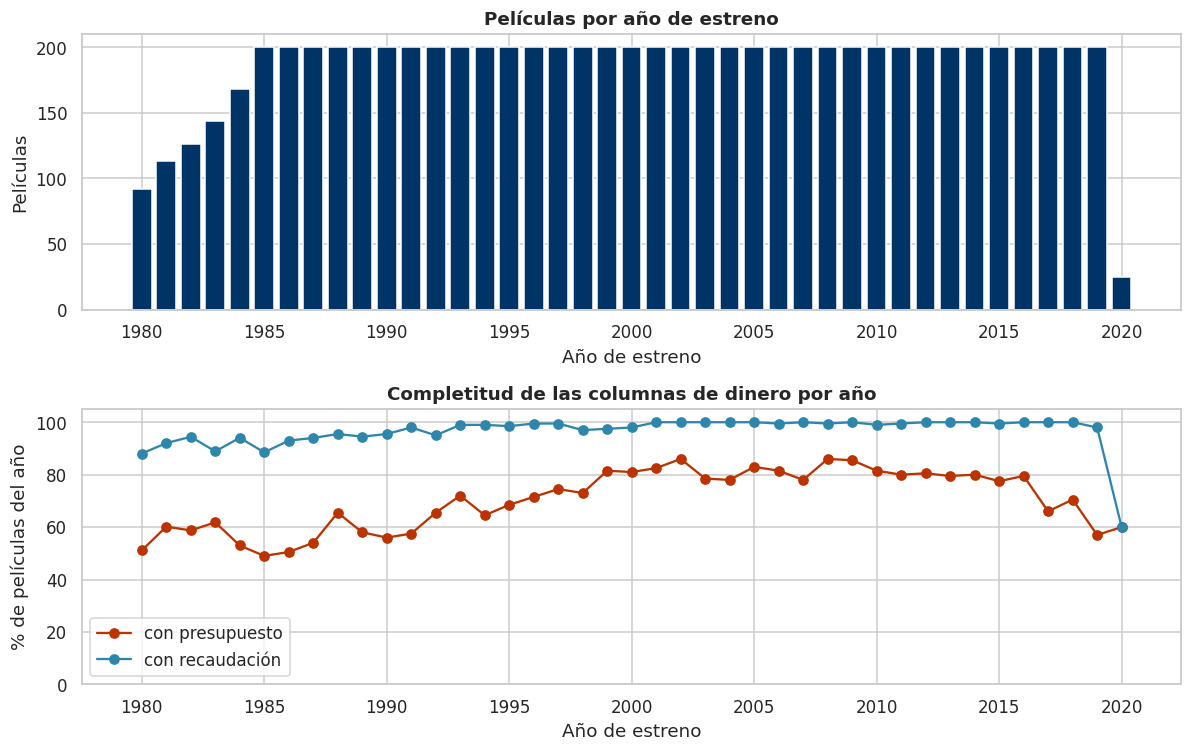

              peliculas  pct_con_presupuesto  pct_con_recaudacion
anio_estreno                                                     
1980                 92                51.10                88.00
1981                113                60.20                92.00
1982                126                58.70                94.40
1983                144                61.80                88.90
1984                168                53.00                94.00
1985                200                49.00                88.50
2000                200                81.00                98.00
2019                200                57.00                98.00
2020                 25                60.00                60.00


In [44]:
cobertura = peliculas.groupby("anio_estreno").agg(
    peliculas=("id_pelicula", "size"),
    pct_con_presupuesto=("presupuesto_usd", lambda serie: serie.notna().mean() * 100),
    pct_con_recaudacion=("recaudacion_mundial_usd", lambda serie: serie.notna().mean() * 100),
)

figura, (eje_cantidad, eje_completitud) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

# Primer gráfico
eje_cantidad.bar(cobertura.index, cobertura["peliculas"], color=AZUL)
eje_cantidad.set_title("Películas por año de estreno")
eje_cantidad.set_ylabel("Películas")
eje_cantidad.set_xlabel("Año de estreno")
eje_cantidad.tick_params(axis="x", labelbottom=True)

# Segundo gráfico
eje_completitud.plot(cobertura.index, cobertura["pct_con_presupuesto"], color=ROJO, marker="o", label="con presupuesto")
eje_completitud.plot(cobertura.index, cobertura["pct_con_recaudacion"], color=CELESTE, marker="o", label="con recaudación")
eje_completitud.set_title("Completitud de las columnas de dinero por año")
eje_completitud.set_ylabel("% de películas del año")
eje_completitud.set_xlabel("Año de estreno")
eje_completitud.set_ylim(0, 105)
eje_completitud.legend()

figura.tight_layout()
guardar_figura(figura, "01_cobertura_temporal.png")
plt.show()

print(cobertura.loc[[1980, 1981, 1982, 1983, 1984, 1985, 2000, 2019, 2020]].round(1).to_string())


**Conclusión.** La base **no** está igual de completa en todos los años:

- **1980-1984** tienen menos películas (92 a 168 por año, contra ~200 desde 1985): la base arranca "construyéndose".
- **2020** tiene solo 25 películas: el año está incompleto y además los cines cerraron por la pandemia. Lo excluimos de
  las series temporales y en la validación (Etapa 6) mostramos que sacarlo no cambia nada.
- **La completitud del presupuesto cambia con el tiempo**: ~50-60% en los 80, 81% en 2000, 57% en 2019. Esto ya
  sugiere que los faltantes no son al azar, que es lo que analizamos a continuación.

<h2 style='font-weight:bold; color:#003366;'>1.9 Películas sin presupuesto: ¿grupo cualquiera o faltan por una razón?</h2>

Si faltan **al azar**, descartarlas solo reduce el tamaño de la muestra. Si faltan **en un grupo en particular**,
descartarlas sesga las conclusiones justo en ese grupo. Comparamos la tasa de faltantes por década, país y género, y
además miramos si las películas sin presupuesto son distintas en lo que sí sabemos de ellas (recaudación y votos).

In [45]:
peliculas["decada"] = (peliculas["anio_estreno"] // 10 * 10).astype(int)
peliculas["origen"] = np.select(
    [peliculas["pais_origen"].isna(), peliculas["pais_origen"].eq("Estados Unidos").fillna(False).astype(bool)],
    ["Sin dato", "Estados Unidos"], default="Resto del mundo")
peliculas["falta_presupuesto"] = peliculas["presupuesto_usd"].isna()


def tasa_faltante(por: str, minimo: int = 30) -> pd.DataFrame:
    """Porcentaje de películas sin presupuesto por grupo (solo grupos con al menos `minimo` películas)."""
    tabla = peliculas.groupby(por).agg(peliculas=("falta_presupuesto", "size"),
                                       pct_sin_presupuesto=("falta_presupuesto", "mean"))
    tabla["pct_sin_presupuesto"] *= 100
    return tabla[tabla["peliculas"] >= minimo].sort_values("pct_sin_presupuesto", ascending=False)


print(f"Sin presupuesto en toda la base: {peliculas['falta_presupuesto'].mean():.1%} "
      f"(2020, con solo 25 películas, no entra en la tabla por década: {peliculas.loc[peliculas['decada'] == 2020, 'falta_presupuesto'].mean():.0%})\n")
for variable in ["decada", "origen", "genero"]:
    tabla = tasa_faltante(variable)
    contingencia = pd.crosstab(peliculas[variable], peliculas["falta_presupuesto"])
    chi2, valor_p, _, _ = stats.chi2_contingency(contingencia)
    print(f"--- por {variable} (test chi-cuadrado de independencia: p {formatear_p(valor_p)}) ---")
    print(tabla.round(1).to_string(), "\n")

Sin presupuesto en toda la base: 28.9% (2020, con solo 25 películas, no entra en la tabla por década: 40%)

--- por decada (test chi-cuadrado de independencia: p < 0,001) ---
        peliculas  pct_sin_presupuesto
decada                                
1980         1643                43.90
1990         2000                31.60
2010         2000                24.80
2000         2000                18.00 

--- por origen (test chi-cuadrado de independencia: p < 0,001) ---
                 peliculas  pct_sin_presupuesto
origen                                         
Resto del mundo       2190                49.40
Estados Unidos        5475                20.70 

--- por genero (test chi-cuadrado de independencia: p < 0,001) ---
           peliculas  pct_sin_presupuesto
genero                                   
Drama           1518                42.50
Comedia         2245                33.50
Biografía        443                28.90
Policial         551                26.90
Aventura 

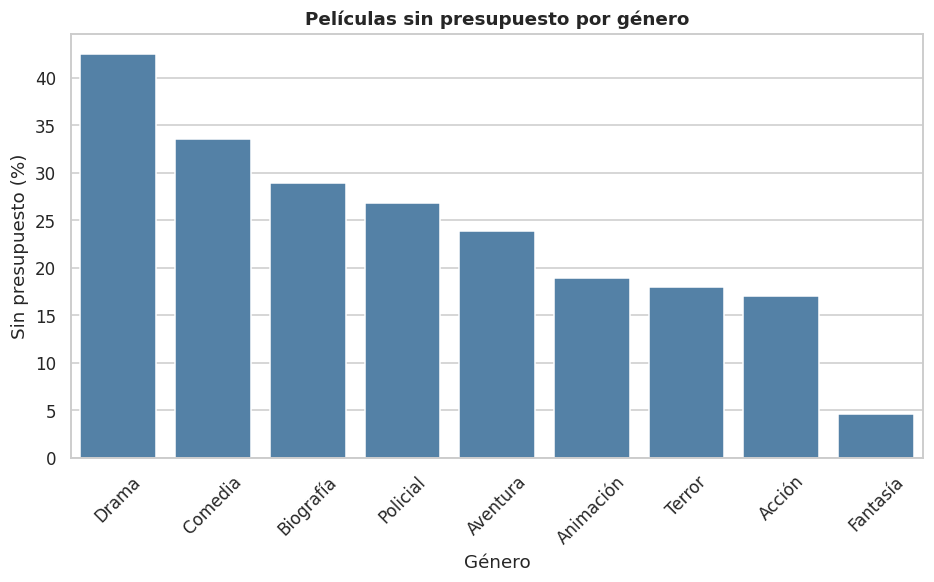

In [46]:
#Grafico Cantidad de películas y porcentaje sin presupuesto por género
faltantes_genero = peliculas.groupby("genero").agg(
    cantidad=("id_pelicula", "size"),
    porcentaje=("falta_presupuesto", "mean")
)

# Dejamos géneros con al menos 30 películas
faltantes_genero = faltantes_genero[faltantes_genero["cantidad"] >= 30]

# Pasamos a porcentaje y ordenamos
faltantes_genero["porcentaje"] = faltantes_genero["porcentaje"] * 100
faltantes_genero = faltantes_genero.sort_values("porcentaje", ascending=False)

# Gráfico
plt.figure(figsize=(10, 5))
sns.barplot(
    x=faltantes_genero.index,
    y=faltantes_genero["porcentaje"],
    color="steelblue"
)

plt.title("Películas sin presupuesto por género")
plt.xlabel("Género")
plt.ylabel("Sin presupuesto (%)")
plt.xticks(rotation=45)
plt.show()



**Conclusión:** El porcentaje de películas sin presupuesto cambia bastante según el género. Drama y Comedia tienen más datos faltantes que Acción y Terror.

Esto es importante porque, al excluir las películas sin presupuesto del análisis de rentabilidad, algunos géneros van a perder más películas que otros. Por eso, tenemos que tener cuidado al comparar sus resultados.

In [47]:
print("Top países con más películas: % sin presupuesto")
print(tasa_faltante("pais_origen", minimo=40).round(1).to_string())

# ¿Son películas distintas? Comparamos lo que sí sabemos de ellas
comparacion = peliculas.assign(
    recaudacion_mm=peliculas["recaudacion_mundial_usd"] / 1e6
).groupby("falta_presupuesto").agg(
    peliculas=("id_pelicula", "size"),
    recaudacion_mediana_mm=("recaudacion_mm", "median"),
    votos_mediana=("cantidad_votos", "median"),
    puntaje_imdb_mediano=("puntaje_imdb", "median"),
    pct_secuela=("es_secuela", "mean"),
)
_, valor_p = stats.mannwhitneyu(
    peliculas.loc[peliculas["falta_presupuesto"], "recaudacion_mundial_usd"].dropna(),
    peliculas.loc[~peliculas["falta_presupuesto"], "recaudacion_mundial_usd"].dropna())
print(f"\nRecaudación de las películas con y sin presupuesto (Mann-Whitney p {formatear_p(valor_p)}):")
print(comparacion.round(2).to_string())

print("\n% sin presupuesto por cuartil de votos en IMDb (visibilidad de la película):")
print(peliculas.groupby(pd.qcut(peliculas["cantidad_votos"], 4,
                                labels=["Q1 (menos votadas)", "Q2", "Q3", "Q4 (más votadas)"]),
                        observed=True)["falta_presupuesto"].mean().mul(100).round(1).to_string())

# ¿Qué parte del dinero de la industria queda dentro del análisis?
recaudacion_con_dato = peliculas.loc[~peliculas["falta_presupuesto"], "recaudacion_mundial_usd"].sum()
print(f"\nLas películas CON presupuesto concentran el "
      f"{recaudacion_con_dato / peliculas['recaudacion_mundial_usd'].sum():.1%} de la recaudación total de la base.")

Top países con más películas: % sin presupuesto
                peliculas  pct_sin_presupuesto
pais_origen                                   
India                  62                85.50
Italia                 61                68.90
España                 47                63.80
Francia               279                62.40
Japón                  81                60.50
Australia              92                54.30
Irlanda                43                51.20
Hong Kong              45                44.40
Canadá                190                40.50
Reino Unido           816                40.00
China                  40                37.50
Alemania              129                35.70
Estados Unidos       5475                20.70

Recaudación de las películas con y sin presupuesto (Mann-Whitney p < 0,001):
                   peliculas  recaudacion_mediana_mm  votos_mediana  puntaje_imdb_mediano  pct_secuela
falta_presupuesto                                                 

In [48]:
# Decisión: las películas sin presupuesto se EXCLUYEN del análisis de retorno, pero NO de la base.
#  - El retorno es recaudación / presupuesto: sin denominador no hay retorno que medir.
#  - Imputar el presupuesto (con la mediana del género, por ejemplo) inventaría el denominador y, con él,
#    el resultado que queremos medir. Además faltan en películas chicas: la mediana de las que sí tienen
#    dato les asignaría un presupuesto demasiado alto y fabricaría pérdidas falsas.
#  - Se mantienen para lo que no necesita presupuesto (evolución de la recaudación en 3.1).
sin_presupuesto = int(peliculas["falta_presupuesto"].sum())
sin_recaudacion_con_presupuesto = int((~peliculas["falta_presupuesto"] & peliculas["recaudacion_mundial_usd"].isna()).sum())
print(bitacora.registrar(
    paso="1.9", accion="Excluir del análisis de retorno: sin presupuesto", filas_afectadas=sin_presupuesto,
    filas_antes=len(peliculas), filas_despues=len(peliculas) - sin_presupuesto,
    justificacion="Sin denominador no hay retorno; imputar inventaría el resultado. Faltan con patrón (ver 1.9)."))
print(bitacora.registrar(
    paso="1.9", accion="Excluir del análisis de retorno: con presupuesto pero sin recaudación",
    filas_afectadas=sin_recaudacion_con_presupuesto, filas_antes=len(peliculas) - sin_presupuesto,
    filas_despues=len(peliculas) - sin_presupuesto - sin_recaudacion_con_presupuesto,
    justificacion="Sin numerador no hay retorno. No se asume recaudación 0: no sabemos si se estrenó en salas."))

[1.9] Excluir del análisis de retorno: sin presupuesto: 2,219 filas (28.94% de la base)
[1.9] Excluir del análisis de retorno: con presupuesto pero sin recaudación: 60 filas (1.10% de la base)


### Conclusión

Los presupuestos faltantes no se distribuyen de la misma manera entre todas las películas. Los tests chi-cuadrado muestran diferencias significativas (p < 0,001).

- **Por década:** en los años 80 falta el 44% de los presupuestos, frente al 18% en los 2000.
- **Por país:** fuera de Estados Unidos falta el 49%, mientras que en Estados Unidos falta el 21%.
- **Por género:** Drama (43%) y Comedia (34%) tienen más datos faltantes que Acción (17%) y Terror (18%).
- **Por popularidad:** las películas sin presupuesto recaudaron una mediana de USD 4 millones, frente a USD 37 millones de las que sí tienen presupuesto. También tienen muchos menos votos en IMDb.

**Decisión:** excluimos las películas sin presupuesto del cálculo de rentabilidad, porque no podemos calcular el retorno sin conocer cuánto costaron. No vamos a estimar los presupuestos, ya que esto podría alterar los resultados. Sin embargo, mantenemos estas películas para los análisis que no necesitan esa información.

**Efecto sobre las conclusiones:**

Como los faltantes se concentran en películas con menor recaudación y popularidad, los resultados pueden favorecer a las películas más conocidas y comerciales.

Además, las películas con presupuesto registrado concentran el 93,8% de la recaudación total de la base. Esto hace que nuestro análisis sea relevante para estudiar gran parte de la actividad comercial registrada, aunque no represente necesariamente a todas las películas de la industria.

Por eso, al elegir nuestro portafolio, tenemos que tener en cuenta que los resultados pueden ser menos representativos para películas pequeñas, de bajo perfil o de determinados géneros y países.

<h2 style='font-weight:bold; color:#003366;'>Bitácora de limpieza: resumen de todas las decisiones</h2>

In [49]:
tabla_bitacora = bitacora.como_tabla()
tabla_bitacora.to_csv(CARPETA_SALIDAS / "bitacora_limpieza.csv", index=False)
print(f"Base original: {bitacora.filas_originales:,} filas -> base limpia: {len(peliculas):,} películas únicas")
tabla_bitacora.style.format({"pct_de_la_base": "{:.2%}", "filas_afectadas": "{:,}",
                             "filas_antes": "{:,}", "filas_despues": "{:,}"}).hide(axis="index")

Base original: 7,740 filas -> base limpia: 7,668 películas únicas


paso,accion,filas_afectadas,pct_de_la_base,filas_antes,filas_despues,justificacion
1.3,Borrar duplicados exactos,58,0.75%,"7,740","7,682",Misma fila repetida (mismo id y valores); duplicaría el peso de esas películas.
1.3,Borrar versión alterada de películas repetidas (id >= 90000),14,0.18%,"7,682","7,668",Mismo título/año/director; la versión 90xxx tiene id fuera de secuencia y presupuesto no redondeado.
1.5,Presupuesto -1 y 0 -> NaN (centinela),48,0.63%,"7,668","7,668",Centinela de faltante; dejarlo daría múltiplos infinitos o negativos.
1.5,Recaudación negativa -> valor absoluto (error de signo),11,0.14%,"7,668","7,668",La magnitud coincide con recaudaciones reales conocidas; solo el signo está mal.
1.5,Duración 0 y 999 -> NaN (centinela),34,0.44%,"7,668","7,668",0 y 999 minutos no son duraciones posibles; las largas reales se mantienen.
1.5,Puntaje IMDb 0 -> NaN (fuera de escala),22,0.29%,"7,668","7,668","La escala de IMDb es 1-10; tienen miles de votos, así que el 0 es un faltante."
1.6,Presupuesto en miles -> x 1.000,39,0.51%,"7,668","7,668",Múltiplo > 100 con presupuesto < 1 MM y sin ser micropresupuesto documentado.
1.7,Unificar variantes de clasificacion,884,11.53%,"7,668","7,668","Mayúsculas, tildes, espacios y sinónimos partían la misma categoría en varias."
1.7,Unificar variantes de pais_origen,776,10.12%,"7,668","7,668","Mayúsculas, tildes, espacios y sinónimos partían la misma categoría en varias."
1.7,Unificar variantes de genero,696,9.08%,"7,668","7,668","Mayúsculas, tildes, espacios y sinónimos partían la misma categoría en varias."


### Conclusión de la limpieza

Partimos de una base de 7.740 registros y, después de eliminar duplicados, quedaron 7.668 películas únicas.

También corregimos valores incorrectos, presupuestos cargados en otra escala y diferencias en los nombres de las categorías.

Para el análisis de rentabilidad utilizamos 5.389 películas que tienen presupuesto y recaudación disponibles. Las demás se mantienen en la base para los análisis que no necesitan esos datos.

De esta manera, trabajamos con información más consistente y dejamos registradas todas las decisiones de limpieza.

# Etapa 2 · Creación de variables

## 2.1 Presupuesto y recaudación en dólares constantes de 2020

**Qué hace la operación.** Un dólar de 1985 compraba más cosas que un dólar de 2020. Para comparar montos de años
distintos hay que llevarlos a la misma "moneda". Usamos el IPC de Estados Unidos (CPI-U):

$$\text{monto en USD de 2020} = \text{monto nominal} \times \frac{\text{IPC}_{2020}}{\text{IPC}_{\text{año de estreno}}}$$

El cociente de índices es cuántos dólares de 2020 hacen falta para comprar lo mismo que compraba un dólar del año de
estreno. Usamos `anio_estreno` (y no el año de `fecha_estreno`) porque el diccionario de datos dice que los montos
están en dólares del año de estreno; la diferencia entre ambas columnas se discutió en 1.5.

In [50]:
ipc_por_anio = ipc.set_index("anio")["ipc_eeuu"]
factor_a_2020 = ipc_por_anio[ANIO_BASE_PRECIOS] / ipc_por_anio
print("Factor para llevar a dólares de 2020 (años seleccionados):")
print(factor_a_2020.loc[[1980, 1985, 1990, 2000, 2010, 2020]].round(3).to_string())
print(f"\nEjemplo: USD 10 MM de 1985 equivalen a USD {10 * factor_a_2020[1985]:.1f} MM de 2020.")

peliculas["presupuesto_real"] = deflactar(peliculas["presupuesto_usd"], peliculas["anio_estreno"],
                                          ipc_por_anio, ANIO_BASE_PRECIOS)
peliculas["recaudacion_real"] = deflactar(peliculas["recaudacion_mundial_usd"], peliculas["anio_estreno"],
                                          ipc_por_anio, ANIO_BASE_PRECIOS)

# Verificación: en 2020 el monto real tiene que ser igual al nominal
es_2020 = peliculas["anio_estreno"] == ANIO_BASE_PRECIOS
assert np.allclose(peliculas.loc[es_2020, "recaudacion_real"].dropna(),
                   peliculas.loc[es_2020, "recaudacion_mundial_usd"].dropna())
peliculas.loc[peliculas["titulo"].isin(["Back to the Future Part II", "Avatar", "Joker"]),
              ["titulo", "anio_estreno", "presupuesto_usd", "presupuesto_real",
               "recaudacion_mundial_usd", "recaudacion_real"]]

Factor para llevar a dólares de 2020 (años seleccionados):
anio
1980   3.14
1985   2.40
1990   1.98
2000   1.50
2010   1.19
2020   1.00

Ejemplo: USD 10 MM de 1985 equivalen a USD 24.1 MM de 2020.


,titulo,anio_estreno,presupuesto_usd,presupuesto_real,recaudacion_mundial_usd,recaudacion_real
545,Avatar,2009,"237,000,000.00","285,946,853.15","2,847,246,203.00","3,435,278,868.70"
5996,Back to the Future Part II,1989,"40,000,000.00","83,483,870.97","332,500,002.00","693,959,681.59"
6812,Joker,2019,NaN,NaN,"1,074,427,370.00","1,087,453,278.67"


<h2 style='font-weight:bold; color:#003366;'>2.2 Retorno sobre la inversión y recupero según la regla del 2,5×</h2>

Construimos cuatro variables que miden lo mismo desde ángulos distintos:

| Variable | Fórmula | Para qué sirve |
|---|---|---|
| `multiplo_bruto` | recaudación real / presupuesto real | Cuántas veces "volvió" el presupuesto en boletería. Es lo que un análisis ingenuo llama retorno. |
| `roi_bruto` | múltiplo − 1 | El ROI bruto clásico (0,5 = 50%). **No es ganancia**: ignora la parte del exhibidor y el marketing. |
| `recupero_inversion` | múltiplo ≥ 2,5 | La regla de la industria: por debajo de 2,5× la película perdió plata en salas. |
| `retorno_neto` | múltiplo / 2,5 − 1 | Retorno estimado **para el inversor**: vale 0 justo en el umbral, −1 si no recaudó nada y +1 si recaudó 5×. Es la variable que usamos para riesgo y portafolio. |

¿Por qué 2,5×? De cada dólar de boletería el estudio recibe ~0,5, y además gasta en marketing entre 50% y 100% del
presupuesto. La regla de 2,5× es la convención de la industria; en la sección 7 probamos umbrales más exigentes (3× y
4×) que equivalen a suponer marketing al 50% y al 100% sin otros ingresos.

Notas de las ratios: real/real = nominal/nominal (ambos se deflactan con el mismo IPC del año), así que el múltiplo no
cambia al deflactar; lo que sí cambia es el **tramo de presupuesto** en el que cae cada película y cualquier
comparación de montos entre años.

In [51]:
peliculas["multiplo_bruto"] = peliculas["recaudacion_real"] / peliculas["presupuesto_real"]
peliculas["roi_bruto"] = peliculas["multiplo_bruto"] - 1
# Tipo "boolean" de pandas: admite faltante. Sin esto, una película sin múltiplo contaría como pérdida.
peliculas["recupero_inversion"] = (
    (peliculas["multiplo_bruto"] >= UMBRAL_RECUPERO).astype("boolean").mask(peliculas["multiplo_bruto"].isna())
)
peliculas["retorno_neto"] = peliculas["multiplo_bruto"] / UMBRAL_RECUPERO - 1

print(peliculas[["multiplo_bruto", "roi_bruto", "retorno_neto"]].describe(percentiles=[0.1, 0.5, 0.9]).T.to_string())

                  count  mean    std   min   10%   50%  90%       max
multiplo_bruto 5,389.00  6.73 184.64  0.00  0.27  1.83 7.09 12,890.39
roi_bruto      5,389.00  5.73 184.64 -1.00 -0.73  0.83 6.09 12,889.39
retorno_neto   5,389.00  1.69  73.86 -1.00 -0.89 -0.27 1.84  5,155.15


<h2 style='font-weight:bold; color:#003366;'>2.3 Otras variables útiles para el análisis</h2>

In [52]:
# Tramo de presupuesto en dólares de 2020 (comparable entre épocas)
peliculas["tramo_presupuesto"] = pd.cut(peliculas["presupuesto_real"], bins=TRAMOS_PRESUPUESTO_USD,
                                        labels=ETIQUETAS_TRAMO, right=False)

# Clasificación agrupada por público: es la forma en que la industria piensa el mercado potencial
GRUPO_CLASIFICACION = {"ATP": "Familiar", "Supervisión parental": "Familiar",
                       "Mayores de 13": "Adolescente (13+)", "Mayores de 17": "Adulto (17+)",
                       "Solo adultos": "Adulto (17+)", "Sin clasificar": "Sin clasificar"}
peliculas["publico"] = peliculas["clasificacion"].map(GRUPO_CLASIFICACION).fillna("Sin dato")

# Géneros con pocas películas se agrupan: con menos de 30 casos no se puede concluir nada
peliculas_con_retorno = peliculas["multiplo_bruto"].notna()
conteo_generos = peliculas.loc[peliculas_con_retorno, "genero"].value_counts()
generos_chicos = conteo_generos[conteo_generos < MINIMO_PELICULAS_SEGMENTO].index
peliculas["genero_analisis"] = peliculas["genero"].where(~peliculas["genero"].isin(generos_chicos), "Otros")
print("Géneros agrupados en 'Otros':", list(generos_chicos))

# Estudios grandes (majors y sus sellos) contra el resto
MAJORS = ["Universal Pictures", "Warner Bros.", "Columbia Pictures", "Paramount Pictures",
          "Twentieth Century Fox", "20th Century Studios", "Walt Disney Pictures", "Touchstone Pictures",
          "Hollywood Pictures", "Metro-Goldwyn-Mayer (MGM)", "TriStar Pictures", "New Line Cinema",
          "DreamWorks Pictures", "Dreamworks Pictures", "Fox 2000 Pictures", "Walt Disney Animation Studios",
          "Pixar Animation Studios", "Marvel Studios", "DreamWorks Animation", "Screen Gems"]
peliculas["es_major"] = peliculas["productora"].isin(MAJORS)

# Temporada de estreno: verano (may-ago) y fiestas (nov-dic) son las ventanas de los tanques
mes = peliculas["fecha_estreno"].dt.month
peliculas["temporada"] = np.select([mes.between(5, 8), mes.between(11, 12)],
                                   ["Verano (may-ago)", "Fiestas (nov-dic)"], default="Resto del año")
peliculas["epoca"] = pd.cut(peliculas["anio_estreno"], bins=[1979, 1989, 1999, 2009, 2014, 2020],
                            labels=["1980s", "1990s", "2000s", "2010-14", "2015-20"])

# Base analítica: las películas con retorno calculable
base = peliculas[peliculas_con_retorno].copy()
base["recupero_inversion"] = base["recupero_inversion"].astype(bool)  # en la base analítica no hay faltantes
print(f"\nBase analítica de retorno: {len(base):,} películas ({len(base) / len(peliculas):.1%} de la base limpia)")
print(f"Recuperaron la inversión (>= {UMBRAL_RECUPERO}x): {base['recupero_inversion'].mean():.1%}")
base[["titulo", "anio_estreno", "genero_analisis", "tramo_presupuesto", "publico", "es_secuela",
      "multiplo_bruto", "retorno_neto", "recupero_inversion"]].head()

Géneros agrupados en 'Otros': ['Misterio', 'Suspenso', 'Ciencia ficción', 'Romance', 'Familiar', 'Western']

Base analítica de retorno: 5,389 películas (70.3% de la base limpia)
Recuperaron la inversión (>= 2.5x): 38.8%


,titulo,anio_estreno,genero_analisis,tramo_presupuesto,publico,es_secuela,multiplo_bruto,retorno_neto,recupero_inversion
0,Hatchet II,2010,Acción,Bajo (<10 MM),Adulto (17+),True,0.20,-0.92,False
1,Shanghai Surprise,1986,Aventura,Alto (40-100 MM),Adolescente (13+),False,0.14,-0.95,False
2,Mr. Magorium's Wonder Emporium,2007,Comedia,Alto (40-100 MM),Familiar,False,1.07,-0.57,False
4,Kafka,1991,Drama,Medio (10-40 MM),Adolescente (13+),False,0.10,-0.96,False
6,Re-Animator,1985,Comedia,Bajo (<10 MM),Sin clasificar,False,2.25,-0.10,False


### Conclusión

Después de la limpieza, nos quedan **5.389 películas** (70% de la base) para analizar la rentabilidad.

Encontramos una diferencia importante entre el múltiplo promedio (6,7×) y el mediano (1,8×). Esto se debe a que algunas películas tienen recaudaciones extraordinariamente altas que aumentan mucho el promedio.

Además, solamente el **38,8% de las películas recuperó su inversión**, según la regla del 2,5×. El retorno neto mediano fue de −27%, lo que significa que más de la mitad de las películas analizadas no recuperaron su inversión.

Por eso, para decidir dónde invertir, vamos a utilizar principalmente medianas, probabilidades de pérdida y otras medidas de riesgo, en lugar de guiarnos solamente por el promedio.

#Etapa 3 · Análisis de negocio

#3.1 ¿La industria creció?

Para esta pregunta usamos **todas** las películas con recaudación (no hace falta el presupuesto). Excluimos 2020 de la
serie: tiene 25 películas y la pandemia cerró los cines, no es comparable.

In [53]:
serie_anual = (
    peliculas[peliculas["anio_estreno"] < 2020]
    .groupby("anio_estreno")
    .agg(recaudacion_mediana_nominal=("recaudacion_mundial_usd", "median"),
         recaudacion_mediana_real=("recaudacion_real", "median"),
         peliculas=("recaudacion_mundial_usd", "count"))
)
serie_decada = (
    peliculas[peliculas["anio_estreno"] < 2020]
    .groupby("decada")
    .agg(nominal_mm=("recaudacion_mundial_usd", lambda serie: serie.median() / 1e6),
         real_2020_mm=("recaudacion_real", lambda serie: serie.median() / 1e6))
)
serie_decada["variacion_nominal_vs_1980s"] = serie_decada["nominal_mm"] / serie_decada["nominal_mm"].iloc[0] - 1
serie_decada["variacion_real_vs_1980s"] = serie_decada["real_2020_mm"] / serie_decada["real_2020_mm"].iloc[0] - 1
print("Recaudación mediana por película, por década (USD millones):")
serie_decada.style.format({"nominal_mm": "{:.1f}", "real_2020_mm": "{:.1f}",
                           "variacion_nominal_vs_1980s": "{:+.0%}", "variacion_real_vs_1980s": "{:+.0%}"})

Recaudación mediana por película, por década (USD millones):


,nominal_mm,real_2020_mm,variacion_nominal_vs_1980s,variacion_real_vs_1980s
decada,,,,
1980,8.6,20.9,+0%,+0%
1990,12.9,22.1,+49%,+6%
2000,40.4,53.4,+369%,+155%
2010,41.7,45.8,+383%,+119%


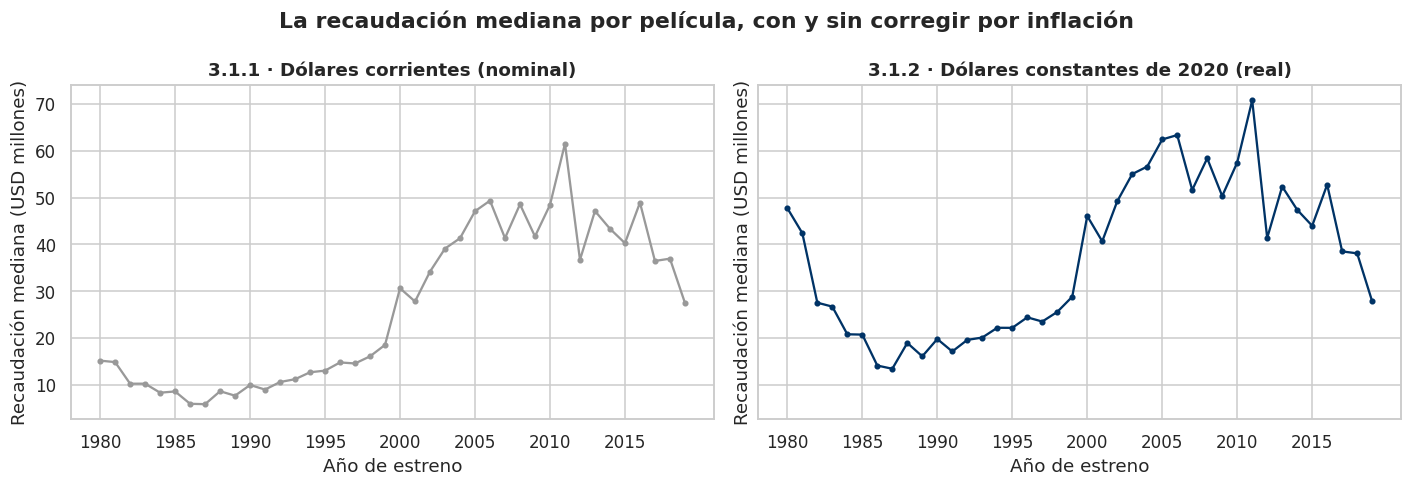

Crecimiento anual tendencial (log-lineal) 1980-2019: nominal +5.5% | real +2.6% | inflación promedio 2.9%


In [54]:
figura, ejes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
ejes[0].plot(serie_anual.index, serie_anual["recaudacion_mediana_nominal"], color=GRIS, marker="o", markersize=3)
ejes[0].set_title("3.1.1 · Dólares corrientes (nominal)")
ejes[1].plot(serie_anual.index, serie_anual["recaudacion_mediana_real"], color=AZUL, marker="o", markersize=3)
ejes[1].set_title("3.1.2 · Dólares constantes de 2020 (real)")
for eje in ejes:
    eje.set_xlabel("Año de estreno")
    eje.yaxis.set_major_formatter(mticker.FuncFormatter(formato_millones))
figura.suptitle("La recaudación mediana por película, con y sin corregir por inflación", fontweight="bold")

for eje in ejes:
    eje.set_xticks(range(1980, 2020, 5))
    eje.set_ylabel("Recaudación mediana (USD millones)")
    eje.tick_params(axis="x", labelbottom=True)

figura.tight_layout()
plt.show()

tendencia_nominal = np.polyfit(serie_anual.index, np.log(serie_anual["recaudacion_mediana_nominal"]), 1)[0]
tendencia_real = np.polyfit(serie_anual.index, np.log(serie_anual["recaudacion_mediana_real"]), 1)[0]
inflacion_anual = (ipc_por_anio[2019] / ipc_por_anio[1980]) ** (1 / 39) - 1
print(f"Crecimiento anual tendencial (log-lineal) 1980-2019: nominal {np.expm1(tendencia_nominal):+.1%} | "
      f"real {np.expm1(tendencia_real):+.1%} | inflación promedio {inflacion_anual:.1%}")

### 3.1.3 Conclusión: ¿La industria creció?

Al comparar la recaudación de las películas a lo largo de los años, vemos que **la industria creció, pero no tanto como parece al principio**.

En dólares nominales, la recaudación mediana por película aumentó un **383% entre los años 80 y los 2010**, con un crecimiento anual del 5,5%. Sin embargo, una parte importante de este aumento se explica por la inflación.

Cuando ajustamos los valores a dólares de 2020, el crecimiento es menor: **119% entre ambas décadas, con un crecimiento anual del 2,6%**. Además, vemos que la recaudación real alcanzó su máximo en los años 2000 y después disminuyó en los 2010.

Es importante tener en cuenta que estamos analizando la recaudación mediana de las películas de nuestra base, no los ingresos totales de la industria.

**¿Qué significa esto para nuestro fondo?** No podemos asumir que una película será más rentable simplemente por estrenarse en una época más reciente. Para decidir dónde invertir, necesitamos analizar también el presupuesto, el género y el riesgo de pérdida de cada tipo de película.

#3.2 ¿Cuánto rinde cada tipo de película?

3.2.4 Retorno medio y mediano por género

In [55]:
from matplotlib.ticker import PercentFormatter
por_genero = resumir_retorno(base, "genero_analisis").sort_values("multiplo_mediano", ascending=False)
por_genero.style.format({
    "peliculas": "{:,}", "multiplo_medio": "{:.2f}x", "multiplo_mediano": "{:.2f}x",
    "retorno_neto_mediano": "{:+.0%}", "prob_perdida": "{:.0%}", "retorno_peor_decil": "{:+.0%}",
    "retorno_mejor_decil": "{:+.0%}", "presupuesto_mediano_mm": "{:.1f}", "media_sobre_mediana": "{:.1f}"
}).background_gradient(subset=["media_sobre_mediana"], cmap="Reds")

,peliculas,multiplo_medio,multiplo_mediano,retorno_neto_mediano,prob_perdida,retorno_peor_decil,retorno_mejor_decil,presupuesto_mediano_mm,media_sobre_mediana
genero_analisis,,,,,,,,,
Terror,254,76.86x,3.08x,+23%,42%,-83%,+772%,12.4,25.0
Animación,273,4.00x,2.92x,+17%,42%,-75%,+220%,82.5,1.4
Fantasía,42,2.52x,2.14x,-14%,57%,-89%,+100%,16.1,1.2
Acción,"1,405",2.92x,1.87x,-25%,62%,-85%,+118%,56.2,1.6
Aventura,323,3.14x,1.83x,-27%,61%,-91%,+169%,46.1,1.7
Otros,41,4.41x,1.83x,-27%,61%,-96%,+143%,31.1,2.4
Comedia,"1,479",3.57x,1.78x,-29%,62%,-89%,+193%,26.4,2.0
Drama,862,3.74x,1.53x,-39%,63%,-94%,+227%,24.5,2.4
Biografía,312,2.71x,1.48x,-41%,68%,-90%,+175%,27.0,1.8


La columna `media_sobre_mediana` es el hallazgo: en **Terror** el múltiplo promedio es decenas de veces la mediana.
Buscamos qué películas están rompiendo el promedio.

In [56]:
columnas_outlier = ["titulo", "anio_estreno", "genero", "presupuesto_usd", "recaudacion_mundial_usd", "multiplo_bruto"]
print("Las 12 películas con mayor múltiplo de toda la base:")
display(base.nlargest(12, "multiplo_bruto")[columnas_outlier])

terror = base[base["genero_analisis"] == "Terror"]
dos_mayores = terror.nlargest(2, "multiplo_bruto")
sin_dos_mayores = terror.drop(dos_mayores.index)
print(f"Terror: {len(terror)} películas")
print(f"  Múltiplo medio con todas:                 {terror['multiplo_bruto'].mean():6.1f}x")
print(f"  Múltiplo medio sin {dos_mayores['titulo'].tolist()}: {sin_dos_mayores['multiplo_bruto'].mean():6.1f}x")
print(f"  Múltiplo mediano con todas:               {terror['multiplo_bruto'].median():6.2f}x")
print(f"  Múltiplo mediano sin esas dos:            {sin_dos_mayores['multiplo_bruto'].median():6.2f}x")
print(f"  Peso de esas 2 películas en la suma de múltiplos del género: "
      f"{dos_mayores['multiplo_bruto'].sum() / terror['multiplo_bruto'].sum():.0%}")

Las 12 películas con mayor múltiplo de toda la base:


,titulo,anio_estreno,genero,presupuesto_usd,recaudacion_mundial_usd,multiplo_bruto
5927,Paranormal Activity,2007,Terror,"15,000.00","193,355,800.00","12,890.39"
1648,The Blair Witch Project,1999,Terror,"60,000.00","248,639,099.00","4,143.98"
4740,The Gallows,2015,Terror,"100,000.00","42,964,410.00",429.64
5949,El Mariachi,1992,Acción,"7,000.00","2,040,920.00",291.56
6151,Once,2007,Drama,"150,000.00","20,936,722.00",139.58
233,Clerks,1994,Comedia,"27,000.00","3,151,130.00",116.71
3277,Napoleon Dynamite,2004,Comedia,"400,000.00","46,138,887.00",115.35
4461,In the Company of Men,1997,Comedia,"25,000.00","2,804,473.00",112.18
5520,Open Water,2003,Aventura,"500,000.00","54,683,487.00",109.37
7376,The Devil Inside,2012,Terror,"1,000,000.00","101,758,490.00",101.76


Terror: 254 películas
  Múltiplo medio con todas:                   76.9x
  Múltiplo medio sin ['Paranormal Activity', 'The Blair Witch Project']:    9.9x
  Múltiplo mediano con todas:                 3.08x
  Múltiplo mediano sin esas dos:              3.05x
  Peso de esas 2 películas en la suma de múltiplos del género: 87%


**Análisis de películas con retornos extremos.** En el género terror encontramos películas con retornos extraordinariamente altos, como *Paranormal Activity* y *The Blair Witch Project*. Estas dos películas hacen que el múltiplo promedio sea de 76,9×, pero al excluirlas baja a 9,9×. En cambio, la mediana prácticamente no cambia (de 3,08× a 3,05×).

Esto demuestra que unas pocas películas muy exitosas pueden distorsionar el promedio. Por eso, **utilizamos la mediana para comparar la rentabilidad de los géneros**, sin eliminar estas películas de la base.

In [57]:
# ¿Las diferencias entre géneros son reales o ruido? Test de Kruskal-Wallis (no paramétrico, compara medianas
# sin suponer normalidad) e intervalos de confianza por bootstrap de la mediana.
grupos = [grupo["multiplo_bruto"].to_numpy() for _, grupo in base.groupby("genero_analisis")]
estadistico, valor_p = stats.kruskal(*grupos)
print(f"Kruskal-Wallis entre géneros: H = {estadistico:.1f}, p {formatear_p(valor_p)} -> las medianas difieren.\n")

intervalos = pd.DataFrame(
    [(genero, *mediana_con_intervalo(grupo["multiplo_bruto"])) for genero, grupo in base.groupby("genero_analisis")],
    columns=["genero", "mediana", "ic90_inferior", "ic90_superior"],
).sort_values("mediana", ascending=False).set_index("genero")
intervalos.round(2)

Kruskal-Wallis entre géneros: H = 149.9, p < 0,001 -> las medianas difieren.



,mediana,ic90_inferior,ic90_superior
genero,,,
Terror,3.08,2.69,3.46
Animación,2.92,2.74,3.30
Fantasía,2.14,1.53,2.78
Acción,1.87,1.77,1.95
Aventura,1.83,1.60,2.12
Otros,1.83,0.79,2.55
Comedia,1.78,1.68,1.92
Drama,1.53,1.36,1.71
Biografía,1.48,1.32,1.66


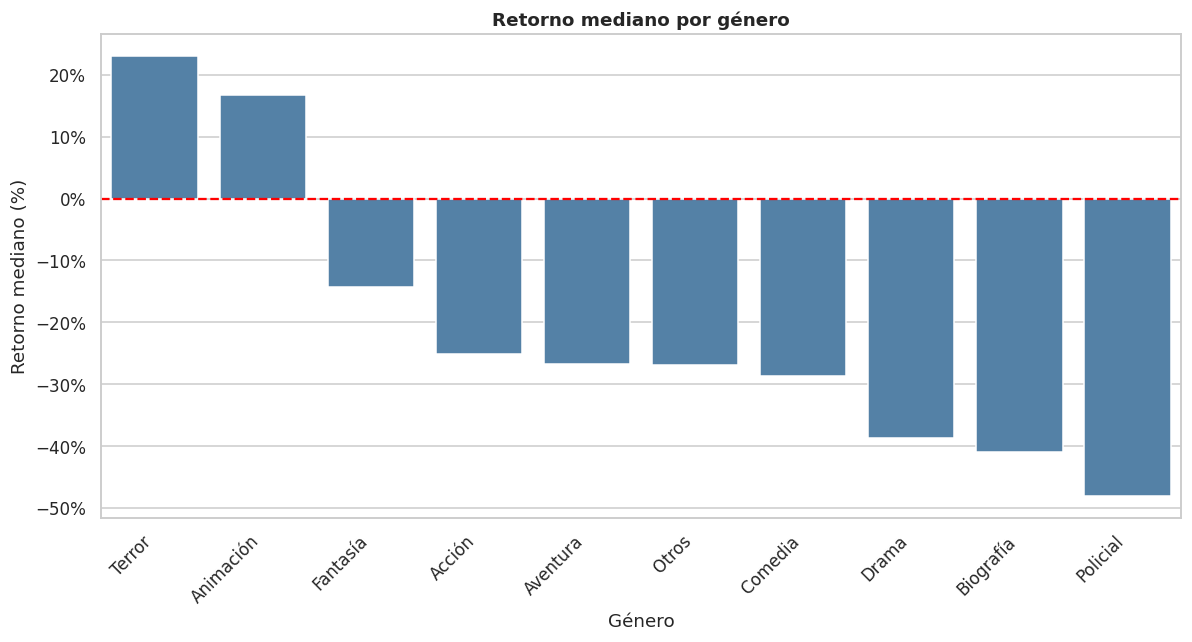

In [58]:
#Gráfico de retorno mediano
retornos_genero = por_genero.sort_values(
    "retorno_neto_mediano",
    ascending=False
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=retornos_genero,
    x=retornos_genero.index,
    y="retorno_neto_mediano",
    color="steelblue"
)

plt.axhline(0, color="red", linestyle="--")

plt.title("Retorno mediano por género")
plt.xlabel("Género")
plt.ylabel("Retorno mediano (%)")
plt.xticks(rotation=45, ha="right")

plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout()
plt.show()

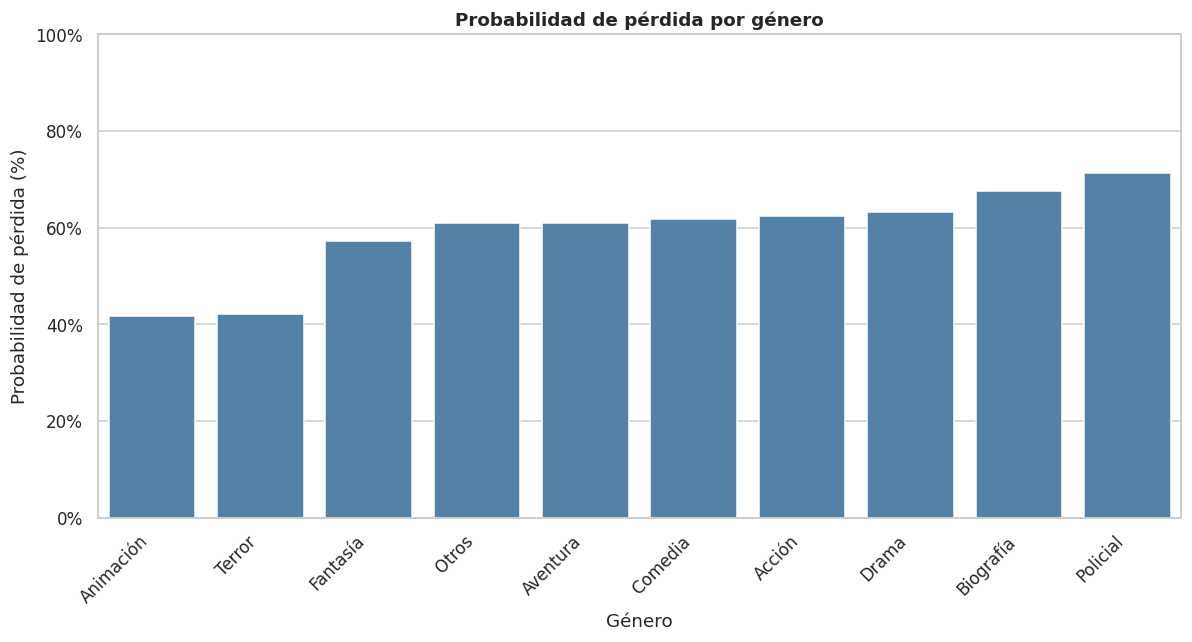

In [59]:
#Gráfico de probabilidad de pérdida
riesgo_genero = por_genero.sort_values(
    "prob_perdida",
    ascending=True
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=riesgo_genero,
    x=riesgo_genero.index,
    y="prob_perdida",
    color="steelblue"
)

plt.title("Probabilidad de pérdida por género")
plt.xlabel("Género")
plt.ylabel("Probabilidad de pérdida (%)")

# La probabilidad va de 0 a 1
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")

plt.gca().yaxis.set_major_formatter(PercentFormatter(1))

plt.tight_layout()
plt.show()


### Conclusión: ¿qué géneros ofrecen mejores retornos y menores riesgos?

El análisis muestra que **terror y animación son los géneros con mejores resultados**. Terror tiene un múltiplo mediano de 3,1× y animación de 2,9×, siendo los únicos géneros que superan el umbral de recuperación de 2,5×. Además, ambos tienen la menor probabilidad de pérdida (42%), mientras que policial alcanza el 71%.

También encontramos que **los promedios pueden ser engañosos**. Por ejemplo, terror tiene un múltiplo promedio de 77×, principalmente por películas extremadamente exitosas como *Paranormal Activity* y *The Blair Witch Project*. Al excluir solo estas dos películas, el promedio baja a 9,9×, pero la mediana prácticamente no cambia. Esto demuestra por qué es mejor utilizar la mediana para comparar los géneros.

Por último, el test de Kruskal-Wallis (p < 0,001) muestra que existen diferencias estadísticamente significativas entre los géneros.

**En conclusión, terror y animación parecen ser las mejores opciones para invertir**, ya que combinan mayores retornos con menores riesgos. Sin embargo, antes de decidir, debemos analizar también el presupuesto y otras características de las películas.

<h3 style='font-weight:bold; color:#0033BB;'>3.2.5 El mismo análisis por clasificación, país de origen, franquicia, productora y época</h3>

La pauta pide al menos una de clasificación / país / franquicia; hacemos las tres y agregamos productora, tramo de
presupuesto y época porque el caso las menciona explícitamente en la pregunta 1.

In [60]:
FORMATO_RESUMEN = {"peliculas": "{:,}", "multiplo_medio": "{:.2f}x", "multiplo_mediano": "{:.2f}x",
                   "retorno_neto_mediano": "{:+.0%}", "prob_perdida": "{:.0%}", "retorno_peor_decil": "{:+.0%}",
                   "retorno_mejor_decil": "{:+.0%}", "presupuesto_mediano_mm": "{:.1f}",
                   "media_sobre_mediana": "{:.1f}"}
for variable, titulo in [("es_secuela", "Franquicia (secuela, precuela o saga)"),
                         ("publico", "Clasificación por edades (agrupada por público)"),
                         ("origen", "País de origen"),
                         ("tramo_presupuesto", "Tramo de presupuesto (USD de 2020)"),
                         ("epoca", "Época de estreno")]:
    print(f"\n=== {titulo} ===")
    display(resumir_retorno(base, variable).style.format(FORMATO_RESUMEN))


=== Franquicia (secuela, precuela o saga) ===


,peliculas,multiplo_medio,multiplo_mediano,retorno_neto_mediano,prob_perdida,retorno_peor_decil,retorno_mejor_decil,presupuesto_mediano_mm,media_sobre_mediana
es_secuela,,,,,,,,,
False,"4,816",7.03x,1.69x,-32%,64%,-90%,+175%,32.1,4.2
True,573,4.22x,2.97x,+19%,41%,-69%,+234%,52.5,1.4



=== Clasificación por edades (agrupada por público) ===


,peliculas,multiplo_medio,multiplo_mediano,retorno_neto_mediano,prob_perdida,retorno_peor_decil,retorno_mejor_decil,presupuesto_mediano_mm,media_sobre_mediana
publico,,,,,,,,,
Adolescente (13+),"1,713",3.32x,2.07x,-17%,58%,-84%,+168%,43.8,1.6
Adulto (17+),"2,592",10.31x,1.56x,-37%,65%,-92%,+192%,24.1,6.6
Familiar,"1,008",3.55x,2.08x,-17%,57%,-85%,+194%,44.9,1.7
Sin clasificar,64,3.47x,0.99x,-60%,69%,-98%,+178%,4.8,3.5
Sin dato,12,6.17x,2.01x,-20%,58%,-99%,+550%,4.6,3.1



=== País de origen ===


,peliculas,multiplo_medio,multiplo_mediano,retorno_neto_mediano,prob_perdida,retorno_peor_decil,retorno_mejor_decil,presupuesto_mediano_mm,media_sobre_mediana
origen,,,,,,,,,
Estados Unidos,"4,290",7.54x,1.95x,-22%,59%,-88%,+182%,35.0,3.9
Resto del mundo,"1,098",3.60x,1.34x,-46%,68%,-93%,+190%,26.7,2.7
Sin dato,1,0.02x,0.02x,-99%,100%,-99%,-99%,2.5,1.0



=== Tramo de presupuesto (USD de 2020) ===


,peliculas,multiplo_medio,multiplo_mediano,retorno_neto_mediano,prob_perdida,retorno_peor_decil,retorno_mejor_decil,presupuesto_mediano_mm,media_sobre_mediana
tramo_presupuesto,,,,,,,,,
Bajo (<10 MM),819,29.10x,2.40x,-4%,51%,-94%,+639%,5.2,12.1
Medio (10-40 MM),"2,300",2.86x,1.63x,-35%,64%,-91%,+170%,23.5,1.7
Alto (40-100 MM),"1,569",2.46x,1.68x,-33%,66%,-87%,+109%,58.0,1.5
Tanque (>100 MM),701,2.88x,2.43x,-3%,52%,-73%,+121%,142.8,1.2



=== Época de estreno ===


,peliculas,multiplo_medio,multiplo_mediano,retorno_neto_mediano,prob_perdida,retorno_peor_decil,retorno_mejor_decil,presupuesto_mediano_mm,media_sobre_mediana
epoca,,,,,,,,,
1980s,885,3.59x,1.56x,-38%,64%,-92%,+236%,26.0,2.3
1990s,"1,357",5.98x,1.15x,-54%,72%,-94%,+132%,35.8,5.2
2000s,"1,638",11.09x,1.88x,-25%,62%,-84%,+141%,39.4,5.9
2010-14,803,4.21x,2.46x,-2%,51%,-82%,+230%,32.8,1.7
2015-20,706,4.85x,2.70x,+8%,47%,-78%,+280%,31.7,1.8


In [61]:
print("Clasificación detallada (sin agrupar):")
display(resumir_retorno(base, "clasificacion").sort_values("multiplo_mediano", ascending=False)
        .style.format(FORMATO_RESUMEN))

print("Productoras con al menos 40 películas, ordenadas por múltiplo mediano:")
por_productora = resumir_retorno(base, "productora", minimo_peliculas=40).sort_values("multiplo_mediano", ascending=False)
display(por_productora.style.format(FORMATO_RESUMEN))

print("Majors contra el resto de las productoras:")
display(resumir_retorno(base, "es_major").style.format(FORMATO_RESUMEN))

Clasificación detallada (sin agrupar):


,peliculas,multiplo_medio,multiplo_mediano,retorno_neto_mediano,prob_perdida,retorno_peor_decil,retorno_mejor_decil,presupuesto_mediano_mm,media_sobre_mediana
clasificacion,,,,,,,,,
ATP,110,4.19x,2.69x,+7%,48%,-81%,+242%,47.5,1.6
Mayores de 13,"1,713",3.32x,2.07x,-17%,58%,-84%,+168%,43.8,1.6
Supervisión parental,898,3.47x,2.04x,-18%,58%,-86%,+190%,44.2,1.7
Solo adultos,13,2.73x,1.61x,-36%,62%,-87%,+198%,9.0,1.7
Mayores de 17,"2,579",10.35x,1.56x,-37%,65%,-92%,+192%,24.1,6.6
Sin clasificar,64,3.47x,0.99x,-60%,69%,-98%,+178%,4.8,3.5


Productoras con al menos 40 películas, ordenadas por múltiplo mediano:


,peliculas,multiplo_medio,multiplo_mediano,retorno_neto_mediano,prob_perdida,retorno_peor_decil,retorno_mejor_decil,presupuesto_mediano_mm,media_sobre_mediana
productora,,,,,,,,,
Fox Searchlight Pictures,48,7.26x,3.31x,+33%,42%,-59%,+308%,13.9,2.2
Walt Disney Pictures,103,3.93x,2.76x,+10%,45%,-56%,+180%,93.4,1.4
Twentieth Century Fox,208,3.30x,2.71x,+8%,47%,-77%,+152%,56.2,1.2
Screen Gems,54,4.77x,2.57x,+3%,46%,-62%,+190%,24.1,1.9
Fox 2000 Pictures,58,3.43x,2.54x,+2%,48%,-56%,+151%,37.7,1.3
New Line Cinema,153,6.84x,2.47x,-1%,50%,-74%,+285%,38.0,2.8
Dimension Films,49,2.85x,2.39x,-4%,53%,-86%,+110%,31.1,1.2
Lionsgate,53,3.24x,2.37x,-5%,57%,-73%,+202%,31.2,1.4
Dreamworks Pictures,75,2.96x,2.30x,-8%,55%,-70%,+100%,62.4,1.3


Majors contra el resto de las productoras:


,peliculas,multiplo_medio,multiplo_mediano,retorno_neto_mediano,prob_perdida,retorno_peor_decil,retorno_mejor_decil,presupuesto_mediano_mm,media_sobre_mediana
es_major,,,,,,,,,
False,"3,153",8.86x,1.45x,-42%,66%,-93%,+196%,22.5,6.1
True,"2,236",3.73x,2.25x,-10%,55%,-79%,+174%,51.8,1.7


In [62]:
print("Temporada de estreno:")

display(
    resumir_retorno(base, "temporada")
    .sort_values("multiplo_mediano", ascending=False)
    .style.format(FORMATO_RESUMEN)
)

Temporada de estreno:


,peliculas,multiplo_medio,multiplo_mediano,retorno_neto_mediano,prob_perdida,retorno_peor_decil,retorno_mejor_decil,presupuesto_mediano_mm,media_sobre_mediana
temporada,,,,,,,,,
Verano (may-ago),"1,782",6.45x,2.17x,-13%,56%,-86%,+208%,37.4,3.0
Fiestas (nov-dic),934,3.21x,2.02x,-19%,59%,-88%,+170%,44.7,1.6
Resto del año,"2,673",8.15x,1.57x,-37%,66%,-91%,+169%,28.8,5.2


**Conclusiones por categoría:**

- **Franquicias:** Las películas que forman parte de una franquicia presentan una mejor relación entre riesgo y retorno. Su múltiplo mediano es de 2,97×, frente a 1,69× de las películas independientes de franquicias. Además, tienen una menor probabilidad de pérdida (41% frente a 64%) y pérdidas menos severas en el peor decil (−69% frente a −90%). Esto sugiere que las franquicias son una alternativa atractiva para el portafolio, ya que combinan mayor rentabilidad mediana con menor riesgo histórico.
- **Clasificación por edades:** Las películas aptas para todo público (ATP) presentan los mejores resultados, con un múltiplo mediano de 2,69× y una probabilidad de pérdida del 48%. Les siguen las películas para mayores de 13 años, con un múltiplo de 2,07× y un 58% de probabilidad de pérdida. En cambio, las películas para mayores de 17 presentan un múltiplo mediano de 1,56× y una probabilidad de pérdida del 65%.
Esto sugiere que las películas dirigidas a públicos más amplios tienen mejores resultados históricos. Sin embargo, debemos considerar las diferencias en el tamaño de las muestras, especialmente en categorías con pocas observaciones, como Solo adultos (13 películas).
- **País de origen:** Las películas estadounidenses presentan un múltiplo mediano de 1,95×, superior al 1,34× del resto del mundo. Sin embargo, esta comparación debe interpretarse con precaución, ya que fuera de Estados Unidos falta información presupuestaria en aproximadamente el 49% de las películas. Por lo tanto, los resultados podrían no representar adecuadamente la rentabilidad de las producciones internacionales.
- **Tramo de presupuesto:** Observamos que las películas de bajo presupuesto y las grandes producciones presentan los mayores múltiplos medianos (aproximadamente 2,4×), mientras que las de presupuesto intermedio alcanzan entre 1,6× y 1,7×. Sin embargo, tener una rentabilidad mediana similar no implica asumir el mismo riesgo: en el peor decil, las películas de bajo presupuesto presentan un retorno de −94%, frente a −73% de las grandes producciones. Esto indica que las películas de bajo presupuesto pueden sufrir pérdidas proporcionalmente más severas, por lo que el presupuesto debe considerarse junto con el riesgo al definir la estrategia de inversión.
- **Productoras:** Las grandes productoras (*majors*) presentan un múltiplo mediano de 2,25×, frente a 1,45× del resto. Entre las productoras con al menos 40 películas, destacan Fox Searchlight Pictures (3,31×) y Disney (aproximadamente 2,8×), mientras que MGM, Miramax y Castle Rock presentan múltiplos inferiores a 1,4×. Estas diferencias pueden estar relacionadas con el tipo de películas que produce cada compañía, por lo que no necesariamente reflejan una ventaja atribuible exclusivamente a la productora.
- **Época:** La rentabilidad varía considerablemente entre períodos. Los años noventa presentan el menor múltiplo mediano (1,15×), mientras que 2015-2020 alcanza el mayor (aproximadamente 2,7×). Esto muestra que los resultados históricos no son constantes en el tiempo, por lo que es importante considerar distintos períodos antes de proyectar retornos futuros.
-**Temporada de estreno:** Las películas estrenadas durante el verano estadounidense (mayo-agosto) presentan un múltiplo mediano de 2,17×, seguidas por los estrenos de noviembre-diciembre (2,02×), mientras que el resto del año alcanza 1,57×. Estas diferencias podrían estar relacionadas con la concentración de grandes producciones en determinadas épocas, aunque sería necesario controlar por presupuesto y tipo de película para comprobarlo.

<h3 style='font-weight:bold; color:#0033BB;'>3.2.6 Relación entre el puntaje de IMDb y el retorno</h3>

Usamos **Spearman** (correlación de rangos) además de Pearson: con distribuciones tan asimétricas, Pearson está
dominado por un puñado de valores extremos. Para el retorno usamos el logaritmo del múltiplo.

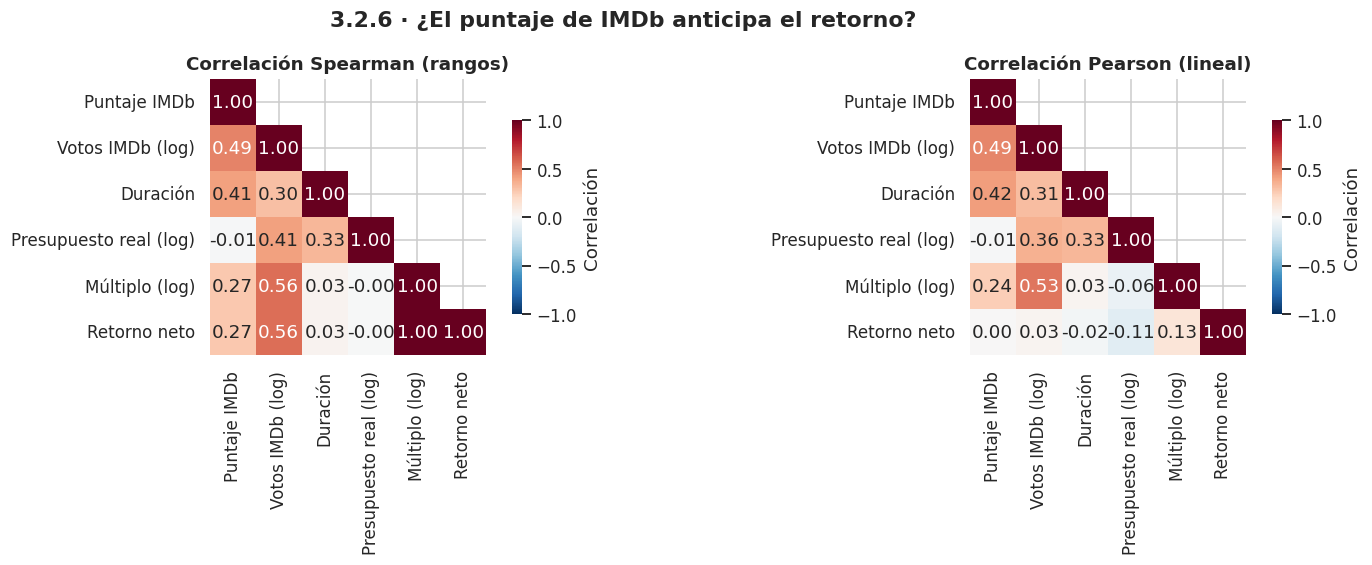

Spearman IMDb vs múltiplo: rho = 0.27 (p < 0,001)
Pearson  IMDb vs múltiplo: r   = 0.00 (contaminado por los outliers)

Múltiplo mediano y % que recupera, por quintil de puntaje IMDb:
              multiplo_mediano  pct_recupera
puntaje_imdb                                
(1.899, 5.7]              1.17          0.26
(5.7, 6.2]                1.57          0.33
(6.2, 6.7]                1.77          0.35
(6.7, 7.2]                2.04          0.42
(7.2, 9.3]                3.38          0.61


In [63]:
variables_correlacion = base.assign(
    log_multiplo=np.log10(base["multiplo_bruto"].clip(lower=1e-3)),
    log_presupuesto=np.log10(base["presupuesto_real"]),
    log_votos=np.log10(base["cantidad_votos"]),
)[["puntaje_imdb", "log_votos", "duracion_minutos", "log_presupuesto", "log_multiplo", "retorno_neto"]]
NOMBRES_CORRELACION = {"puntaje_imdb": "Puntaje IMDb", "log_votos": "Votos IMDb (log)",
                       "duracion_minutos": "Duración", "log_presupuesto": "Presupuesto real (log)",
                       "log_multiplo": "Múltiplo (log)", "retorno_neto": "Retorno neto"}
correlacion_spearman = variables_correlacion.corr(method="spearman").rename(index=NOMBRES_CORRELACION,
                                                                           columns=NOMBRES_CORRELACION)
correlacion_pearson = variables_correlacion.corr(method="pearson").rename(index=NOMBRES_CORRELACION,
                                                                         columns=NOMBRES_CORRELACION)

figura, ejes = plt.subplots(1, 2, figsize=(14, 5.2))
for eje, matriz, titulo in [(ejes[0], correlacion_spearman, "Spearman (rangos)"),
                            (ejes[1], correlacion_pearson, "Pearson (lineal)")]:
    mascara_triangulo = np.triu(np.ones_like(matriz, dtype=bool), k=1)
    sns.heatmap(matriz, mask=mascara_triangulo, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
                square=True, ax=eje, cbar_kws={"shrink": 0.7, "label": "Correlación"})
    eje.set_title(f"Correlación {titulo}")
figura.suptitle("3.2.6 · ¿El puntaje de IMDb anticipa el retorno?", fontweight="bold")
figura.tight_layout()
guardar_figura(figura, "02_mapa_calor_correlaciones.png")
plt.show()

rho, valor_p = stats.spearmanr(base["puntaje_imdb"], base["multiplo_bruto"], nan_policy="omit")
print(f"Spearman IMDb vs múltiplo: rho = {rho:.2f} (p {formatear_p(valor_p)})")
print(f"Pearson  IMDb vs múltiplo: r   = {base[['puntaje_imdb', 'multiplo_bruto']].corr().iloc[0, 1]:.2f} "
      "(contaminado por los outliers)")
print("\nMúltiplo mediano y % que recupera, por quintil de puntaje IMDb:")
print(base.groupby(pd.qcut(base["puntaje_imdb"], 5), observed=True).agg(
    multiplo_mediano=("multiplo_bruto", "median"),
    pct_recupera=("recupero_inversion", "mean")).round(2).to_string())

**Conclusión.** La relación entre el puntaje IMDb y el retorno es positiva, aunque moderada: Spearman alcanza 0,27 y Pearson entre el puntaje y el logaritmo del múltiplo es 0,24. En cambio, Pearson con el retorno neto es prácticamente cero, posiblemente por la influencia de valores extremos. El análisis por quintiles refuerza la asociación: las películas mejor puntuadas presentan un múltiplo mediano de 3,38x y recuperan la inversión en el 61% de los casos, frente a 1,17x y 26% entre las peor puntuadas.

**Sin embargo, esta relación no permite utilizar IMDb como predictor para decidir inversiones**, ya que tanto el puntaje como la cantidad de votos se conocen después del estreno. Por eso, para evaluar proyectos antes de financiarlos, se priorizan variables disponibles previamente, como género, presupuesto, franquicia y clasificación.



#3.3 ¿Dónde está el riesgo?</h2>

<h3 style='font-weight:bold; color:#0033BB;'>3.3.7 Probabilidad de perder plata, peor decil y retorno mediano por segmento</h3>

Tres métricas por segmento:

- **Probabilidad de pérdida**: % de películas que no llegaron a 2,5× (`retorno_neto` < 0).
- **Peor decil**: el `retorno_neto` del percentil 10. "En una de cada diez películas del segmento se pierde esto o más."
- **Retorno neto mediano**: lo que le pasa a la película típica.

Los segmentos combinan género × tramo de presupuesto, que es la forma en que se arma un proyecto (se decide qué
película y con cuánta plata). Como la Etapa 3.2 mostró que las **franquicias** son un corte transversal muy fuerte,
agregamos también los segmentos franquicia × tramo (son estrategias alternativas que se superponen con los géneros).
Solo se muestran combinaciones con al menos 30 películas.

In [64]:
segmentos_genero = resumir_retorno(base, ["genero_analisis", "tramo_presupuesto"],
                                   minimo_peliculas=MINIMO_PELICULAS_SEGMENTO)
segmentos_genero.index = [f"{genero} · {tramo}" for genero, tramo in segmentos_genero.index]
segmentos_franquicia = resumir_retorno(base[base["es_secuela"]], "tramo_presupuesto",
                                       minimo_peliculas=MINIMO_PELICULAS_SEGMENTO)
segmentos_franquicia.index = [f"Franquicia · {tramo}" for tramo in segmentos_franquicia.index]
segmentos = pd.concat([segmentos_genero, segmentos_franquicia])
segmentos.index.name = "segmento"

# 3.3.8 Dominancia: un segmento domina a otro si tiene MÁS retorno mediano y MENOS probabilidad de pérdida
segmentos["dominado_por"] = marcar_dominados(segmentos, columna_retorno="retorno_neto_mediano",
                                             columna_riesgo="prob_perdida")
segmentos["en_frontera"] = segmentos["dominado_por"] == ""
segmentos = segmentos.sort_values("retorno_neto_mediano", ascending=False)
segmentos.to_csv(CARPETA_SALIDAS / "tabla_riesgo_retorno_segmentos.csv")
(segmentos[["peliculas", "multiplo_mediano", "retorno_neto_mediano", "prob_perdida", "retorno_peor_decil",
            "presupuesto_mediano_mm", "en_frontera", "dominado_por"]]
 .style.format(FORMATO_RESUMEN)
 .apply(lambda fila: ["background-color: #d6eaf8" if fila["en_frontera"] else "" for _ in fila], axis=1))

,peliculas,multiplo_mediano,retorno_neto_mediano,prob_perdida,retorno_peor_decil,presupuesto_mediano_mm,en_frontera,dominado_por
segmento,,,,,,,,
Terror · Bajo (<10 MM),106,6.63x,+165%,32%,-78%,4.6,True,
Franquicia · Bajo (<10 MM),68,4.02x,+61%,37%,-69%,5.4,False,Terror · Bajo (<10 MM)
Franquicia · Tanque (>100 MM),168,3.38x,+35%,32%,-42%,170.8,False,Terror · Bajo (<10 MM)
Animación · Alto (40-100 MM),98,3.08x,+23%,41%,-78%,67.7,False,Terror · Bajo (<10 MM)
Franquicia · Alto (40-100 MM),175,2.92x,+17%,42%,-70%,63.3,False,Terror · Bajo (<10 MM)
Animación · Tanque (>100 MM),112,2.87x,+15%,41%,-65%,155.3,False,Terror · Bajo (<10 MM)
Terror · Medio (10-40 MM),117,2.76x,+10%,42%,-89%,20.4,False,Terror · Bajo (<10 MM)
Animación · Medio (10-40 MM),48,2.71x,+9%,48%,-81%,28.5,False,Terror · Bajo (<10 MM)
Acción · Tanque (>100 MM),384,2.50x,+0%,50%,-65%,150.3,False,Terror · Bajo (<10 MM)


In [65]:
# Dominancia también con el peor decil como medida de riesgo (cuánto se pierde en el escenario malo)
segmentos["dominado_por_cola"] = marcar_dominados(
    segmentos.assign(riesgo_cola=-segmentos["retorno_peor_decil"]),
    columna_retorno="retorno_neto_mediano", columna_riesgo="riesgo_cola")
print("Frontera eficiente usando probabilidad de pérdida:", segmentos.index[segmentos["en_frontera"]].tolist())
print("Frontera eficiente usando el peor decil:          ", segmentos.index[segmentos["dominado_por_cola"] == ""].tolist())
segmentos["en_frontera_cola"] = segmentos["dominado_por_cola"] == ""
print(f"\nSegmentos dominados por probabilidad de pérdida: {(~segmentos['en_frontera']).sum()} de {len(segmentos)} | "
      f"por peor decil: {(~segmentos['en_frontera_cola']).sum()} de {len(segmentos)}")
print("\nLos segmentos de la frontera (con cualquiera de las dos medidas de riesgo):")
display(segmentos[segmentos["en_frontera"] | segmentos["en_frontera_cola"]][
    ["peliculas", "multiplo_mediano", "retorno_neto_mediano", "prob_perdida", "retorno_peor_decil",
     "presupuesto_mediano_mm"]].style.format(FORMATO_RESUMEN))

# Franquicias como corte transversal a los géneros
franquicias_por_tramo = resumir_retorno(base, ["es_secuela", "tramo_presupuesto"])
print("\nFranquicia x tramo de presupuesto:")
franquicias_por_tramo.style.format(FORMATO_RESUMEN)

Frontera eficiente usando probabilidad de pérdida: ['Terror · Bajo (<10 MM)']
Frontera eficiente usando el peor decil:           ['Terror · Bajo (<10 MM)', 'Franquicia · Bajo (<10 MM)', 'Franquicia · Tanque (>100 MM)']

Segmentos dominados por probabilidad de pérdida: 29 de 30 | por peor decil: 27 de 30

Los segmentos de la frontera (con cualquiera de las dos medidas de riesgo):


,peliculas,multiplo_mediano,retorno_neto_mediano,prob_perdida,retorno_peor_decil,presupuesto_mediano_mm
segmento,,,,,,
Terror · Bajo (<10 MM),106,6.63x,+165%,32%,-78%,4.6
Franquicia · Bajo (<10 MM),68,4.02x,+61%,37%,-69%,5.4
Franquicia · Tanque (>100 MM),168,3.38x,+35%,32%,-42%,170.8



Franquicia x tramo de presupuesto:


**Conclusiones 3.3.7–3.3.8**

- **Retorno y riesgo:** un retorno mediano elevado no implica necesariamente menor riesgo. Terror de bajo presupuesto presenta el mayor retorno mediano (+165%) y una probabilidad de pérdida del 32%, pero su peor decil alcanza −78%. En cambio, las franquicias tanque tienen un retorno mediano menor (+35%), aunque presentan un peor decil menos negativo (−42%).

- **Dominancia:** considerando retorno mediano y probabilidad de pérdida, terror de bajo presupuesto domina a los otros 29 segmentos analizados. Sin embargo, al utilizar el peor decil como medida de riesgo, la frontera eficiente incluye tres alternativas: terror bajo, franquicia bajo y franquicia tanque. Cada una representa una combinación diferente de rentabilidad y exposición a pérdidas extremas.

- **Segmentos menos atractivos:** policial, drama, biografía y aventura de presupuesto medio-alto presentan retornos medianos negativos y probabilidades de pérdida elevadas, por lo que resultan menos atractivos según las métricas analizadas.

**Implicación para la inversión:** estos resultados permiten identificar como principales candidatos para la Etapa 5 las películas de terror de bajo presupuesto, las franquicias y la animación, considerando tanto su rentabilidad histórica como sus riesgos.

#Etapa 4 · Visualización

En esta etapa se presentan distintos gráficos para visualizar los principales resultados del análisis, comparar la rentabilidad entre segmentos e identificar patrones que no se observan fácilmente en las tablas. Las figuras se guardan en `salidas/figuras/` para su posterior presentación.

<h2 style='font-weight:bold; color:#003366;'>4.1 Evolución de la industria: serie nominal y real en la misma figura</h2>

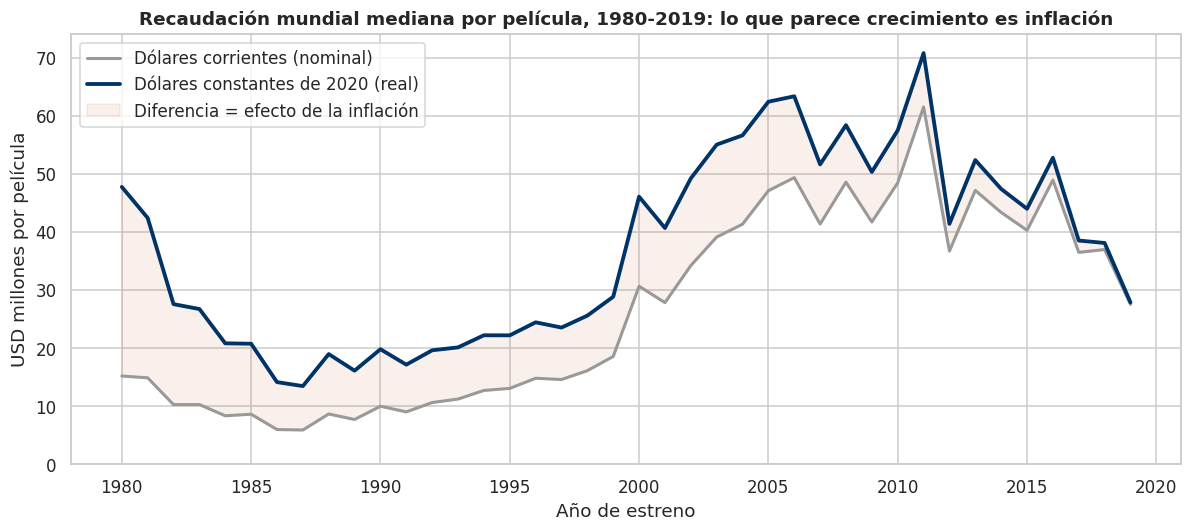

In [66]:
figura, eje = plt.subplots(figsize=(11, 5))
eje.plot(serie_anual.index, serie_anual["recaudacion_mediana_nominal"], color=GRIS, lw=2,
         label="Dólares corrientes (nominal)")
eje.plot(serie_anual.index, serie_anual["recaudacion_mediana_real"], color=AZUL, lw=2.5,
         label="Dólares constantes de 2020 (real)")
eje.fill_between(serie_anual.index, serie_anual["recaudacion_mediana_nominal"],
                 serie_anual["recaudacion_mediana_real"], color=ROJO, alpha=0.08,
                 label="Diferencia = efecto de la inflación")
eje.yaxis.set_major_formatter(mticker.FuncFormatter(formato_millones))
eje.set_title("Recaudación mundial mediana por película, 1980-2019: lo que parece crecimiento es inflación")
eje.set_xlabel("Año de estreno")
eje.set_ylabel("USD millones por película")
eje.legend(loc="upper left")
eje.set_ylim(0, None)
figura.tight_layout()
guardar_figura(figura, "03_industria_nominal_vs_real.png")
plt.show()

**Conclusión.** La serie nominal (gris) sugiere una industria que creció casi cinco veces; la real (azul) muestra que
buena parte de esa subida es inflación (área roja) y que en los 2010 la película mediana recaudaba menos, en términos
reales, que en los 2000. Un comité que mirara solo la serie nominal sobreestimaría el crecimiento del mercado.

<h2 style='font-weight:bold; color:#003366;'>4.2 Distribución del retorno: por qué el promedio no sirve</h2>

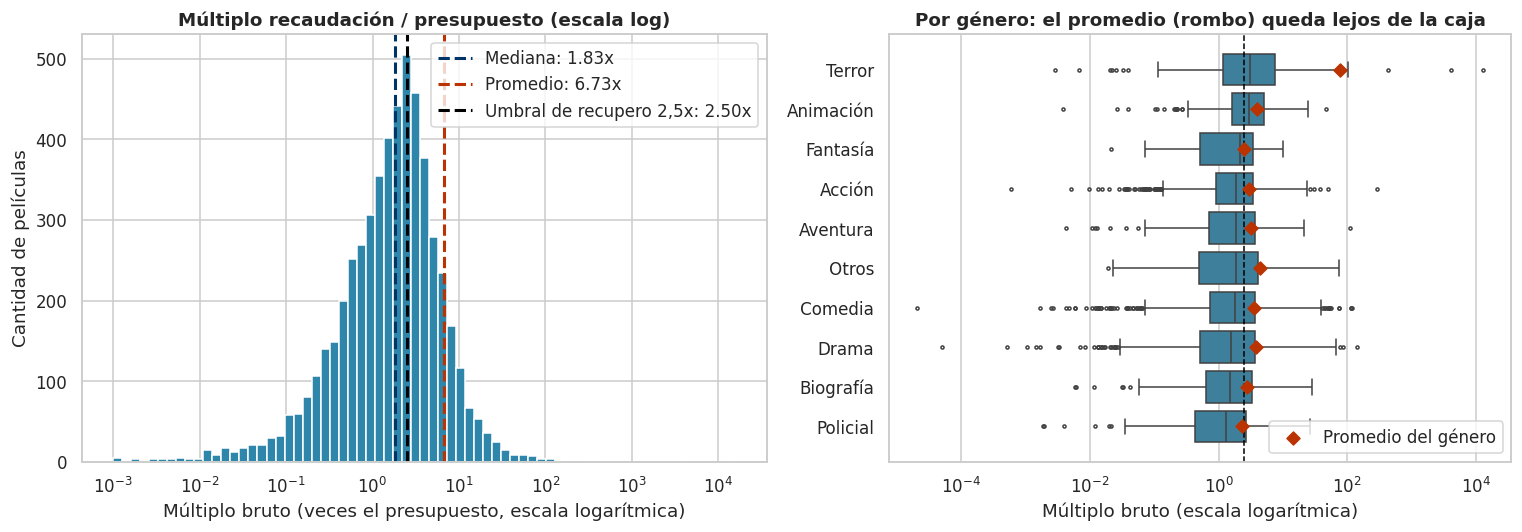

Películas por debajo del promedio de la industria: 89%


In [67]:
figura, (eje_hist, eje_caja) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.1, 1]})
contenedores = np.logspace(-3, 4.2, 70)
eje_hist.hist(base["multiplo_bruto"].clip(lower=1e-3), bins=contenedores, color=CELESTE, edgecolor="white")
eje_hist.set_xscale("log")
for valor, color, etiqueta in [(base["multiplo_bruto"].median(), AZUL, "Mediana"),
                               (base["multiplo_bruto"].mean(), ROJO, "Promedio"),
                               (UMBRAL_RECUPERO, "black", "Umbral de recupero 2,5x")]:
    eje_hist.axvline(valor, color=color, ls="--", lw=2, label=f"{etiqueta}: {valor:.2f}x")
eje_hist.set_title("Múltiplo recaudación / presupuesto (escala log)")
eje_hist.set_xlabel("Múltiplo bruto (veces el presupuesto, escala logarítmica)")
eje_hist.set_ylabel("Cantidad de películas")
eje_hist.legend()

orden_generos = por_genero.index.tolist()
sns.boxplot(data=base, y="genero_analisis", x="multiplo_bruto", order=orden_generos, ax=eje_caja,
            color=CELESTE, fliersize=2, log_scale=True)
medias_por_genero = base.groupby("genero_analisis")["multiplo_bruto"].mean().reindex(orden_generos)
eje_caja.scatter(medias_por_genero.values, range(len(orden_generos)), color=ROJO, marker="D", zorder=5,
                 label="Promedio del género")
eje_caja.axvline(UMBRAL_RECUPERO, color="black", ls="--", lw=1)
eje_caja.set_title("Por género: el promedio (rombo) queda lejos de la caja")
eje_caja.set_xlabel("Múltiplo bruto (escala logarítmica)")
eje_caja.set_ylabel("")
eje_caja.legend(loc="lower right")
figura.tight_layout()
guardar_figura(figura, "04_distribucion_retorno.png")
plt.show()
print(f"Películas por debajo del promedio de la industria: {(base['multiplo_bruto'] < base['multiplo_bruto'].mean()).mean():.0%}")

**Conclusión.** La distribución del múltiplo es simétrica **en escala logarítmica**, es decir, extremadamente asimétrica
en escala normal. El promedio (6,7×) queda a la derecha del 89% de las películas: describe a casi ninguna. En el panel
de géneros, el rombo rojo del terror cae lejos fuera de su caja; en los demás géneros está cerca. Por eso la tesis se
construye con medianas y percentiles.

<h2 style='font-weight:bold; color:#003366;'>4.3 Comparación entre géneros ordenada por valor</h2>

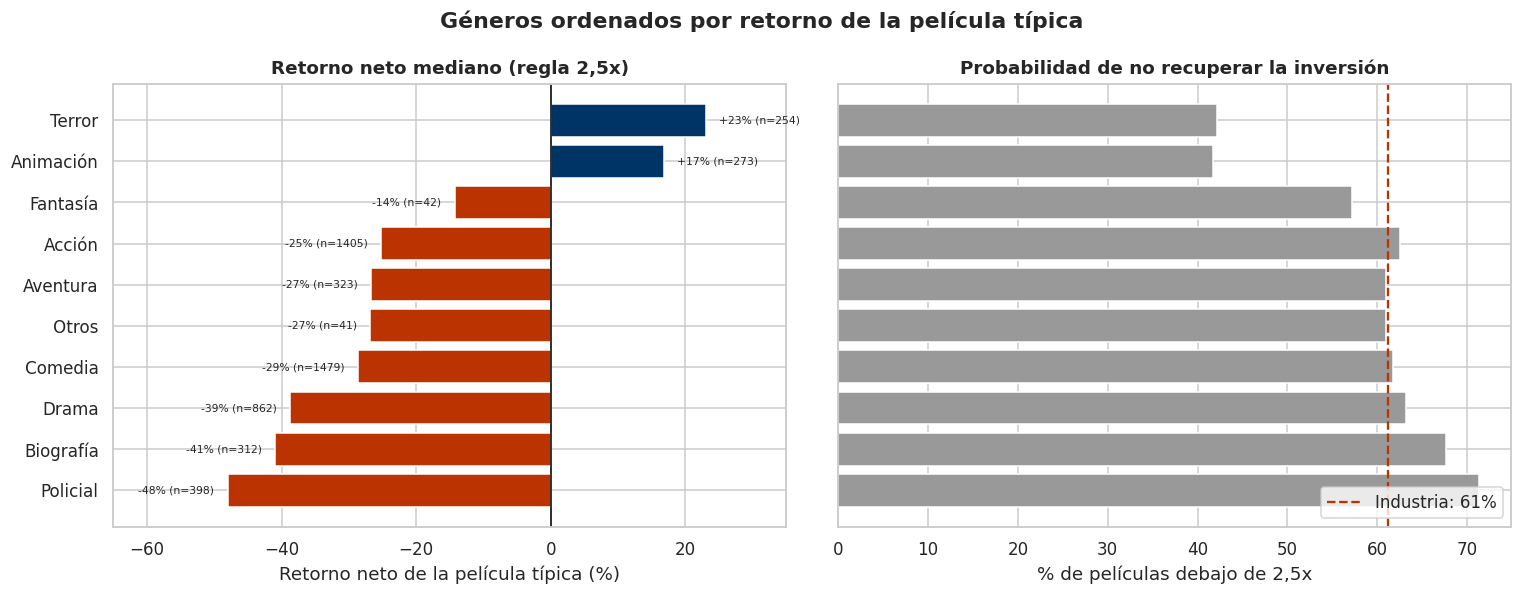

In [68]:
comparacion_generos = por_genero.sort_values("retorno_neto_mediano")
figura, (eje_retorno, eje_riesgo) = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
colores_barras = [AZUL if valor > 0 else ROJO for valor in comparacion_generos["retorno_neto_mediano"]]
eje_retorno.barh(comparacion_generos.index, comparacion_generos["retorno_neto_mediano"] * 100, color=colores_barras)
eje_retorno.axvline(0, color="black", lw=1)
eje_retorno.set_title("Retorno neto mediano (regla 2,5x)")
eje_retorno.set_xlabel("Retorno neto de la película típica (%)")
for posicion, (valor, cantidad) in enumerate(zip(comparacion_generos["retorno_neto_mediano"],
                                                  comparacion_generos["peliculas"])):
    eje_retorno.text(valor * 100 + (2 if valor > 0 else -2), posicion,
                     f"{valor:+.0%} (n={cantidad})",
                     va="center", ha="left" if valor > 0 else "right", fontsize=7)
eje_retorno.set_xlim(-65, 35)
eje_riesgo.barh(comparacion_generos.index, comparacion_generos["prob_perdida"] * 100, color=GRIS)
eje_riesgo.axvline((1 - base["recupero_inversion"].mean()) * 100, color=ROJO, ls="--",
                   label=f"Industria: {1 - base['recupero_inversion'].mean():.0%}")
eje_riesgo.set_title("Probabilidad de no recuperar la inversión")
eje_riesgo.set_xlabel("% de películas debajo de 2,5x")
eje_riesgo.legend(loc="lower right")
figura.suptitle("Géneros ordenados por retorno de la película típica", fontweight="bold")
figura.tight_layout()
guardar_figura(figura, "05_generos_ordenados.png")
plt.show()

**Conclusión.** Ordenados por el retorno de la película típica, solo terror (+23%) y animación (+17%) presentan un retorno neto mediano positivo. Los otros ocho géneros tienen retornos negativos, siendo policial el menos rentable (−48%). Además, terror y animación presentan las menores probabilidades de pérdida (alrededor del 42%, frente al 61% de la industria). Por lo tanto, a nivel de género, no se observa una compensación entre mayor rentabilidad y mayor riesgo: los géneros más rentables también son los menos riesgosos según esta medida.

<h2 style='font-weight:bold; color:#003366;'>4.4 Presupuesto contra recaudación, resolviendo la superposición</h2>

Con más de 5.000 puntos un scatter común es una mancha. Usamos **hexbin** (cada hexágono cuenta cuántas películas
caen ahí) en escala log-log, con las líneas de 1× (recuperó el presupuesto en boletería) y 2,5× (recuperó la
inversión).

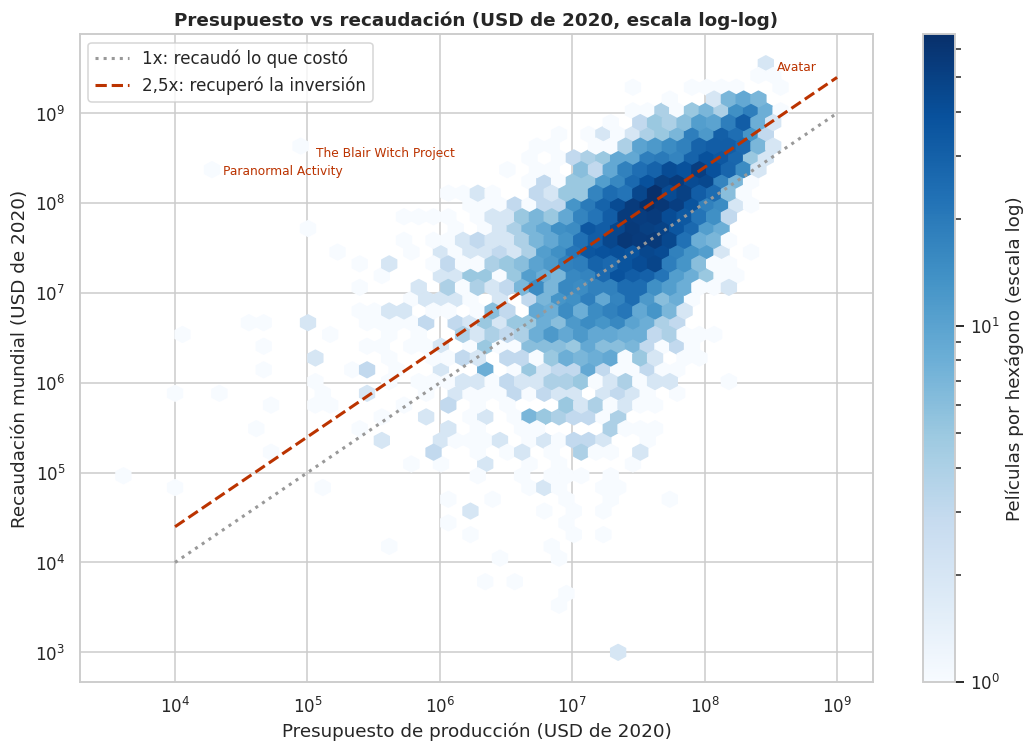

Elasticidad recaudación-presupuesto (pendiente log-log): 0.93
                   pct_recupera  dispersion_log_multiplo
tramo_presupuesto                                       
Bajo (<10 MM)              0.49                     0.88
Medio (10-40 MM)           0.36                     0.63
Alto (40-100 MM)           0.34                     0.50
Tanque (>100 MM)           0.48                     0.39


In [69]:
figura, eje = plt.subplots(figsize=(10, 7))
hexagonos = eje.hexbin(base["presupuesto_real"], base["recaudacion_real"].clip(lower=1e3), gridsize=45,
                       xscale="log", yscale="log", bins="log", cmap="Blues", mincnt=1)
figura.colorbar(hexagonos, ax=eje, label="Películas por hexágono (escala log)")
rango = np.logspace(4, 9, 50)
eje.plot(rango, rango, color=GRIS, ls=":", lw=2, label="1x: recaudó lo que costó")
eje.plot(rango, rango * UMBRAL_RECUPERO, color=ROJO, ls="--", lw=2, label="2,5x: recuperó la inversión")
for titulo in ["Paranormal Activity", "The Blair Witch Project", "Avatar"]:
    fila = base[base["titulo"] == titulo].iloc[0]
    eje.annotate(titulo, (fila["presupuesto_real"], fila["recaudacion_real"]), fontsize=8,
                 xytext=(8, -4), textcoords="offset points", color=ROJO)
eje.set_title("Presupuesto vs recaudación (USD de 2020, escala log-log)")
eje.set_xlabel("Presupuesto de producción (USD de 2020)")
eje.set_ylabel("Recaudación mundial (USD de 2020)")
eje.legend(loc="upper left")
figura.tight_layout()
guardar_figura(figura, "06_presupuesto_vs_recaudacion_hexbin.png")
plt.show()

pendiente, ordenada = np.polyfit(np.log10(base["presupuesto_real"]), np.log10(base["recaudacion_real"].clip(lower=1e3)), 1)
print(f"Elasticidad recaudación-presupuesto (pendiente log-log): {pendiente:.2f}")
print(base.groupby("tramo_presupuesto", observed=True).agg(
    pct_recupera=("recupero_inversion", "mean"),
    dispersion_log_multiplo=("multiplo_bruto", lambda serie: np.log10(serie.clip(lower=1e-3)).std())).round(2).to_string())

**Conclusión.** La recaudación aumenta casi proporcionalmente con el presupuesto: una elasticidad de 0,93 indica que un aumento del 1% en el presupuesto se asocia con un incremento aproximado del 0,93% en la recaudación. Sin embargo, gastar más no garantiza recuperar la inversión. La mayoría de las películas se concentra entre las líneas de 1x y 2,5x, lo que significa que recuperan parte de sus costos, pero no alcanzan el umbral de rentabilidad establecido. Además, la dispersión disminuye a medida que aumenta el presupuesto (0,88 en películas de bajo presupuesto frente a 0,39 en las de mayor presupuesto). Esto indica que las películas más baratas presentan resultados más variables, mientras que las producciones de mayor presupuesto tienen retornos relativamente más estables.

<h2 style='font-weight:bold; color:#003366;'>4.5 Gráfico interactivo (Plotly): el plano riesgo-retorno</h2>

Este gráfico permite comparar la rentabilidad y el riesgo de los distintos segmentos de películas, considerando el género, el presupuesto y las franquicias. Cada punto representa un segmento y su tamaño indica la cantidad de películas. Se pueden comparar dos medidas de riesgo: la probabilidad de pérdida y el peor decil. Los rombos representan los segmentos que forman parte de la frontera eficiente, es decir, aquellos que no son superados por otros en términos de rentabilidad y riesgo.

In [70]:
datos_plano = segmentos.reset_index().assign(
    prob_perdida_pct=lambda tabla: tabla["prob_perdida"] * 100,
    retorno_mediano_pct=lambda tabla: tabla["retorno_neto_mediano"] * 100,
    peor_decil_pct=lambda tabla: tabla["retorno_peor_decil"] * 100,
    grupo=lambda tabla: tabla["segmento"].str.split(" · ").str[0],
)
COLORES_GRUPO = dict(zip(sorted(datos_plano["grupo"].unique()), px.colors.qualitative.Bold + px.colors.qualitative.Safe))
EJES = {"prob": ("prob_perdida_pct", "Probabilidad de no recuperar la inversión (%)", "en_frontera"),
        "cola": ("peor_decil_pct", "Retorno neto del peor decil (%) — más a la derecha, menos se pierde", "en_frontera_cola")}

figura_plano = go.Figure()
for clave_eje, (columna_x, _, columna_frontera) in EJES.items():
    visible = clave_eje == "prob"
    for grupo, datos_grupo in datos_plano.groupby("grupo"):
        figura_plano.add_trace(go.Scatter(
            x=datos_grupo[columna_x], y=datos_grupo["retorno_mediano_pct"], mode="markers", name=grupo,
            legendgroup=grupo, showlegend=visible, visible=visible,
            marker={"size": np.sqrt(datos_grupo["peliculas"]) * 2.2, "color": COLORES_GRUPO[grupo], "opacity": 0.8,
                    "line": {"width": np.where(datos_grupo[columna_frontera], 3, 0.5), "color": "black"},
                    "symbol": np.where(datos_grupo[columna_frontera], "diamond", "circle")},
            customdata=datos_grupo[["segmento", "peliculas", "prob_perdida_pct", "peor_decil_pct", "presupuesto_mediano_mm"]],
            hovertemplate=("<b>%{customdata[0]}</b><br>Películas: %{customdata[1]}<br>Retorno neto mediano: %{y:.0f}%"
                           "<br>Prob. de pérdida: %{customdata[2]:.0f}%<br>Peor decil: %{customdata[3]:.0f}%"
                           "<br>Presupuesto mediano: USD %{customdata[4]:.0f} MM<extra></extra>")))
    frontera = datos_plano[datos_plano[columna_frontera]].sort_values(columna_x)
    figura_plano.add_trace(go.Scatter(x=frontera[columna_x], y=frontera["retorno_mediano_pct"], mode="lines",
                                      line={"color": "black", "width": 1.5, "dash": "dot"}, name="Frontera eficiente",
                                      visible=visible, showlegend=visible, hoverinfo="skip"))
trazas_por_eje = len(figura_plano.data) // 2
botones = []
for indice, (clave_eje, (_, titulo_x, _)) in enumerate(EJES.items()):
    visibilidad = [indice == 0] * trazas_por_eje + [indice == 1] * trazas_por_eje
    botones.append({"label": "Riesgo = probabilidad de pérdida" if clave_eje == "prob" else "Riesgo = peor decil",
                    "method": "update",
                    "args": [{"visible": visibilidad, "showlegend": visibilidad}, {"xaxis.title.text": titulo_x,
                             "xaxis.autorange": "reversed" if clave_eje == "prob" else True}]})
figura_plano.add_hline(y=0, line_dash="dash", line_color="black", annotation_text="Umbral de recupero (2,5x)")
figura_plano.update_layout(
    title="Plano riesgo-retorno por segmento (arriba a la derecha = mejor; rombos = frontera eficiente)",
    xaxis={"title": EJES["prob"][1], "autorange": "reversed"}, yaxis={"title": "Retorno neto mediano (%)"},
    height=620, updatemenus=[{"buttons": botones, "direction": "down", "x": 1.0, "xanchor": "right", "y": 1.13}],
    legend={"title": "Grupo (tamaño = cantidad de películas)"})
figura_plano.write_html(CARPETA_SALIDAS / "plano_riesgo_retorno.html", include_plotlyjs="cdn")
figura_plano.show()

**Conclusión.** Con cualquiera de las dos medidas de riesgo, los segmentos se ordenan en una diagonal: lo que rinde
más también arriesga menos, salvo en la esquina superior. Arriba quedan el terror de bajo presupuesto y las
franquicias; en el piso, policiales, dramas y biografías de presupuesto medio. Al cambiar al peor decil, la frontera se
"abre" e incorpora a las franquicias tanque: son el segmento donde menos se pierde en el escenario malo. El gráfico
resume la tesis: **combinar el retorno del terror barato con la protección de las franquicias**.

<h2 style='font-weight:bold; color:#003366;'>4.6 Segundo interactivo (Plotly): cada película, con su título</h2>

El mismo cruce presupuesto-recaudación del 4.4 pero película por película: con zoom y *hover* se puede identificar
cada caso extremo (por ejemplo, para responder en la defensa "¿cuál es ese punto?"). Se puede filtrar por género
haciendo clic en la leyenda.

In [71]:
datos_peliculas = base.assign(
    presupuesto_mm=base["presupuesto_real"] / 1e6,
    recaudacion_mm=base["recaudacion_real"].clip(lower=1e3) / 1e6,
    resultado=np.where(base["recupero_inversion"], "Recuperó (>= 2,5x)", "No recuperó"),
)
figura_peliculas = px.scatter(
    datos_peliculas, x="presupuesto_mm", y="recaudacion_mm", color="genero_analisis", log_x=True, log_y=True,
    opacity=0.45, hover_name="titulo", render_mode="webgl",
    hover_data={"anio_estreno": True, "multiplo_bruto": ":.2f", "resultado": True, "presupuesto_mm": ":.1f",
                "recaudacion_mm": ":.1f", "genero_analisis": False},
    labels={"presupuesto_mm": "Presupuesto (USD MM de 2020, log)", "recaudacion_mm": "Recaudación (USD MM de 2020, log)",
            "genero_analisis": "Género", "anio_estreno": "Año", "multiplo_bruto": "Múltiplo", "resultado": "Resultado"},
    title="Presupuesto vs recaudación por película (clic en la leyenda para filtrar géneros)",
)
rango_mm = np.logspace(-2.5, 3, 20)
figura_peliculas.add_trace(go.Scatter(x=rango_mm, y=rango_mm * UMBRAL_RECUPERO, mode="lines", name="Umbral 2,5x",
                                      line={"color": "black", "dash": "dash"}))
figura_peliculas.update_layout(height=600)
figura_peliculas.write_html(CARPETA_SALIDAS / "peliculas_presupuesto_recaudacion.html", include_plotlyjs="cdn")
figura_peliculas.show()

**Conclusión.** La gran mayoría de las películas se ubica entre las líneas de 1× y 2,5×, o debajo: recaudan algo, pero
no lo suficiente para recuperar la inversión total. Los casos espectaculares por encima de la línea están en el
extremo izquierdo (presupuestos mínimos), lo que confirma que los múltiplos gigantes son un fenómeno de
micropresupuestos y no algo que se pueda escalar a USD 500 MM.

#Etapa 5 · La tesis de inversión

Para definir la tesis de inversión, utilizamos únicamente las películas estrenadas entre 1980 y 2014. Las películas de 2015 a 2020 se reservan para la Etapa 6, donde evaluaremos si los resultados obtenidos se mantienen fuera del período de entrenamiento.

#5.1 Separación entrenamiento / prueba</h2>

In [72]:
entrenamiento = base[base["anio_estreno"] <= ANIO_FIN_ENTRENAMIENTO].copy()
prueba = base[base["anio_estreno"] > ANIO_FIN_ENTRENAMIENTO].copy()
print(f"Entrenamiento (1980-{ANIO_FIN_ENTRENAMIENTO}): {len(entrenamiento):,} películas")
print(f"Prueba ({ANIO_FIN_ENTRENAMIENTO + 1}-2020):        {len(prueba):,} películas "
      f"(de las cuales {(prueba['anio_estreno'] == 2020).sum()} son de 2020)")

Entrenamiento (1980-2014): 4,683 películas
Prueba (2015-2020):        706 películas (de las cuales 8 son de 2020)


#5.2 Definición de arquetipos: criterios verificables en los datos

A partir de los resultados anteriores, seleccionamos cinco posibles estrategias de inversión, diferenciadas por género, presupuesto y pertenencia a una franquicia. Para determinar cuáles incluir en la tesis, establecemos dos condiciones que deben cumplirse durante el período de entrenamiento:

1. **Rentabilidad positiva:** el retorno neto mediano debe ser mayor a cero, equivalente a un múltiplo de recaudación superior a 2,5 veces el presupuesto.
2. **Riesgo inferior al de la industria:** la probabilidad de no recuperar la inversión debe ser menor que la observada para el conjunto de películas.

Cada película se asigna a una sola categoría, siguiendo el orden de prioridad establecido en el código. Por ejemplo, una secuela animada que cumple los requisitos de presupuesto se clasifica como franquicia.

In [73]:
CANDIDATOS = {
    "Franquicia de estudio": "Secuela/precuela/saga con presupuesto >= USD 40 MM (de 2020)",
    "Animación de estudio": "Género Animación con presupuesto >= USD 40 MM (no secuela)",
    "Terror de bajo presupuesto": "Género Terror o Suspenso con presupuesto < USD 20 MM",
    "Acción/aventura original tanque": "Acción o Aventura, no secuela, presupuesto >= USD 100 MM",
    "Comedia/drama de bajo presupuesto": "Comedia o Drama con presupuesto < USD 10 MM",
}


def asignar_arquetipo(peliculas_tabla: pd.DataFrame) -> pd.Series:
    """Asigna a cada película su arquetipo según los criterios de CANDIDATOS (en orden de prioridad)."""
    presupuesto = peliculas_tabla["presupuesto_real"]
    genero = peliculas_tabla["genero"]
    condiciones = [
        peliculas_tabla["es_secuela"] & (presupuesto >= 40e6),
        (genero == "Animación") & (presupuesto >= 40e6),
        genero.isin(["Terror", "Suspenso"]) & (presupuesto < 20e6),
        genero.isin(["Acción", "Aventura"]) & ~peliculas_tabla["es_secuela"] & (presupuesto >= 100e6),
        genero.isin(["Comedia", "Drama"]) & (presupuesto < 10e6),
    ]
    return pd.Series(np.select(condiciones, list(CANDIDATOS), default="Fuera de la tesis"),
                     index=peliculas_tabla.index)


for tabla in (entrenamiento, prueba, base):
    tabla["arquetipo"] = asignar_arquetipo(tabla)

riesgo_industria_entrenamiento = 1 - entrenamiento["recupero_inversion"].mean()
evaluacion = resumir_retorno(entrenamiento, "arquetipo")
evaluacion["peliculas_por_anio"] = entrenamiento.groupby("arquetipo")["anio_estreno"].agg(
    lambda serie: len(serie) / serie.nunique())
evaluacion["criterio"] = evaluacion.index.map(CANDIDATOS)
evaluacion["entra_a_la_tesis"] = (
    (evaluacion["retorno_neto_mediano"] > 0) & (evaluacion["prob_perdida"] < riesgo_industria_entrenamiento)
    & (evaluacion.index != "Fuera de la tesis")
)
print(f"Probabilidad de pérdida de una película al azar (entrenamiento): {riesgo_industria_entrenamiento:.0%}")
evaluacion.sort_values("retorno_neto_mediano", ascending=False)[
    ["criterio", "peliculas", "multiplo_medio", "multiplo_mediano", "retorno_neto_mediano", "prob_perdida",
     "retorno_peor_decil", "presupuesto_mediano_mm", "peliculas_por_anio", "entra_a_la_tesis"]
].style.format({**FORMATO_RESUMEN, "peliculas_por_anio": "{:.1f}"})

Probabilidad de pérdida de una película al azar (entrenamiento): 63%


,criterio,peliculas,multiplo_medio,multiplo_mediano,retorno_neto_mediano,prob_perdida,retorno_peor_decil,presupuesto_mediano_mm,peliculas_por_anio,entra_a_la_tesis
arquetipo,,,,,,,,,,
Terror de bajo presupuesto,Género Terror o Suspenso con presupuesto < USD 20 MM,137,135.13x,3.55x,+42%,36%,-86%,6.8,4.3,True
Franquicia de estudio,Secuela/precuela/saga con presupuesto >= USD 40 MM (de 2020),260,3.65x,2.87x,+15%,42%,-66%,89.5,7.6,True
Animación de estudio,Género Animación con presupuesto >= USD 40 MM (no secuela),128,3.37x,2.61x,+5%,48%,-80%,104.7,4.6,True
Acción/aventura original tanque,"Acción o Aventura, no secuela, presupuesto >= USD 100 MM",255,2.59x,2.16x,-14%,58%,-75%,140.7,8.5,False
Comedia/drama de bajo presupuesto,Comedia o Drama con presupuesto < USD 10 MM,399,7.29x,2.06x,-18%,55%,-96%,4.9,11.4,False
Fuera de la tesis,nan,"3,504",2.68x,1.51x,-40%,68%,-91%,32.8,100.1,False


In [74]:
ARQUETIPOS_TESIS = evaluacion.index[evaluacion["entra_a_la_tesis"]].tolist()
print("Arquetipos que entran a la tesis:", ARQUETIPOS_TESIS)

# Intervalos de confianza de la mediana: ¿la ventaja de cada arquetipo es robusta?
for arquetipo in ARQUETIPOS_TESIS + ["Fuera de la tesis"]:
    mediana, inferior, superior = mediana_con_intervalo(
        entrenamiento.loc[entrenamiento["arquetipo"] == arquetipo, "multiplo_bruto"])
    print(f"  {arquetipo:<30} múltiplo mediano {mediana:.2f}x  (IC 90%: {inferior:.2f}x - {superior:.2f}x)")

Arquetipos que entran a la tesis: ['Animación de estudio', 'Franquicia de estudio', 'Terror de bajo presupuesto']
  Animación de estudio           múltiplo mediano 2.61x  (IC 90%: 2.18x - 2.90x)
  Franquicia de estudio          múltiplo mediano 2.87x  (IC 90%: 2.66x - 3.15x)
  Terror de bajo presupuesto     múltiplo mediano 3.55x  (IC 90%: 3.02x - 4.67x)
  Fuera de la tesis              múltiplo mediano 1.51x  (IC 90%: 1.45x - 1.56x)


**Conclusión.** De los cinco candidatos, **tres pasan los dos filtros** en el período de entrenamiento:

| Arquetipo | Múltiplo mediano (IC 90%) | Prob. pérdida | Peor decil | Rol en el portafolio |
|---|---|---|---|---|
| Terror de bajo presupuesto | 3,55× (3,0-4,7) | 36% | −86% | Motor de retorno, tickets chicos |
| Franquicia de estudio | 2,87× (2,7-3,2) | 42% | −66% | Base estable, la mejor protección de cola |
| Animación de estudio | 2,61× (2,2-2,9) | 48% | −80% | Diversificación de público (familiar) |
| *Fuera de la tesis* | *1,51× (1,45-1,56)* | *68%* | *−91%* | — |

De los cinco candidatos analizados, tres cumplen ambas condiciones: terror de bajo presupuesto, franquicias de estudio y animación de estudio. El terror presenta la mayor rentabilidad mediana (+42%) y la menor probabilidad de pérdida (36%), seguido por las franquicias (+15% y 42%) y la animación (+5% y 48%).

Por otro lado, las películas originales de acción y aventura de gran presupuesto y las comedias y dramas de bajo presupuesto quedan descartadas porque sus retornos medianos son negativos (−14% y −18%, respectivamente).

Además, los intervalos de confianza del múltiplo mediano de los tres segmentos seleccionados se encuentran por encima del intervalo correspondiente al resto de la industria, lo que aporta evidencia a favor de las diferencias observadas en rentabilidad.

#5.3 Asignación de los USD 500 millones y coherencia con el presupuesto típico

Para distribuir los USD 500 millones del fondo, consideramos el presupuesto habitual de cada tipo de película. Las franquicias y las producciones animadas tienen presupuestos elevados, cercanos a USD 90 y 100 millones, respectivamente. Financiar completamente estas películas limitaría la cantidad de proyectos en los que podríamos invertir.

Por este motivo, proponemos financiar el 25% del presupuesto de cada franquicia o película animada, mientras que en las producciones de terror de bajo presupuesto el fondo financiaría el 100%. De esta manera, podemos participar en una mayor cantidad de proyectos y diversificar la inversión.

La cantidad de proyectos se calcula dividiendo el capital asignado a cada categoría entre el monto que aporta el fondo por película:

**Cantidad de proyectos = Capital asignado / (Participación × Presupuesto mediano)**

También consideramos la cantidad de películas que históricamente se producen por año en cada categoría, para evitar proponer una inversión que supere la oferta disponible. En particular, el terror de bajo presupuesto tiene una oferta más limitada, por lo que establecemos un máximo del 15% del fondo para este segmento.

In [75]:
PARTICIPACION = {"Franquicia de estudio": 0.25, "Animación de estudio": 0.25, "Terror de bajo presupuesto": 1.00}
presupuesto_tipico = entrenamiento.groupby("arquetipo")["presupuesto_real"].median()

# Peso máximo de cada arquetipo = oferta histórica por año x años de colocación x ticket típico / capital
peso_maximo = (evaluacion["peliculas_por_anio"] * ANIOS_DE_COLOCACION
               * presupuesto_tipico * pd.Series(PARTICIPACION) / CAPITAL_FONDO_USD).reindex(list(PARTICIPACION))
print("Peso máximo que admite la oferta histórica de cada arquetipo:")
print(peso_maximo.map("{:.0%}".format).to_string())
PESO_MAXIMO_TERROR = np.floor(peso_maximo["Terror de bajo presupuesto"] * 20) / 20  # redondeo hacia abajo al 5%
print(f"-> Tope para terror de bajo presupuesto: {PESO_MAXIMO_TERROR:.0%} del fondo\n")

# Pools de la simulación: múltiplos históricos de entrenamiento, con tope en el percentil 95 de TODA la industria.
# Caso base conservador: no contamos con que aparezca otra Paranormal Activity (la sensibilidad sin tope está en 7.2).
TOPE_MULTIPLO = entrenamiento["multiplo_bruto"].quantile(PERCENTIL_TOPE_MULTIPLO)
multiplos_entrenamiento = {
    arquetipo: entrenamiento.loc[entrenamiento["arquetipo"] == arquetipo, "multiplo_bruto"].clip(upper=TOPE_MULTIPLO).to_numpy()
    for arquetipo in entrenamiento["arquetipo"].unique()
}
# Shock común de mercado: cuánto se apartó la mediana de cada año de la mediana histórica
FACTORES_MERCADO = (entrenamiento.groupby("anio_estreno")["multiplo_bruto"].median()
                    / entrenamiento["multiplo_bruto"].median()).to_numpy()
print(f"Tope del múltiplo por proyecto (p95 de la industria hasta 2014): {TOPE_MULTIPLO:.1f}x")
print(f"Factor de mercado anual: mínimo {FACTORES_MERCADO.min():.2f} (año malo) | máximo {FACTORES_MERCADO.max():.2f} (año bueno)")


def armar_cartera(pesos: dict[str, float], participacion: dict[str, float]) -> pd.DataFrame:
    """Traduce pesos del fondo en asignación, ticket por proyecto y cantidad de proyectos."""
    cartera = pd.DataFrame({"peso": pd.Series(pesos)})
    cartera["asignacion_usd"] = cartera["peso"] * CAPITAL_FONDO_USD
    cartera["presupuesto_tipico_usd"] = presupuesto_tipico.reindex(cartera.index)
    cartera["participacion"] = pd.Series(participacion).reindex(cartera.index)
    cartera["ticket_tipico_usd"] = cartera["presupuesto_tipico_usd"] * cartera["participacion"]
    cartera["proyectos"] = (cartera["asignacion_usd"] / cartera["ticket_tipico_usd"]).round().clip(lower=1).astype(int)
    return cartera


def evaluar_cartera(cartera: pd.DataFrame, multiplos: dict, **opciones) -> tuple[pd.DataFrame, dict]:
    """Simula una cartera y devuelve las simulaciones y su resumen."""
    simulacion = simular_portafolio(
        multiplos_por_arquetipo=multiplos,
        asignacion_usd=cartera["asignacion_usd"].to_dict(),
        proyectos_por_arquetipo=cartera["proyectos"].to_dict(),
        simulaciones=opciones.get("simulaciones", SIMULACIONES),
        semilla=SEMILLA,
        umbral_recupero=opciones.get("umbral", UMBRAL_RECUPERO),
        factores_mercado=opciones.get("factores", FACTORES_MERCADO),
    )
    return simulacion, resumir_simulacion(simulacion["retorno_portafolio"])

Peso máximo que admite la oferta histórica de cada arquetipo:
Franquicia de estudio         103%
Animación de estudio           72%
Terror de bajo presupuesto     18%
-> Tope para terror de bajo presupuesto: 15% del fondo

Tope del múltiplo por proyecto (p95 de la industria hasta 2014): 10.1x
Factor de mercado anual: mínimo 0.54 (año malo) | máximo 1.68 (año bueno)


In [76]:
# Grilla de pesos: terror entre 5% y su tope, animación entre 20% y 45%, franquicias el resto (mínimo 25%)
resultados_grilla = []
for peso_terror in np.arange(0.05, PESO_MAXIMO_TERROR + 1e-9, 0.05).round(2):
    for peso_animacion in np.arange(0.20, 0.46, 0.05):
        peso_franquicia = 1 - peso_terror - peso_animacion
        if peso_franquicia < 0.25 - 1e-9:
            continue
        pesos = {"Franquicia de estudio": round(peso_franquicia, 2),
                 "Animación de estudio": round(peso_animacion, 2),
                 "Terror de bajo presupuesto": peso_terror}
        _, resumen = evaluar_cartera(armar_cartera(pesos, PARTICIPACION), multiplos_entrenamiento,
                                     simulaciones=4_000)
        resultados_grilla.append({**{f"peso_{clave.split()[0].lower()}": valor for clave, valor in pesos.items()},
                                  **resumen})
grilla = pd.DataFrame(resultados_grilla)
# Criterio de elección: mínima probabilidad de perder capital; entre empates (±1 pp), mayor retorno mediano
mejor_riesgo = grilla["prob_perder_capital"].min()
candidatas = grilla[grilla["prob_perder_capital"] <= mejor_riesgo + 0.01]
eleccion = candidatas.sort_values("retorno_mediano", ascending=False).iloc[0]
print("Grilla de pesos evaluada (4.000 simulaciones cada una):")
display(grilla.sort_values(["prob_perder_capital", "retorno_mediano"], ascending=[True, False]).head(10)
        .style.format({columna: "{:.0%}" for columna in grilla.columns}))
print("Elegida:", eleccion[["peso_franquicia", "peso_animación", "peso_terror"]].to_dict())

Grilla de pesos evaluada (4.000 simulaciones cada una):


,peso_franquicia,peso_animación,peso_terror,retorno_mediano,retorno_medio,prob_perder_capital,prob_perder_mas_20pct,percentil_5,percentil_10,percentil_90
12,65%,20%,15%,39%,44%,18%,5%,-20%,-11%,107%
13,60%,25%,15%,38%,44%,19%,5%,-21%,-11%,106%
14,55%,30%,15%,37%,43%,20%,6%,-21%,-13%,105%
15,50%,35%,15%,36%,42%,20%,6%,-21%,-13%,105%
6,70%,20%,10%,36%,41%,20%,6%,-22%,-13%,104%
17,40%,45%,15%,35%,40%,21%,6%,-22%,-14%,101%
7,65%,25%,10%,36%,41%,21%,6%,-21%,-13%,101%
16,45%,40%,15%,36%,41%,21%,6%,-21%,-13%,103%
8,60%,30%,10%,34%,40%,22%,6%,-22%,-14%,101%
9,55%,35%,10%,34%,39%,22%,7%,-24%,-15%,101%


Elegida: {'peso_franquicia': 0.65, 'peso_animación': 0.2, 'peso_terror': 0.15}


In [77]:
PESOS_PROPUESTOS = {"Franquicia de estudio": float(eleccion["peso_franquicia"]),
                    "Animación de estudio": float(eleccion["peso_animación"]),
                    "Terror de bajo presupuesto": float(eleccion["peso_terror"])}
cartera_propuesta = armar_cartera(PESOS_PROPUESTOS, PARTICIPACION)

# Verificación de coherencia: proyectos por año contra la oferta histórica del arquetipo
cartera_propuesta["proyectos_por_anio"] = cartera_propuesta["proyectos"] / ANIOS_DE_COLOCACION
cartera_propuesta["oferta_historica_por_anio"] = evaluacion["peliculas_por_anio"].reindex(cartera_propuesta.index)
# El ticket real se ajusta para que la asignación se coloque completa (la cantidad de proyectos se redondeó)
cartera_propuesta["ticket_real_usd"] = cartera_propuesta["asignacion_usd"] / cartera_propuesta["proyectos"]
assert abs(cartera_propuesta["asignacion_usd"].sum() - CAPITAL_FONDO_USD) < 1, "La asignación no suma USD 500 MM"
assert (cartera_propuesta["proyectos_por_anio"] <= cartera_propuesta["oferta_historica_por_anio"]).all(),     "Algún arquetipo pide más proyectos por año de los que ofrece el mercado"
print(f"Proyectos totales: {cartera_propuesta['proyectos'].sum()} en {ANIOS_DE_COLOCACION} años | "
      f"capital colocado: USD {(cartera_propuesta['ticket_real_usd'] * cartera_propuesta['proyectos']).sum() / 1e6:,.0f} MM")
cartera_propuesta.style.format({"peso": "{:.0%}", "asignacion_usd": formato_millones, "presupuesto_tipico_usd": formato_millones,
                                "participacion": "{:.0%}", "ticket_tipico_usd": formato_millones,
                                "proyectos_por_anio": "{:.1f}", "oferta_historica_por_anio": "{:.1f}",
                                "ticket_real_usd": formato_millones})

Proyectos totales: 30 en 3 años | capital colocado: USD 500 MM


,peso,asignacion_usd,presupuesto_tipico_usd,participacion,ticket_tipico_usd,proyectos,proyectos_por_anio,oferta_historica_por_anio,ticket_real_usd
Franquicia de estudio,65%,325,89,25%,22,15,5.0,7.6,22
Animación de estudio,20%,100,105,25%,26,4,1.3,4.6,25
Terror de bajo presupuesto,15%,75,7,100%,7,11,3.7,4.3,7


**Conclusión: la asignación propuesta.**

| Arquetipo | Peso | USD MM | Presupuesto típico | Participación | Ticket | Proyectos | Por año | Oferta histórica/año |
|---|---|---|---|---|---|---|---|---|
| Franquicia de estudio | 65% | 325 | 89 | 25% | 22 | **15** | 5,0 | 7,6 |
| Animación de estudio | 20% | 100 | 105 | 25% | 26 | **4** | 1,3 | 4,6 |
| Terror de bajo presupuesto | 15% | 75 | 7 | 100% | 7 | **11** | 3,7 | 4,3 |
| **Total** | 100% | 500 | | | | **30** | 10 | |

- La distribución seleccionada asigna el **65% del capital a franquicias de estudio, el 20% a animación y el 15% a terror de bajo presupuesto**. Esto representa una inversión de USD 325, 100 y 75 millones, respectivamente.

Con esta distribución, el fondo participaría en 30 proyectos durante tres años: 15 franquicias, 4 películas animadas y 11 producciones de terror. En los tres casos, la cantidad anual de proyectos se mantiene por debajo de la oferta histórica de cada categoría.

La elección de estos porcentajes surge de comparar distintas combinaciones mediante simulaciones, priorizando aquellas con menor probabilidad de pérdida. El terror recibe el máximo permitido por su disponibilidad histórica, mientras que las franquicias concentran la mayor parte del capital y la animación permite diversificar la cartera.

Cabe aclarar que los presupuestos están expresados en dólares de 2020, por lo que los costos actuales podrían ser mayores y afectar la cantidad de proyectos que se pueden financiar con el mismo capital.

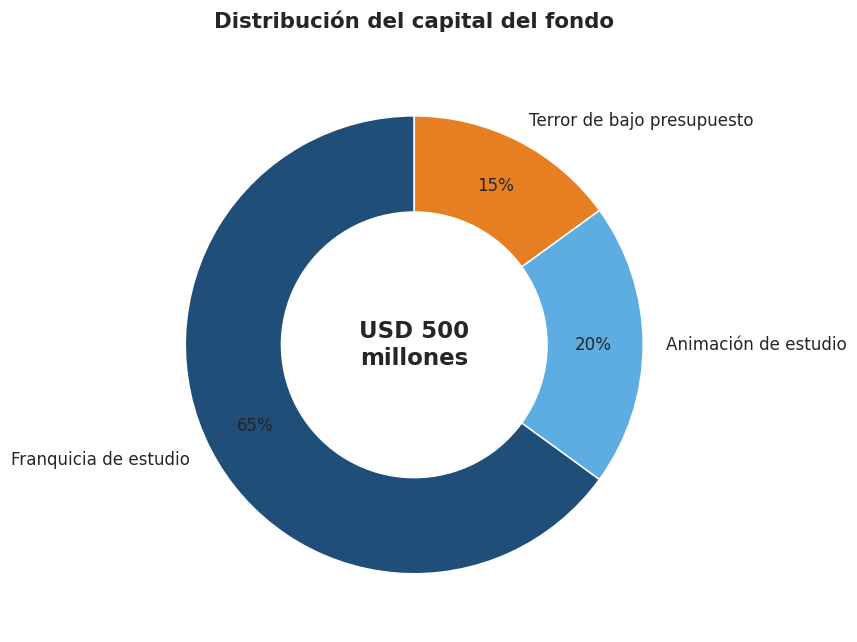

In [78]:
# Distribución del capital del fondo
pesos = cartera_propuesta["peso"] * 100

fig, ax = plt.subplots(figsize=(8, 6))

colores = ["#1F4E79", "#5DADE2", "#E67E22"]

ax.pie(
    pesos,
    labels=pesos.index,
    autopct="%1.0f%%",
    startangle=90,
    colors=colores,
    pctdistance=0.78,
    wedgeprops={"width": 0.42, "edgecolor": "white"},
    textprops={"fontsize": 11}
)

ax.text(0, 0, "USD 500\nmillones",
        ha="center", va="center",
        fontsize=15, fontweight="bold")

ax.set_title("Distribución del capital del fondo",
             fontsize=14, fontweight="bold", pad=20)

plt.tight_layout()
guardar_figura(fig, "distribucion_capital.png")
plt.show()


El 65% del capital se destina a franquicias, el 20% a animación y el 15% a terror de bajo presupuesto. Esta distribución busca combinar rentabilidad, diversificación y capacidad real de inversión.

#5.4 Retorno esperado del portafolio y probabilidad de perder capital (simulación)

**Método (bootstrap con shock de mercado).** En cada una de las 10.000 simulaciones:

1. Se sortea un "año de mercado" histórico, que escala hacia arriba o hacia abajo a **todas** las películas del fondo
   (en un mal año para la industria les va mal a todas juntas).
2. Para cada arquetipo se sortean, con reposición, tantas películas históricas (≤ 2014) del arquetipo como proyectos
   tiene la cartera, con el múltiplo topeado en el p95 de la industria.
3. Cada proyecto devuelve `ticket × múltiplo / 2,5`, y se suma el valor final del fondo.

No usamos el promedio en ningún momento: reportamos la **mediana** de las simulaciones y sus percentiles.

In [79]:
simulacion_propuesta, resumen_propuesta = evaluar_cartera(cartera_propuesta, multiplos_entrenamiento)
print("PORTAFOLIO PROPUESTO (10.000 simulaciones)")
for indicador, valor in resumen_propuesta.items():
    formato = "{:.1%}" if indicador.startswith("prob") else "{:+.1%}"
    print(f"  {indicador:<24} {formato.format(valor)}")
print(f"\n  Valor final mediano del fondo: USD {simulacion_propuesta['valor_final_usd'].median() / 1e6:,.0f} MM "
      f"sobre USD {CAPITAL_FONDO_USD / 1e6:,.0f} MM")
print(f"  En el peor 5% de los escenarios el fondo termina con USD "
      f"{simulacion_propuesta['valor_final_usd'].quantile(0.05) / 1e6:,.0f} MM o menos")
print("\nRetorno mediano y probabilidad de pérdida de cada arquetipo dentro del portafolio:")
for arquetipo in cartera_propuesta.index:
    columna = simulacion_propuesta[f"retorno_{arquetipo}"]
    print(f"  {arquetipo:<28} mediana {columna.median():+.0%} | P(pérdida) {(columna < 0).mean():.1%}")

PORTAFOLIO PROPUESTO (10.000 simulaciones)
  retorno_mediano          +38.8%
  retorno_medio            +44.1%
  prob_perder_capital      18.3%
  prob_perder_mas_20pct    4.7%
  percentil_5              -19.6%
  percentil_10             -10.2%
  percentil_90             +106.5%

  Valor final mediano del fondo: USD 694 MM sobre USD 500 MM
  En el peor 5% de los escenarios el fondo termina con USD 402 MM o menos

Retorno mediano y probabilidad de pérdida de cada arquetipo dentro del portafolio:
  Franquicia de estudio        mediana +33% | P(pérdida) 23.3%
  Animación de estudio         mediana +13% | P(pérdida) 40.1%
  Terror de bajo presupuesto   mediana +83% | P(pérdida) 6.2%


In [80]:
# Alternativas: ¿por qué no todo en el mejor segmento? ¿Qué pasa si se elige al azar?
proyectos_totales = int(cartera_propuesta["proyectos"].sum())
ticket_mercado = CAPITAL_FONDO_USD / proyectos_totales
ALTERNATIVAS = {
    "Propuesta (3 arquetipos)": cartera_propuesta,
    "Todo en terror de bajo presupuesto": armar_cartera({"Terror de bajo presupuesto": 1.0}, PARTICIPACION),
    "Todo en franquicias": armar_cartera({"Franquicia de estudio": 1.0}, PARTICIPACION),
    "Todo en animación": armar_cartera({"Animación de estudio": 1.0}, PARTICIPACION),
    "Mercado: películas al azar": pd.DataFrame({"asignacion_usd": [CAPITAL_FONDO_USD],
                                               "proyectos": [proyectos_totales]}, index=["Mercado"]),
}
multiplos_con_mercado = {**multiplos_entrenamiento,
                         "Mercado": entrenamiento["multiplo_bruto"].clip(upper=TOPE_MULTIPLO).to_numpy()}
filas_alternativas = []
simulaciones_alternativas = {}
for nombre, cartera in ALTERNATIVAS.items():
    simulacion, resumen = evaluar_cartera(cartera, multiplos_con_mercado)
    simulaciones_alternativas[nombre] = simulacion["retorno_portafolio"]
    proyectos_por_anio = cartera["proyectos"].sum() / ANIOS_DE_COLOCACION
    filas_alternativas.append({"cartera": nombre, "proyectos": int(cartera["proyectos"].sum()),
                               "proyectos_por_anio": proyectos_por_anio, **resumen})
comparacion_carteras = pd.DataFrame(filas_alternativas).set_index("cartera")
comparacion_carteras.to_csv(CARPETA_SALIDAS / "comparacion_carteras.csv")
comparacion_carteras.style.format({"proyectos_por_anio": "{:.1f}", **{columna: "{:+.1%}" for columna in
                                   ["retorno_mediano", "retorno_medio", "percentil_5", "percentil_10", "percentil_90"]},
                                   "prob_perder_capital": "{:.1%}", "prob_perder_mas_20pct": "{:.1%}"})

,proyectos,proyectos_por_anio,retorno_mediano,retorno_medio,prob_perder_capital,prob_perder_mas_20pct,percentil_5,percentil_10,percentil_90
cartera,,,,,,,,,
Propuesta (3 arquetipos),30,10.0,+38.8%,+44.1%,18.3%,4.7%,-19.6%,-10.2%,+106.5%
Todo en terror de bajo presupuesto,73,24.3,+88.8%,+93.4%,1.1%,0.0%,+13.3%,+23.9%,+170.6%
Todo en franquicias,22,7.3,+32.7%,+38.7%,22.2%,6.4%,-22.3%,-14.7%,+99.9%
Todo en animación,19,6.3,+17.4%,+23.5%,33.9%,14.4%,-32.7%,-24.8%,+80.5%
Mercado: películas al azar,30,10.0,-2.3%,+3.4%,52.2%,29.8%,-44.5%,-37.7%,+52.3%


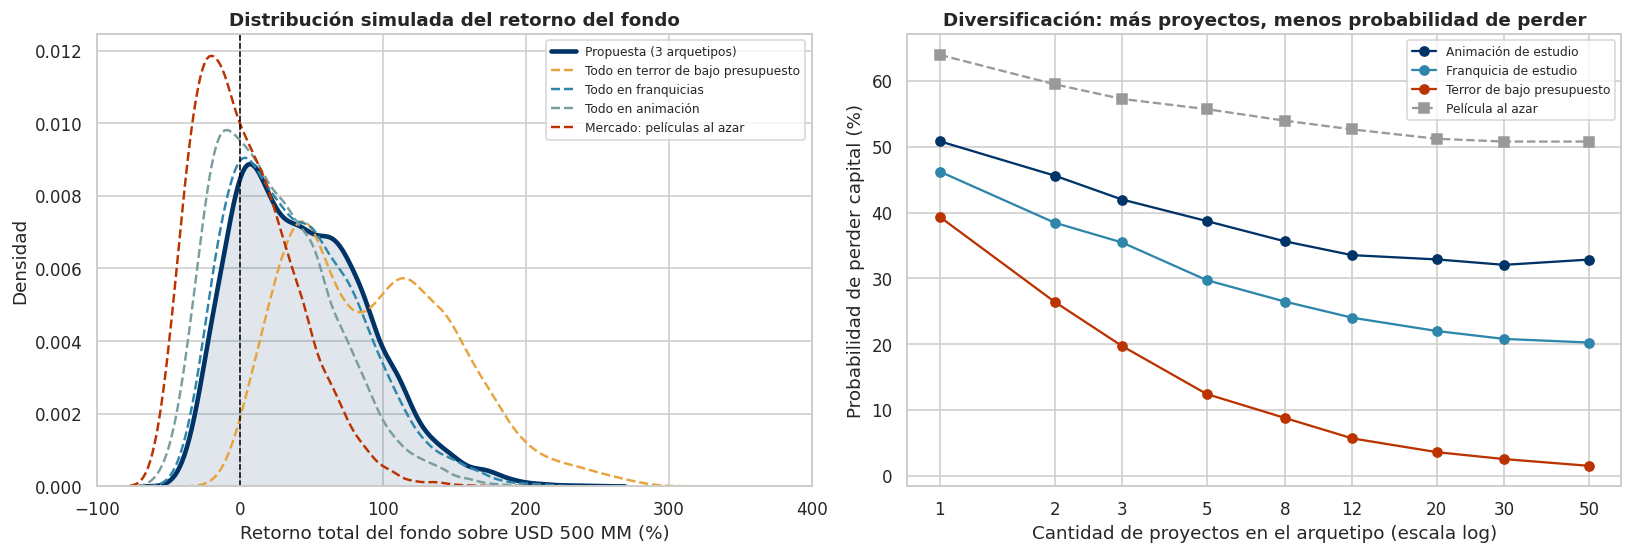

In [81]:
figura, (eje_dist, eje_div) = plt.subplots(1, 2, figsize=(15, 5.2))
for (nombre, retornos), color in zip(simulaciones_alternativas.items(), [AZUL, AMARILLO, CELESTE, "#7A9E9F", ROJO]):
    es_propuesta = "Propuesta" in nombre
    sns.kdeplot(retornos * 100, ax=eje_dist, label=nombre, color=color, lw=3 if es_propuesta else 1.6,
                ls="-" if es_propuesta else "--", clip=(-100, 600))
    if es_propuesta:
        sns.kdeplot(retornos * 100, ax=eje_dist, color=color, fill=True, alpha=0.12, lw=0, clip=(-100, 600))
eje_dist.axvline(0, color="black", ls="--", lw=1)
eje_dist.set_title("Distribución simulada del retorno del fondo")
eje_dist.set_xlabel("Retorno total del fondo sobre USD 500 MM (%)")
eje_dist.set_ylabel("Densidad")
eje_dist.set_xlim(-100, 400)
eje_dist.legend(fontsize=8)

# Curva de diversificación: probabilidad de perder capital según cantidad de proyectos en cada arquetipo
cantidades = [1, 2, 3, 5, 8, 12, 20, 30, 50]
for arquetipo, color in zip(ARQUETIPOS_TESIS, [AZUL, CELESTE, ROJO]):
    probabilidades = []
    for cantidad in cantidades:
        simulacion = simular_portafolio({arquetipo: multiplos_entrenamiento[arquetipo]}, {arquetipo: 1.0},
                                        {arquetipo: cantidad}, simulaciones=4_000, semilla=SEMILLA,
                                        factores_mercado=FACTORES_MERCADO)
        probabilidades.append((simulacion["retorno_portafolio"] < 0).mean() * 100)
    eje_div.plot(cantidades, probabilidades, marker="o", color=color, label=arquetipo)
probabilidades_mercado = []
for cantidad in cantidades:
    simulacion = simular_portafolio({"Mercado": multiplos_con_mercado["Mercado"]}, {"Mercado": 1.0},
                                    {"Mercado": cantidad}, simulaciones=4_000, semilla=SEMILLA,
                                    factores_mercado=FACTORES_MERCADO)
    probabilidades_mercado.append((simulacion["retorno_portafolio"] < 0).mean() * 100)
eje_div.plot(cantidades, probabilidades_mercado, marker="s", color=GRIS, ls="--", label="Película al azar")
eje_div.set_xscale("log")
eje_div.set_xticks(cantidades)
eje_div.xaxis.set_major_formatter(mticker.FormatStrFormatter("%d"))
eje_div.xaxis.set_minor_formatter(mticker.NullFormatter())
eje_div.set_title("Diversificación: más proyectos, menos probabilidad de perder")
eje_div.set_xlabel("Cantidad de proyectos en el arquetipo (escala log)")
eje_div.set_ylabel("Probabilidad de perder capital (%)")
eje_div.legend(fontsize=8)
figura.tight_layout()
guardar_figura(figura, "07_simulacion_y_diversificacion.png")
plt.show()

**Conclusión.** Las simulaciones muestran un **retorno mediano del 38,8%**, por lo que el fondo pasaría de USD 500 millones a aproximadamente USD 694 millones. La probabilidad de perder capital es del **18,3%**, mientras que la probabilidad de perder más del 20% es del 4,7%. En el peor 5% de los escenarios, el fondo terminaría con USD 402 millones o menos.

**Comparación de estrategias.** Frente a una cartera de películas seleccionadas al azar, que presenta un retorno mediano cercano al −2% y una probabilidad de pérdida del 52%, nuestra propuesta obtiene mejores resultados tanto en rentabilidad como en riesgo.

**Gráfico de diversificación.** A medida que aumenta la cantidad de proyectos, disminuye la probabilidad de perder capital, aunque esta reducción es cada vez menor. Esto se debe a que existe un riesgo de mercado que afecta a todas las películas y que no puede eliminarse completamente mediante la diversificación.

#5.5 ¿Por qué no poner todo en el segmento de mejor retorno?

Aunque el terror de bajo presupuesto presenta los mayores retornos y la menor probabilidad de pérdida, concentrar todo el capital en este segmento puede generar riesgos. Por eso, analizamos cuatro limitaciones: la cantidad de proyectos disponibles, la dependencia de éxitos excepcionales, el tamaño de la muestra y los ciclos del género.

In [82]:
terror_entrenamiento = entrenamiento[entrenamiento["arquetipo"] == "Terror de bajo presupuesto"]
cartera_solo_terror = ALTERNATIVAS["Todo en terror de bajo presupuesto"]
print(f"1) CAPACIDAD: todo en terror exige {cartera_solo_terror['proyectos'].iloc[0]} películas en 3 años "
      f"({cartera_solo_terror['proyectos'].iloc[0] / ANIOS_DE_COLOCACION:.0f} por año). En la base aparecen "
      f"{evaluacion.loc['Terror de bajo presupuesto', 'peliculas_por_anio']:.1f} por año. El fondo tendría que "
      "financiar varias veces la producción histórica del nicho: no existen esos proyectos y, si existieran, competirían "
      "entre sí por la misma audiencia.")

aporte_top = terror_entrenamiento.nlargest(5, "multiplo_bruto")
print(f"\n2) DEPENDENCIA DE LA COLA: {len(terror_entrenamiento)} películas de terror en entrenamiento. Las 5 mejores "
      f"({', '.join(aporte_top['titulo'])}) son el {len(aporte_top) / len(terror_entrenamiento):.0%} de las películas "
      f"y suman el {aporte_top['multiplo_bruto'].sum() / terror_entrenamiento['multiplo_bruto'].sum():.0%} de los múltiplos "
      "del arquetipo.")
sin_top = terror_entrenamiento.drop(aporte_top.index)
print(f"   Sin esas 5: múltiplo medio {terror_entrenamiento['multiplo_bruto'].mean():.1f}x -> "
      f"{sin_top['multiplo_bruto'].mean():.1f}x; mediana {terror_entrenamiento['multiplo_bruto'].median():.2f}x -> "
      f"{sin_top['multiplo_bruto'].median():.2f}x")

mediana, inferior, superior = mediana_con_intervalo(terror_entrenamiento["multiplo_bruto"])
print(f"\n3) MUESTRA CHICA: el múltiplo mediano del terror es {mediana:.2f}x con IC 90% [{inferior:.2f}x, {superior:.2f}x]: "
      "un intervalo ancho, construido con pocas películas por año.")

print(f"\n4) RIESGO NO DIVERSIFICABLE DE GÉNERO: la simulación supone que las películas de terror son independientes "
      "entre sí. En la realidad los géneros tienen ciclos (modas, saturación). Medimos la variabilidad del retorno "
      "mediano del terror por quinquenio:")
print(terror_entrenamiento.groupby(pd.cut(terror_entrenamiento["anio_estreno"], [1979, 1984, 1989, 1994, 1999, 2004, 2009, 2014]),
                                   observed=True)["multiplo_bruto"].agg(["size", "median"]).round(2).to_string())

1) CAPACIDAD: todo en terror exige 73 películas en 3 años (24 por año). En la base aparecen 4.3 por año. El fondo tendría que financiar varias veces la producción histórica del nicho: no existen esos proyectos y, si existieran, competirían entre sí por la misma audiencia.

2) DEPENDENCIA DE LA COLA: 137 películas de terror en entrenamiento. Las 5 mejores (Paranormal Activity, The Blair Witch Project, The Devil Inside, The Quiet Ones, Saw) son el 4% de las películas y suman el 94% de los múltiplos del arquetipo.
   Sin esas 5: múltiplo medio 135.1x -> 9.1x; mediana 3.55x -> 3.40x

3) MUESTRA CHICA: el múltiplo mediano del terror es 3.55x con IC 90% [3.02x, 4.67x]: un intervalo ancho, construido con pocas películas por año.

4) RIESGO NO DIVERSIFICABLE DE GÉNERO: la simulación supone que las películas de terror son independientes entre sí. En la realidad los géneros tienen ciclos (modas, saturación). Medimos la variabilidad del retorno mediano del terror por quinquenio:
              siz

**Conclusión.** Aunque invertir exclusivamente en terror presenta una probabilidad simulada de pérdida cercana al 1%, esta estrategia no resulta viable por cuatro razones:

1. **Capacidad limitada:** necesitaríamos financiar 73 películas en tres años, cuando históricamente aparecen unas 4 por año.
2. **Dependencia de grandes éxitos:** las 5 películas más exitosas concentran el 94% de la suma de los múltiplos del segmento.
3. **Muestra reducida:** el intervalo de confianza de la mediana es relativamente amplio (3,02x–4,67x).
4. **Ciclos del género:** los retornos del terror varían considerablemente entre períodos.

Por lo tanto, proponemos destinar el **15% del fondo al terror**, aprovechando su rentabilidad sin superar la capacidad histórica del mercado, y diversificar el resto entre franquicias y animación.

#5.6 En qué NO invertiríamos y por qué

In [83]:
NO_INVERTIR_CRITERIO = "retorno neto mediano < 0 y probabilidad de pérdida mayor a la de la industria"
segmentos_entrenamiento = resumir_retorno(entrenamiento, ["genero_analisis", "tramo_presupuesto"],
                                          minimo_peliculas=MINIMO_PELICULAS_SEGMENTO)
segmentos_entrenamiento.index = [f"{genero} · {tramo}" for genero, tramo in segmentos_entrenamiento.index]
no_invertir = segmentos_entrenamiento[
    (segmentos_entrenamiento["retorno_neto_mediano"] < 0)
    & (segmentos_entrenamiento["prob_perdida"] > riesgo_industria_entrenamiento)
].sort_values("prob_perdida", ascending=False)
print(f"Criterio: {NO_INVERTIR_CRITERIO} ({riesgo_industria_entrenamiento:.0%}).")
print(f"Segmentos excluidos: {len(no_invertir)} de {len(segmentos_entrenamiento)}, que suman "
      f"{no_invertir['peliculas'].sum() / len(entrenamiento):.0%} de las películas.")
display(no_invertir[["peliculas", "multiplo_mediano", "retorno_neto_mediano", "prob_perdida", "retorno_peor_decil"]]
        .style.format(FORMATO_RESUMEN))

print("Otros cortes transversales a evitar (entrenamiento):")
for variable, valor in [("publico", "Sin clasificar"), ("publico", "Adulto (17+)"), ("origen", "Resto del mundo")]:
    grupo = entrenamiento[entrenamiento[variable] == valor]
    print(f"  {variable} = {valor:<18} n={len(grupo):>5,} | múltiplo mediano {grupo['multiplo_bruto'].median():.2f}x | "
          f"P(pérdida) {1 - grupo['recupero_inversion'].mean():.0%}")

Criterio: retorno neto mediano < 0 y probabilidad de pérdida mayor a la de la industria (63%).
Segmentos excluidos: 14 de 25, que suman 68% de las películas.


,peliculas,multiplo_mediano,retorno_neto_mediano,prob_perdida,retorno_peor_decil
Policial · Medio (10-40 MM),191,1.07x,-57%,75%,-96%
Aventura · Alto (40-100 MM),108,1.07x,-57%,74%,-92%
Drama · Alto (40-100 MM),191,1.30x,-48%,73%,-91%
Biografía · Alto (40-100 MM),69,1.52x,-39%,72%,-88%
Policial · Alto (40-100 MM),97,1.34x,-47%,72%,-89%
Drama · Tanque (>100 MM),39,1.59x,-36%,72%,-89%
Acción · Medio (10-40 MM),355,1.50x,-40%,70%,-89%
Policial · Bajo (<10 MM),66,1.05x,-58%,70%,-94%
Acción · Alto (40-100 MM),453,1.64x,-35%,70%,-86%
Biografía · Medio (10-40 MM),121,1.39x,-44%,69%,-93%


Otros cortes transversales a evitar (entrenamiento):
  publico = Sin clasificar     n=   55 | múltiplo mediano 0.98x | P(pérdida) 71%
  publico = Adulto (17+)       n=2,286 | múltiplo mediano 1.50x | P(pérdida) 66%
  origen = Resto del mundo    n=  913 | múltiplo mediano 1.22x | P(pérdida) 70%


**Conclusión: en qué no invertiríamos.** 14 de los 25 segmentos (el **68% de las películas** que se producen) quedan
excluidos porque su película típica pierde plata y lo hacen más seguido que la industria:

- **Policiales de cualquier presupuesto** (múltiplo mediano ~1,05-1,34×, pérdida en 70-75%).
- **Dramas y biografías de presupuesto medio y alto** (1,3-1,6×, pérdida en 65-73%).
- **Acción y comedia de presupuesto medio (10-100 MM) originales**: es el grueso de la producción de Hollywood y
  pierde en 65-70% de los casos.
- **Aventura original de presupuesto alto** (1,07×, pérdida en 74%).
- Como cortes transversales: películas **sin clasificación** (0,98×), **producciones fuera de EE.UU.** (1,22×, y con
  pocos datos) y el público **adulto (17+)** fuera del terror.

También excluimos la acción/aventura original tanque y la comedia/drama de bajo presupuesto: rinden más que estos
segmentos, pero su película típica tampoco recupera la inversión.

#5.7 Limitaciones del análisis con estos datos

1. **Sesgo por datos faltantes:** el 29% de las películas no tiene presupuesto registrado, principalmente producciones pequeñas y fracasos. Esto puede sobreestimar los retornos.

2. **La recaudación no equivale a ganancia:** utilizamos la regla de 2,5x como aproximación, pero no contamos con información completa sobre marketing, streaming y contratos de distribución. Los retornos reales dependen de estos factores.

3. **Selección adversa:** las películas disponibles para un fondo externo podrían ser menos rentables que las producciones históricas, ya que los estudios podrían reservarse los mejores proyectos.

4. **Limitaciones temporales:** los presupuestos están expresados en dólares de 2020 y no contamos con datos posteriores a ese año. Además, el streaming y la pandemia modificaron el mercado cinematográfico.

5. **Muestras pequeñas y correlación:** algunos segmentos tienen pocas películas por año. Aunque la simulación incorpora shocks generales del mercado, no contempla completamente los ciclos de cada género ni la competencia entre producciones.

6. **Limitaciones de los datos:** pueden persistir errores en las unidades de los presupuestos y la clasificación por un único género no refleja las películas híbridas.

#Etapa 6 · ¿La tesis sobrevive fuera de muestra?

En esta etapa evaluamos si nuestra estrategia de inversión sigue siendo válida con datos nuevos. Para ello, aplicamos los criterios definidos con películas de 1980–2014 a las estrenadas entre 2015 y 2020, sin modificar los parámetros.

#6.1 Cada arquetipo: entrenamiento contra prueba

In [84]:
def metricas_periodo(tabla: pd.DataFrame, periodo: str) -> pd.DataFrame:
    """Métricas por arquetipo de un período, más la fila de toda la industria."""
    resumen = resumir_retorno(tabla, "arquetipo")[["peliculas", "multiplo_mediano", "retorno_neto_mediano",
                                                   "prob_perdida", "retorno_peor_decil"]]
    industria = resumir_retorno(tabla.assign(arquetipo="Industria (todas)"), "arquetipo")[resumen.columns]
    return pd.concat([resumen, industria]).assign(periodo=periodo)


fuera_de_muestra = pd.concat([metricas_periodo(entrenamiento, "1980-2014"), metricas_periodo(prueba, "2015-2020")])
tabla_validacion = fuera_de_muestra.reset_index().pivot(index="arquetipo", columns="periodo",
                                                        values=["peliculas", "multiplo_mediano", "prob_perdida",
                                                                "retorno_peor_decil"])
# Exceso sobre la industria del mismo período: controla que el período de prueba haya sido mejor para todos
for periodo in ["1980-2014", "2015-2020"]:
    tabla_validacion[("ventaja_vs_industria_pp", periodo)] = (
        tabla_validacion[("prob_perdida", periodo)]["Industria (todas)"] - tabla_validacion[("prob_perdida", periodo)]
    ) * 100
tabla_validacion = tabla_validacion.reindex(ARQUETIPOS_TESIS + [arq for arq in CANDIDATOS if arq not in ARQUETIPOS_TESIS]
                                            + ["Fuera de la tesis", "Industria (todas)"])
tabla_validacion.to_csv(CARPETA_SALIDAS / "validacion_fuera_de_muestra.csv")
tabla_validacion.style.format({**{(m, p): "{:.2f}x" for m in ["multiplo_mediano"] for p in ["1980-2014", "2015-2020"]},
                               **{(m, p): "{:.0%}" for m in ["prob_perdida"] for p in ["1980-2014", "2015-2020"]},
                               **{(m, p): "{:+.0%}" for m in ["retorno_peor_decil"] for p in ["1980-2014", "2015-2020"]},
                               **{(m, p): "{:+.0f}" for m in ["ventaja_vs_industria_pp"] for p in ["1980-2014", "2015-2020"]},
                               **{(m, p): "{:,.0f}" for m in ["peliculas"] for p in ["1980-2014", "2015-2020"]}})

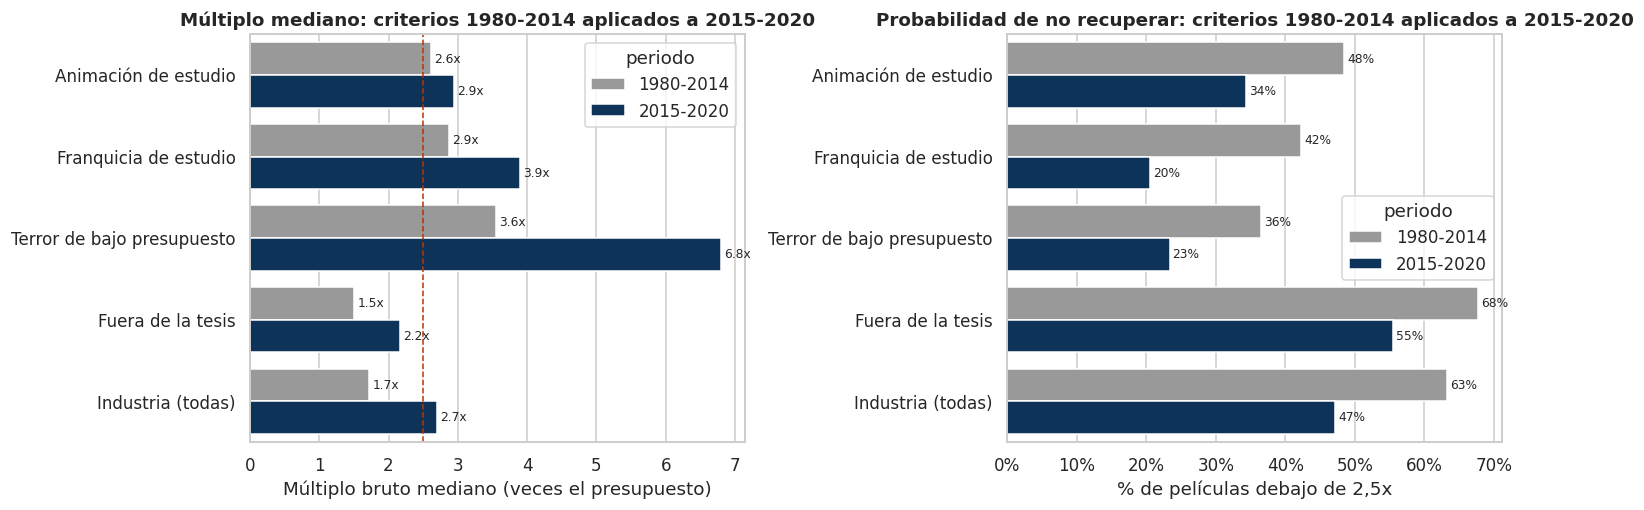

In [85]:
figura, ejes = plt.subplots(1, 2, figsize=(14, 4.8))
orden = ARQUETIPOS_TESIS + ["Fuera de la tesis", "Industria (todas)"]
datos_grafico = fuera_de_muestra.reset_index().query("arquetipo in @orden")
for eje, metrica, titulo, formato in [(ejes[0], "multiplo_mediano", "Múltiplo mediano", "{:.1f}x"),
                                      (ejes[1], "prob_perdida", "Probabilidad de no recuperar", "{:.0%}")]:
    sns.barplot(data=datos_grafico, y="arquetipo", x=metrica, hue="periodo", order=orden, ax=eje,
                palette=[GRIS, AZUL])
    for contenedor in eje.containers:
        eje.bar_label(contenedor, labels=[formato.format(valor) for valor in contenedor.datavalues], fontsize=8, padding=2)
    eje.set_title(f"{titulo}: criterios 1980-2014 aplicados a 2015-2020")
    eje.set_ylabel("")
ejes[0].axvline(UMBRAL_RECUPERO, color=ROJO, ls="--", lw=1)
ejes[0].set_xlabel("Múltiplo bruto mediano (veces el presupuesto)")
ejes[1].set_xlabel("% de películas debajo de 2,5x")
ejes[1].xaxis.set_major_formatter(mticker.PercentFormatter(1))
figura.tight_layout()
guardar_figura(figura, "08_validacion_fuera_de_muestra.png")
plt.show()

**Conclusión.** La tesis supera esta primera validación fuera de muestra: los tres arquetipos mantienen una menor probabilidad de pérdida que la industria entre 2015 y 2020.

- **Franquicias:** la probabilidad de pérdida disminuye del 42% al 20%, con una ventaja de 27 puntos porcentuales frente a la industria.
- **Terror de bajo presupuesto:** la probabilidad de pérdida baja del 36% al 23%, manteniendo una ventaja de 24 puntos.
- **Animación:** la probabilidad de pérdida disminuye del 48% al 34%, con una ventaja de 13 puntos.

Aunque todos los segmentos mejoraron, los tres seleccionados conservaron su ventaja relativa. Esto respalda la estrategia propuesta, aunque no garantiza que los resultados se mantengan en el futuro.

#6.2 El portafolio completo, simulado con las películas de 2015-2020

En esta sección evaluamos cómo habría funcionado el portafolio completo utilizando películas de 2015–2020. Mantenemos la estrategia definida anteriormente y comparamos sus resultados con los de una cartera de películas seleccionadas al azar.

In [86]:
multiplos_prueba = {arquetipo: prueba.loc[prueba["arquetipo"] == arquetipo, "multiplo_bruto"].clip(upper=TOPE_MULTIPLO).to_numpy()
                    for arquetipo in ARQUETIPOS_TESIS}
multiplos_prueba["Mercado"] = prueba["multiplo_bruto"].clip(upper=TOPE_MULTIPLO).to_numpy()
filas = []
for nombre in ["Propuesta (3 arquetipos)", "Mercado: películas al azar"]:
    for periodo, multiplos in [("1980-2014 (entrenamiento)", multiplos_con_mercado), ("2015-2020 (prueba)", multiplos_prueba)]:
        _, resumen = evaluar_cartera(ALTERNATIVAS[nombre], multiplos)
        filas.append({"cartera": nombre, "periodo": periodo, **resumen})
simulacion_oos = pd.DataFrame(filas).set_index(["cartera", "periodo"])
display(simulacion_oos.style.format("{:+.1%}").format("{:.1%}", subset=["prob_perder_capital", "prob_perder_mas_20pct"]))

# Lo que efectivamente hubiera pasado financiando TODAS las películas de cada arquetipo en 2015-2020
# (con la misma participación): suma de lo recuperado sobre suma de lo invertido, sin tope.
realizado = (
    prueba[prueba["arquetipo"].isin(ARQUETIPOS_TESIS)]
    .groupby("arquetipo")
    .agg(peliculas=("titulo", "size"), recaudacion=("recaudacion_real", "sum"), presupuesto=("presupuesto_real", "sum"))
)
realizado["retorno_agregado"] = realizado["recaudacion"] / (UMBRAL_RECUPERO * realizado["presupuesto"]) - 1
print("Retorno agregado realizado 2015-2020 (todas las películas del arquetipo, ponderado por presupuesto, sin tope):")
print(realizado[["peliculas", "retorno_agregado"]].assign(
    retorno_agregado=realizado["retorno_agregado"].map("{:+.0%}".format)).to_string())

Retorno agregado realizado 2015-2020 (todas las películas del arquetipo, ponderado por presupuesto, sin tope):
                            peliculas retorno_agregado
arquetipo                                             
Animación de estudio               32             +65%
Franquicia de estudio              83             +72%
Terror de bajo presupuesto         30            +346%


**Conclusión.** La estrategia mantiene su ventaja fuera de muestra. Entre 2015 y 2020, el portafolio propuesto alcanza un retorno mediano simulado del 70,6%, frente al 36,9% de una cartera de películas al azar. Además, su probabilidad de pérdida es del 3,9%, frente al 19,3% del mercado.

Esto demuestra que la selección de arquetipos sigue aportando valor incluso en un período favorable para toda la industria. No obstante, estos resultados corresponden a simulaciones con películas históricas, no a rendimientos efectivamente obtenidos por el fondo.

#6.3 ¿Se mantiene el ranking de segmentos? y robustez sin 2020

En esta sección verificamos si los segmentos que tuvieron mejores resultados entre 1980 y 2014 siguieron siendo los más rentables entre 2015 y 2020. También analizamos si excluir 2020, por ser el año de la pandemia, modifica las conclusiones.

In [87]:
# Estabilidad del ranking: ¿los segmentos buenos hasta 2014 siguieron siendo buenos?
segmentos_prueba = resumir_retorno(prueba, ["genero_analisis", "tramo_presupuesto"], minimo_peliculas=15)
segmentos_prueba.index = [f"{genero} · {tramo}" for genero, tramo in segmentos_prueba.index]
comunes = segmentos_entrenamiento.index.intersection(segmentos_prueba.index)
rho_retorno, p_retorno = stats.spearmanr(segmentos_entrenamiento.loc[comunes, "multiplo_mediano"],
                                         segmentos_prueba.loc[comunes, "multiplo_mediano"])
rho_riesgo, p_riesgo = stats.spearmanr(segmentos_entrenamiento.loc[comunes, "prob_perdida"],
                                       segmentos_prueba.loc[comunes, "prob_perdida"])
print(f"Segmentos comparables (n>=30 en entrenamiento y n>=15 en prueba): {len(comunes)}")
print(f"Correlación de rangos entrenamiento vs prueba -> múltiplo mediano: rho = {rho_retorno:.2f} (p = {p_retorno:.3f}) | "
      f"prob. de pérdida: rho = {rho_riesgo:.2f} (p = {p_riesgo:.3f})")

# Robustez: 2020 tiene pocas películas y la pandemia. ¿Cambia algo si se excluye?
prueba_sin_2020 = prueba[prueba["anio_estreno"] < 2020]
print("\nPrueba sin 2020:")
print(resumir_retorno(prueba_sin_2020, "arquetipo").loc[ARQUETIPOS_TESIS + ["Fuera de la tesis"],
      ["peliculas", "multiplo_mediano", "prob_perdida", "retorno_peor_decil"]].round(2).to_string())

Segmentos comparables (n>=30 en entrenamiento y n>=15 en prueba): 15
Correlación de rangos entrenamiento vs prueba -> múltiplo mediano: rho = 0.63 (p = 0.012) | prob. de pérdida: rho = 0.58 (p = 0.024)

Prueba sin 2020:
                            peliculas  multiplo_mediano  prob_perdida  retorno_peor_decil
arquetipo                                                                                
Animación de estudio               32              2.94          0.34               -0.70
Franquicia de estudio              83              3.89          0.20               -0.22
Terror de bajo presupuesto         30              6.80          0.23               -0.78
Fuera de la tesis                 427              2.16          0.56               -0.83


**Conclusión.** Los resultados confirman que los segmentos seleccionados mantienen su buen desempeño fuera de muestra. Las correlaciones positivas y estadísticamente significativas, tanto en rentabilidad (0,63) como en riesgo (0,58), indican que los segmentos que eran más atractivos históricamente tienden a conservar su ventaja entre 2015 y 2020.

Además, al excluir 2020, los resultados de los tres arquetipos elegidos permanecen iguales, lo que demuestra que sus conclusiones no dependen de ese año excepcional. En conjunto, esto aporta mayor respaldo a la estrategia de inversión, aunque sigue existiendo incertidumbre sobre su desempeño futuro.

# Etapa 7 · Análisis de sensibilidad

En esta etapa analizamos qué pasa con la cartera que elegimos cuando cambiamos algunos supuestos del modelo. La idea es comprobar si sigue siendo rentable en distintos escenarios o si los resultados dependen demasiado de ciertas condiciones.

## 7.1 Umbral de recupero

En el análisis usamos un múltiplo de 2,5× como referencia para recuperar la inversión. Sin embargo, este valor puede cambiar según los gastos de marketing y la parte de la recaudación que recibe la productora.

Por ejemplo, si suponemos que el exhibidor se queda con el 50% de la recaudación y que el marketing cuesta la mitad del presupuesto, necesitamos recaudar 3 veces el presupuesto para cubrir esos costos. Si el marketing cuesta lo mismo que el presupuesto, el múltiplo necesario sube a 4×.

Por eso, analizamos cómo cambian los resultados de nuestra cartera con estos distintos umbrales.

In [94]:
filas_sensibilidad = []

# 1. Cambios en el umbral de recupero
escenarios_umbral = [
    ("Caso base (2,5x)", 2.5),
    ("Umbral 3x (marketing 50%)", 3.0),
    ("Umbral 4x (marketing 100%)", 4.0)
]
for nombre, umbral in escenarios_umbral:
    _, resumen = evaluar_cartera(
        cartera_propuesta,
        multiplos_entrenamiento,
        umbral=umbral
    )
    filas_sensibilidad.append({"escenario": nombre, **resumen})

# 2. Sin shock de mercado
_, resumen = evaluar_cartera(
    cartera_propuesta,
    multiplos_entrenamiento,
    factores=None
)
filas_sensibilidad.append({
    "escenario": "Sin shock de mercado",
    **resumen
})

# 3. Cambios en el tope de retornos extremos
for percentil in [0.90, 0.99, None]:
    tope = (
        entrenamiento["multiplo_bruto"].quantile(percentil)
        if percentil is not None else np.inf
    )
    multiplos = {
        arquetipo: entrenamiento.loc[
            entrenamiento["arquetipo"] == arquetipo,
            "multiplo_bruto"
        ].clip(upper=tope).to_numpy()
        for arquetipo in ARQUETIPOS_TESIS
    }
    _, resumen = evaluar_cartera(cartera_propuesta, multiplos)
    nombre = (
        f"Tope p{int(percentil * 100)} ({tope:.1f}x)"
        if percentil is not None else "Sin tope"
    )
    filas_sensibilidad.append({
        "escenario": nombre,
        **resumen
    })

# 4. Sin películas de micropresupuesto
sin_micro = entrenamiento[
    ~entrenamiento["titulo"].isin(MICROPRESUPUESTOS_VERIFICADOS)
]
multiplos = {
    arquetipo: sin_micro.loc[
        sin_micro["arquetipo"] == arquetipo,
        "multiplo_bruto"
    ].clip(upper=TOPE_MULTIPLO).to_numpy()
    for arquetipo in ARQUETIPOS_TESIS
}

_, resumen = evaluar_cartera(cartera_propuesta, multiplos)
filas_sensibilidad.append({
    "escenario": "Sin micropresupuestos verificados",
    **resumen
})

# 5. Comparación con películas al azar
for umbral in [2.5, 3.0, 4.0]:
    _, resumen = evaluar_cartera(
        ALTERNATIVAS["Mercado: películas al azar"],
        multiplos_con_mercado,
        umbral=umbral
    )
    filas_sensibilidad.append({
        "escenario": f"Películas al azar (umbral {umbral:g}x)",
        **resumen
    })

# 6. Tabla final
sensibilidad = pd.DataFrame(filas_sensibilidad).set_index("escenario")
sensibilidad.to_csv(CARPETA_SALIDAS / "sensibilidad_portafolio.csv")
display(
    sensibilidad.style
    .format("{:+.1%}")
    .format(
        "{:.1%}",
        subset=["prob_perder_capital", "prob_perder_mas_20pct"]
    )
    .background_gradient(
        subset=["prob_perder_capital"],
        cmap="Reds"
    )
)


,retorno_mediano,retorno_medio,prob_perder_capital,prob_perder_mas_20pct,percentil_5,percentil_10,percentil_90
escenario,,,,,,,
"Caso base (2,5x)",+38.8%,+44.1%,18.3%,4.7%,-19.6%,-10.2%,+106.5%
Umbral 3x (marketing 50%),+15.7%,+20.1%,36.0%,14.8%,-33.0%,-25.2%,+72.1%
Umbral 4x (marketing 100%),-13.2%,-9.9%,64.8%,42.1%,-49.7%,-43.9%,+29.1%
Sin shock de mercado,+44.7%,+45.4%,0.8%,0.0%,+13.1%,+19.9%,+72.2%
Tope p90 (6.8x),+26.6%,+30.5%,27.6%,8.7%,-25.4%,-18.0%,+84.3%
Tope p99 (30.9x),+64.1%,+72.2%,8.0%,1.4%,-7.1%,+4.0%,+151.3%
Sin tope,+92.1%,+831.7%,5.4%,1.0%,-1.3%,+11.2%,+2807.3%
Sin micropresupuestos verificados,+38.4%,+43.6%,18.7%,4.9%,-19.7%,-10.8%,+104.6%
Películas al azar (umbral 2.5x),-2.3%,+3.4%,52.2%,29.8%,-44.5%,-37.7%,+52.3%


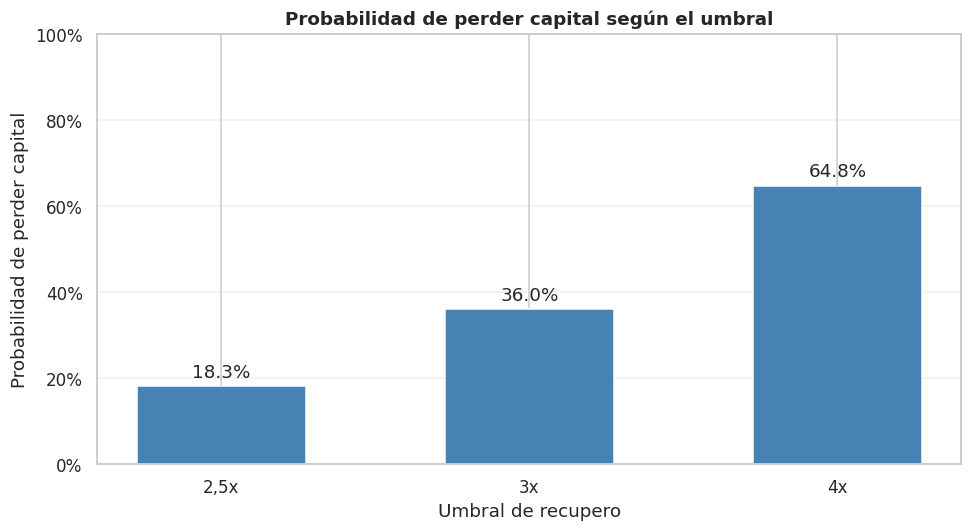

In [93]:
# Probabilidad de perder capital según el umbral
escenarios = [
    "Caso base (2,5x)",
    "Umbral 3x (marketing 50%)",
    "Umbral 4x (marketing 100%)"
]
probabilidades = sensibilidad.loc[
    escenarios, "prob_perder_capital"
]

plt.figure(figsize=(9, 5))

barras = plt.bar(
    ["2,5x", "3x", "4x"],
    probabilidades,
    color="steelblue",
    width=0.55
)
plt.title("Probabilidad de perder capital según el umbral")
plt.xlabel("Umbral de recupero")
plt.ylabel("Probabilidad de perder capital")
plt.ylim(0, 1)

plt.gca().yaxis.set_major_formatter(
    mticker.PercentFormatter(1)
)

# Mostrar el porcentaje sobre cada barra
for barra, probabilidad in zip(barras, probabilidades):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        probabilidad + 0.02,
        f"{probabilidad:.1%}",
        ha="center"
    )
plt.grid(axis="y", alpha=0.3)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()


**Conclusión del análisis de sensibilidad**

Los resultados muestran que, cuanto mayor es el umbral de recuperación, mayor es el riesgo de perder capital. En el escenario base, la probabilidad de pérdida es del 18,3%, pero aumenta al 36% con un umbral de 3x y al 64,8% con uno de 4x.

Esto significa que la cartera propuesta puede ser rentable, pero sus resultados dependen de los costos y de cuánto dinero recibe realmente el estudio por la recaudación de las películas.

Además, al comparar con películas elegidas al azar, nuestra selección presenta una menor probabilidad de pérdida en los tres escenarios. Por lo tanto, la estrategia de selección sigue siendo mejor que invertir al azar, aunque no elimina el riesgo.

#7.2 Cota pesimista por las películas sin presupuesto

In [89]:
# Las películas sin presupuesto son, sobre todo, chicas y poco vistas (1.9): si se hubieran podido medir,
# probablemente muchas serían pérdidas. Cota pesimista: suponemos que TODAS las películas sin presupuesto
# del mismo género (o franquicia) perdieron plata, y recalculamos la probabilidad de pérdida.
def cota_pesimista(filtro_base: pd.Series, filtro_sin_dato: pd.Series) -> tuple[float, float]:
    observadas = base[filtro_base & (base["anio_estreno"] <= ANIO_FIN_ENTRENAMIENTO)]
    faltantes_grupo = peliculas[filtro_sin_dato & peliculas["falta_presupuesto"] & (peliculas["anio_estreno"] <= ANIO_FIN_ENTRENAMIENTO)]
    perdidas = (~observadas["recupero_inversion"]).sum() + len(faltantes_grupo)
    return 1 - observadas["recupero_inversion"].mean(), perdidas / (len(observadas) + len(faltantes_grupo))


casos = {
    "Terror (todo el género)": (base["genero"].isin(["Terror", "Suspenso"]), peliculas["genero"].isin(["Terror", "Suspenso"])),
    "Animación (todo el género)": (base["genero"] == "Animación", peliculas["genero"] == "Animación"),
    "Franquicias (todas)": (base["es_secuela"], peliculas["es_secuela"]),
    "Industria": (base["genero"].notna(), peliculas["genero"].notna()),
}
cotas = pd.DataFrame({nombre: dict(zip(["prob_perdida_observada", "prob_perdida_pesimista"], cota_pesimista(*filtros)))
                      for nombre, filtros in casos.items()}).T
cotas["diferencia_pp"] = (cotas["prob_perdida_pesimista"] - cotas["prob_perdida_observada"]) * 100
cotas.style.format({"prob_perdida_observada": "{:.0%}", "prob_perdida_pesimista": "{:.0%}", "diferencia_pp": "{:+.0f}"})

,prob_perdida_observada,prob_perdida_pesimista,diferencia_pp
Terror (todo el género),45%,56%,+11
Animación (todo el género),45%,56%,+10
Franquicias (todas),45%,57%,+11
Industria,63%,74%,+11


**Conclusión Películas sin presupuesto**

Para evaluar cómo afectan los datos faltantes, consideramos el peor escenario posible: que todas las películas sin presupuesto conocido hayan generado pérdidas.

Los resultados muestran que la probabilidad de pérdida aumenta aproximadamente 11 puntos porcentuales en todos los grupos. Sin embargo, terror, animación y franquicias siguen teniendo un menor porcentaje de pérdidas que la industria en general.

Por lo tanto, aunque los datos faltantes afectan los resultados, no cambian la conclusión principal sobre estos grupos.

**Conclusión: qué tan robusto es el número.**

| Supuesto que se cambia | Retorno mediano | Prob. de perder capital |
|---|---|---|
| Caso base | +39% | 18% |
| Umbral 3× (marketing 50%) | +16% | 36% |
| Umbral 4× (marketing 100%, sin otros ingresos) | −13% | 65% |
| Películas independientes (sin shock de mercado) | +45% | 1% |
| Tope de cola más estricto (6,8×) | +27% | 28% |
| Tope más laxo (31×) | +64% | 8% |
| Sin micropresupuestos verificados | +38% | 19% |

**Conclusión general: análisis de sensibilidad**

El análisis de sensibilidad muestra que nuestra cartera puede ser rentable, pero depende de los supuestos utilizados. En el escenario base, el retorno mediano es de **+38,8%** y la probabilidad de perder capital es del **18,3%**. Sin embargo, cuando aumentamos el umbral de recuperación a 4x, el riesgo sube al 64,8%.

También observamos que los resultados cambian cuando modificamos las condiciones del mercado y los límites de los retornos extremos. En cambio, excluir las películas con presupuestos muy bajos casi no afecta los resultados. Además, aunque los datos faltantes aumentan el porcentaje de pérdidas, los grupos seleccionados siguen mostrando mejores resultados que la industria.

**En conclusión, nuestra estrategia obtiene mejores resultados que elegir películas al azar, pero no garantiza ganancias.** Por eso, antes de invertir, es importante considerar los costos reales y los riesgos del mercado.

#Etapa 8 · Conclusiones para el comité y exportación

**Recomendación al comité de inversiones**

1. **Invertir los USD 500 MM en tres arquetipos**: 65% franquicias de estudio (co-financiación del 25%), 20% animación
   de estudio (25%) y 15% terror de bajo presupuesto (100% de cada proyecto). Son 30 proyectos en 3 años.
2. **Expectativa honesta**: retorno mediano **+39%** sobre el capital, con **18% de probabilidad de perder capital** y
   una pérdida de 20% o más en el peor 5% de los escenarios. Validado fuera de muestra: en 2015-2020 la misma cartera
   habría tenido +71% y 4% de probabilidad de pérdida.
3. **No financiar** policiales, dramas, biografías ni comedias/acción originales de presupuesto medio: son el 68% de la
   producción y pierden plata en 65-75% de los casos.
4. **No concentrar en el mejor segmento**: el terror barato rinde más, pero no hay suficientes proyectos y su ventaja
   depende de pocos éxitos.
5. **Condición para invertir**: contratos con participación en ingresos fuera de salas. Sin esos ingresos, en el escenario de umbral 4x, nuestra cartera presenta un retorno mediano negativo del 13,2%

In [90]:
# Números clave para la presentación, todos calculados arriba (trazabilidad celda -> diapositiva)
terror_base = base[base["genero_analisis"] == "Terror"]
numeros_comite = pd.Series({
    "Películas en la base original": bitacora.filas_originales,
    "Películas únicas tras la limpieza": len(peliculas),
    "Películas con retorno medible": len(base),
    "% de películas que NO recupera la inversión (industria)": f"{1 - base['recupero_inversion'].mean():.0%}",
    "Múltiplo promedio del terror (lo que el CIO no cree)": f"{terror_base['multiplo_bruto'].mean():.0f}x",
    "Múltiplo mediano del terror (el que se sostiene)": f"{terror_base['multiplo_bruto'].median():.1f}x",
    "Proyectos del portafolio propuesto": int(cartera_propuesta["proyectos"].sum()),
    "Retorno mediano del portafolio (simulación)": f"{resumen_propuesta['retorno_mediano']:+.0%}",
    "Probabilidad de perder capital (portafolio)": f"{resumen_propuesta['prob_perder_capital']:.1%}",
    "Peor 5% de escenarios (percentil 5)": f"{resumen_propuesta['percentil_5']:+.0%}",
    "Probabilidad de perder capital con umbral 4x": f"{sensibilidad.loc['Umbral 4x (marketing 100%)', 'prob_perder_capital']:.1%}",
    "Probabilidad de perder capital eligiendo películas al azar": f"{comparacion_carteras.loc['Mercado: películas al azar', 'prob_perder_capital']:.1%}",
})
numeros_comite.to_csv(CARPETA_SALIDAS / "numeros_para_el_comite.csv", header=["valor"])
numeros_comite.to_frame("valor")

,valor
Películas en la base original,7740
Películas únicas tras la limpieza,7668
Películas con retorno medible,5389
% de películas que NO recupera la inversión (industria),61%
Múltiplo promedio del terror (lo que el CIO no cree),77x
Múltiplo mediano del terror (el que se sostiene),3.1x
Proyectos del portafolio propuesto,30
Retorno mediano del portafolio (simulación),+39%
Probabilidad de perder capital (portafolio),18.3%
Peor 5% de escenarios (percentil 5),-20%


In [91]:
# Exportación de las bases y tablas finales
peliculas.to_csv(CARPETA_SALIDAS / "peliculas_limpio.csv", index=False)
base.to_csv(CARPETA_SALIDAS / "base_analitica_retorno.csv", index=False)
cartera_propuesta.to_csv(CARPETA_SALIDAS / "cartera_propuesta.csv")
print("Archivos generados en salidas/:")
for archivo in sorted(CARPETA_SALIDAS.rglob("*")):
    if archivo.is_file():
        print(f"  {archivo.relative_to(CARPETA_SALIDAS)}  ({archivo.stat().st_size / 1024:,.0f} KB)")

Archivos generados en salidas/:
  base_analitica_retorno.csv  (2,055 KB)
  bitacora_limpieza.csv  (2 KB)
  cartera_propuesta.csv  (1 KB)
  comparacion_carteras.csv  (1 KB)
  figuras/01_cobertura_temporal.png  (114 KB)
  figuras/02_mapa_calor_correlaciones.png  (130 KB)
  figuras/03_industria_nominal_vs_real.png  (133 KB)
  figuras/04_distribucion_retorno.png  (126 KB)
  figuras/05_generos_ordenados.png  (113 KB)
  figuras/06_presupuesto_vs_recaudacion_hexbin.png  (201 KB)
  figuras/07_simulacion_y_diversificacion.png  (246 KB)
  figuras/08_validacion_fuera_de_muestra.png  (113 KB)
  figuras/distribucion_capital.png  (68 KB)
  numeros_para_el_comite.csv  (1 KB)
  peliculas_limpio.csv  (2,538 KB)
  peliculas_presupuesto_recaudacion.html  (583 KB)
  plano_riesgo_retorno.html  (30 KB)
  sensibilidad_portafolio.csv  (2 KB)
  tabla_riesgo_retorno_segmentos.csv  (6 KB)
  validacion_fuera_de_muestra.csv  (2 KB)


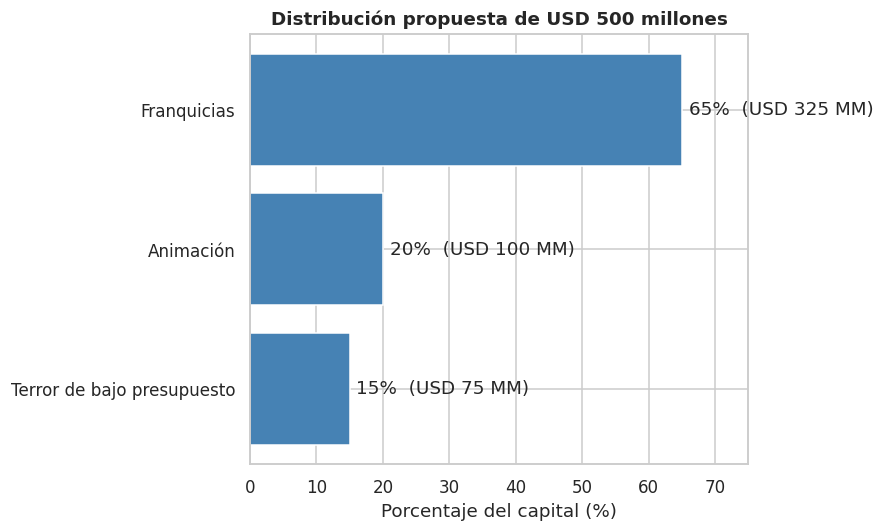

In [95]:
# Distribución propuesta de la inversión
import matplotlib.pyplot as plt

categorias = [
    "Franquicias",
    "Animación",
    "Terror de bajo presupuesto"
]

porcentajes = [65, 20, 15]

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.barh(categorias, porcentajes, color="steelblue")

ax.invert_yaxis()
ax.set_xlim(0, 75)
ax.set_xlabel("Porcentaje del capital (%)")
ax.set_title("Distribución propuesta de USD 500 millones")

for barra, porcentaje in zip(barras, porcentajes):
    ax.text(
        porcentaje + 1,
        barra.get_y() + barra.get_height() / 2,
        f"{porcentaje}%  (USD {porcentaje * 5:.0f} MM)",
        va="center"
    )

plt.tight_layout()
plt.show()

### Riesgos y condiciones para invertir

Antes de aprobar la inversión, el comité debería considerar tres aspectos:

- **Costos reales:** confirmar los gastos de producción, marketing y distribución, y negociar la participación en ingresos fuera de salas.
- **Riesgo de mercado:** considerar que varias películas pueden tener malos resultados al mismo tiempo.
- **Diversificación:** mantener la inversión distribuida entre los tres tipos de películas para no depender de unos pocos éxitos.

### Decisión final

**Recomendamos avanzar con la cartera propuesta de USD 500 millones, pero de forma condicionada.**

Los resultados muestran que seleccionar películas según su género, presupuesto y tipo de producción puede ofrecer mejores resultados que invertir al azar.

Sin embargo, la rentabilidad depende de los costos reales y de las condiciones del mercado. Por eso, recomendamos confirmar los contratos de distribución y los costos antes de comprometer el capital.

La propuesta busca combinar rentabilidad y diversificación, evitando depender únicamente de películas con retornos extraordinarios.